# Predicting the 24-Month Value of Subscription Cohorts with PyMC

Suppose that we run a subscription app with a free trial. After the trial, a user can pay $\$9.99$ per month or $\$69.99$ per year, and the yearly plan renews after $12$ months. The marketing team buys trial starts from ad networks and asks two questions:

- How much revenue does a trial that starts this month bring over the next two years? This tells the team how much it can pay for a trial.
- How much revenue will each recent cohort of users bring over its first two years? This tells the team whether the campaigns of the last months paid off.

Both questions are about revenue that we have not seen yet. A cohort that started last month has paid once, and most of its two years of revenue is still to come. A forecast of this revenue is often called a predicted lifetime value (pLTV).

Three properties of a subscription make this forecast hard:

- **Two payment schedules:** The monthly plan pays every month until the user cancels. The yearly plan pays once up front and once more if the user renews.
- **Churn that falls with age:** The users who churn easily leave first, and the ones who remain churn less. [Fader and Hardie (2007)](https://doi.org/10.1002/dir.20074) show that differences between users explain this pattern. A churn rate from the first months therefore overstates the churn later on.
- **Cohorts of different quality:** The mix of ad networks changes from month to month, and the users that it brings change with it. In this notebook we assume that a cohort that converts worse than usual also tends to churn more and to renew less. The season and a promotion every November, which advertises the yearly plan, move several steps of the funnel as well.

This notebook builds on the post [Cohort Revenue & Retention Analysis: A Bayesian Approach](https://juanitorduz.github.io/revenue_retention/), where we model the retention and the revenue of each cohort in one PyMC model. In that post the revenue follows a Gamma distribution whose shape grows with the number of active users, and we do the same here. We replace its BART model of the retention (a sum of regression trees) with a regression on the churn of each month, and we add the other steps of a subscription funnel.

We use the following references:

- [Fader and Hardie (2007)](https://doi.org/10.1002/dir.20074) for the shifted-beta-geometric model of churn, which we use to generate the data.
- [Allison (1982)](https://doi.org/10.2307/270718) for discrete-time hazard models, which are logistic regressions on the users at risk in each period.
- [Vaupel, Manton and Stallard (1979)](https://doi.org/10.2307/2061224) for the way differences between individuals change the hazard of a group over time.
- [Lewandowski, Kurowicka and Joe (2009)](https://doi.org/10.1016/j.jmva.2009.04.008) for the LKJ distribution, which is our prior for the correlation between the steps of a cohort.

In this notebook we model each step of the funnel with a generalized linear model (GLM): the conversion of a trial into a paying user, the choice of plan, the refunds, the monthly churn, the yearly renewal and the amount of each payment. The conversion, the churn and the renewal share the quality of the cohort, so the first payments of a cohort inform the steps that it has not reached yet.

We fit all the steps in one PyMC model. We write it with [PyMC-Forecast](https://pymc-labs.github.io/pymc-forecast/), a package from PyMC Labs for forecasting models, so that the model that we fit also draws the future payments of each cohort. From the posterior we get the value of a trial and the revenue of each cohort.

We work on synthetic data, so we know the true value of a trial and the true revenue of every cohort, and we can check the model against both.

Then we replay the forecast at the end of every month of 2024 and compare it with two references. The first one is the chain ladder method on the active users, which projects a cohort with the retention of the cohorts that came before it. The second one is the forecast that we would make if we knew the true parameters of every cohort.

We keep the business simple on purpose, and *The Subscription Funnel* section lists the assumptions. For a model of the individual customer instead of the cohort, see [BG/NBD Model in PyMC](https://juanitorduz.github.io/bg_nbd_pymc/).

We assume that you have fitted a hierarchical model in PyMC before. We do not assume any background in survival analysis or in actuarial methods.

Here is the outline:

1. **Prepare Notebook.** We load the libraries and set the plotting defaults.
2. **The Subscription Funnel.** We define the funnel, the two quantities that we want to estimate and the assumptions. Then we work examples of survivor selection and of the quality of a cohort.
3. **Generate Data.** We simulate four years of monthly cohorts with a PyMC generator.
4. **Model Specification.** We write the funnel model with PyMC-Forecast and elicit its priors with PreliZ.
5. **Prior Predictive Checks.** We look at the retention that the priors imply.
6. **Model Fitting.** We sample the posterior, check the sampler and compare the parameters with their true values.
7. **Posterior Predictive Checks.** We compare the fitted retention with the data.
8. **Value per Trial.** We compare the value of a trial by start month with the truth.
9. **Cohort Forecasts.** We forecast the $24$-month revenue of each cohort.
10. **Backtest.** We repeat the forecast at $12$ past dates and compare its error with the two references.
11. **Conclusion.** We collect the key findings, the limitations of the model and our recommendations.
12. **Next Steps.** We list extensions of the model.
13. **Appendix.** We repeat the backtest on $6$ other draws of the generator.
14. **References.** We list the papers that we cite.

## Prepare Notebook

In [1]:
import logging
import warnings
from collections.abc import Callable
from enum import StrEnum
from functools import partial
from itertools import combinations
from typing import Final, NamedTuple, Protocol

import arviz as az
import graphviz as gr
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import preliz as pz
import pymc as pm
import pymc.dims as pmd
import pytensor.tensor as pt
import seaborn as sns
import xarray as xr
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import (
    MaxNLocator,
    MultipleLocator,
    PercentFormatter,
    StrMethodFormatter,
)
from pymc_forecast import (
    FORECAST_VAR,
    OBS_VAR,
    Horizon,
    build_model,
    fit_mcmc,
    forecast,
    null_covariates,
    predict,
    predict_in_sample,
)
from scipy.special import expit, logit

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%config InlineBackend.figure_format = "retina"

logging.getLogger("pymc").setLevel(logging.ERROR)
logging.getLogger("pytensor").setLevel(logging.ERROR)

## The Subscription Funnel

Let's fix the notation. A **cohort** $c$ is the group of users who start a trial in the same calendar month, and $m_c$ is that calendar month.

The **age** $a = 0, 1, \dots, H - 1$ of a cohort counts the months since its start, and we follow every cohort over a **horizon** of $H = 24$ months. The **promotion indicator** $z_c$ is $1$ for the cohorts that start in November, the month of the promotion, and $0$ otherwise.

A cohort moves through the funnel in the following steps:

1. **Trials.** $T_c$ users start a trial.
2. **Conversion.** $P_c$ of them pay at the end of the trial. We call them the **paying users**.
3. **Plan choice.** $Y_c$ of the paying users choose the yearly plan and the other $P_c - Y_c$ choose the monthly plan. We write $P_{c,k}$ for the paying users of plan $k$.
4. **Refunds.** $F_{c,k}$ paying users of plan $k$ get a refund of their first payment and leave. The remaining users are the **net starts** $N_{c,k} = P_{c,k} - F_{c,k}$.
5. **Monthly churn.** $A_{c,a}$ of the $N_{c,\text{monthly}}$ net starts are still **active** at age $a$ and pay at the start of that month, so $A_{c,0} = N_{c,\text{monthly}}$.
6. **Yearly renewal.** $Q_c$ of the $N_{c,\text{yearly}}$ net starts of the yearly plan renew at age $12$ and pay a second time.
7. **Payments.** Each payment brings an amount close to the list price of its plan.

The diagram below shows how the counts flow from one step to the next. The label of an arrow is the step that connects the two counts.

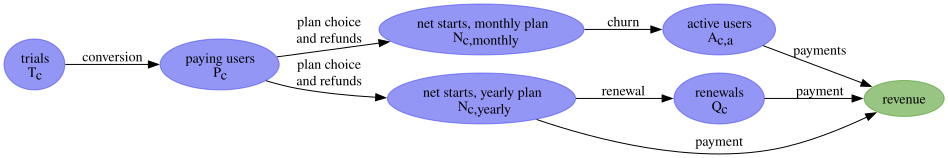

In [2]:
funnel = gr.Digraph(graph_attr={"rankdir": "LR"})
funnel.node(
    "trials", label="<trials<BR/>T<SUB>c</SUB>>", color="#2a2eec80", style="filled"
)
funnel.node(
    "paying",
    label="<paying users<BR/>P<SUB>c</SUB>>",
    color="#2a2eec80",
    style="filled",
)
funnel.node(
    "monthly",
    label="<net starts, monthly plan<BR/>N<SUB>c,monthly</SUB>>",
    color="#2a2eec80",
    style="filled",
)
funnel.node(
    "yearly",
    label="<net starts, yearly plan<BR/>N<SUB>c,yearly</SUB>>",
    color="#2a2eec80",
    style="filled",
)
funnel.node(
    "active",
    label="<active users<BR/>A<SUB>c,a</SUB>>",
    color="#2a2eec80",
    style="filled",
)
funnel.node(
    "renewed", label="<renewals<BR/>Q<SUB>c</SUB>>", color="#2a2eec80", style="filled"
)
funnel.node("revenue", label="revenue", color="#328c0680", style="filled")
funnel.edge("trials", "paying", label="conversion")
funnel.edge("paying", "monthly", label="plan choice\nand refunds")
funnel.edge("paying", "yearly", label="plan choice\nand refunds")
funnel.edge("monthly", "active", label="churn")
funnel.edge("yearly", "renewed", label="renewal")
funnel.edge("active", "revenue", label="payments")
funnel.edge("yearly", "revenue", label="payment")
funnel.edge("renewed", "revenue", label="payment")
funnel

The revenue comes from three counts: the active users of the monthly plan at every age, the net starts of the yearly plan and their renewals.

We describe the churn of the monthly plan with three related quantities:

- The **hazard** $h_c(a)$ at age $a \geq 1$ is the probability that a user of cohort $c$ who paid at age $a - 1$ does not pay at age $a$.
- The **one-month retention** $1 - h_c(a)$ is the probability that this user pays again.
- The **survival** $S_c(a)$ is the probability that a net start of the monthly plan is still active at age $a$.

The survival is the product of the one-month retentions so far:

$$
S_c(a) = \prod_{j=1}^{a} \left(1 - h_c(j)\right), \qquad S_c(0) = 1.
$$

Recall from the earlier post that the retention of a cohort is the share of its users who are active in a period. That quantity is the survival here.

We want to estimate two quantities. The first one is the **value per trial** $V_m$, the expected revenue over the horizon of one trial that starts in calendar month $m$. To write it down, we need the following probabilities of cohort $c$:

- $p^{\text{conv}}_c$ is the conversion probability.
- $p^{\text{year}}_c$ is the probability that a paying user chooses the yearly plan.
- $r_k$ is the refund probability of plan $k$.
- $p^{\text{renew}}_c$ is the renewal probability.

We also need the **average revenue per payment** $\mu_k$ of plan $k$. Each payment adds its average amount times the probability that it happens, so by the linearity of the expectation the expected revenue of one trial of cohort $c$ is

$$
V_c = p^{\text{conv}}_c \left[ \left(1 - p^{\text{year}}_c\right) \left(1 - r_{\text{monthly}}\right) \mu_{\text{monthly}} \sum_{a=0}^{H-1} S_c(a) + p^{\text{year}}_c \left(1 - r_{\text{yearly}}\right) \mu_{\text{yearly}} \left(1 + p^{\text{renew}}_c\right) \right].
$$

Note that $\sum_{a} S_c(a)$ is the expected number of payments of a net start of the monthly plan within the horizon.

The cohorts that start in the same calendar month are not equal, and we do not know how good a cohort is before it starts. We therefore define the value per trial as the average of $V_c$ over the cohorts that could start in month $m$:

$$
V_m = \text{E}\left[V_c \mid m_c = m\right].
$$

The second quantity is the **cohort revenue** $R_c$, the total revenue of cohort $c$ over its first $H$ months. At the time of the forecast we have seen the revenue of cohort $c$ up to its current age, and we have to predict the rest.

We make the following assumptions:

- **Monthly time unit:** A trial converts, or not, within the month in which it starts, and every payment happens at the start of a month of age.
- **Two plans, no changes:** A user keeps the plan that they choose after the trial.
- **Refunds only on the first payment:** A refunded user leaves and never pays again.
- **Horizon of $24$ months:** We value a trial by its revenue in its first two years, and we assume that this is the payback window of the marketing team. The users who remain after two years keep paying, so the value over a longer horizon is larger.
- **One renewal in the horizon:** The yearly plan pays at age $0$ and, if the user renews, at age $12$.
- **Stable funnel:** Apart from the season, the promotion and the quality of the cohort, the rates of the funnel do not change across cohorts.
- **Promotion every November:** The promotion runs in the same month every year. We can only separate its effect from a November effect if we assume that a November cohort without the promotion would behave like the cohorts of the other months.
- **Gross revenue:** We ignore app store fees, variable costs and the time value of money. The value per trial is therefore an upper bound on what we can pay for a trial.

Two properties of the cohorts drive the forecast, and we look at each of them before we generate data. The first one is about the users within a cohort.

### Survivor Selection

Suppose that every user has a constant churn probability $\theta$. A user with $\theta = 0.1$ cancels in any month with probability $0.1$, however long they have been subscribed.

Users differ, and we describe the spread of $\theta$ within a cohort by a $\text{Beta}(\alpha, \beta)$ distribution. This is the **shifted-beta-geometric (sBG) model** of Fader and Hardie (2007): the number of payments of a single user is geometric, and the Beta distribution mixes over the users.

How does the cohort change with age? A user with churn probability $\theta$ is still active at age $a$ with probability $(1 - \theta)^a$. By Bayes' theorem, the density $f$ of $\theta$ among the users who are still active is proportional to the Beta density times this probability:

$$
f(\theta \mid \text{active at age } a) \propto \theta^{\alpha - 1} (1 - \theta)^{\beta - 1} (1 - \theta)^{a} = \theta^{\alpha - 1} (1 - \theta)^{\beta + a - 1}.
$$

This means that the active users at age $a$ follow a $\text{Beta}(\alpha, \beta + a)$ distribution. The hazard of the cohort at age $a + 1$ is the mean churn probability of these users:

$$
h(a + 1) = \text{E}[\theta \mid \text{active at age } a] = \frac{\alpha}{\alpha + \beta + a}.
$$

**Remark (Notation).** Fader and Hardie (2007) work with the retention rate of a period, which is our one-month retention, and with the survivor function, which is our survival.

Let's work a simple example with $\alpha = 1$ and $\beta = 3$, the values of our generator. The mean churn probability of a new user is $1/4$. We plot the density of $\theta$ among the active users at a few ages.

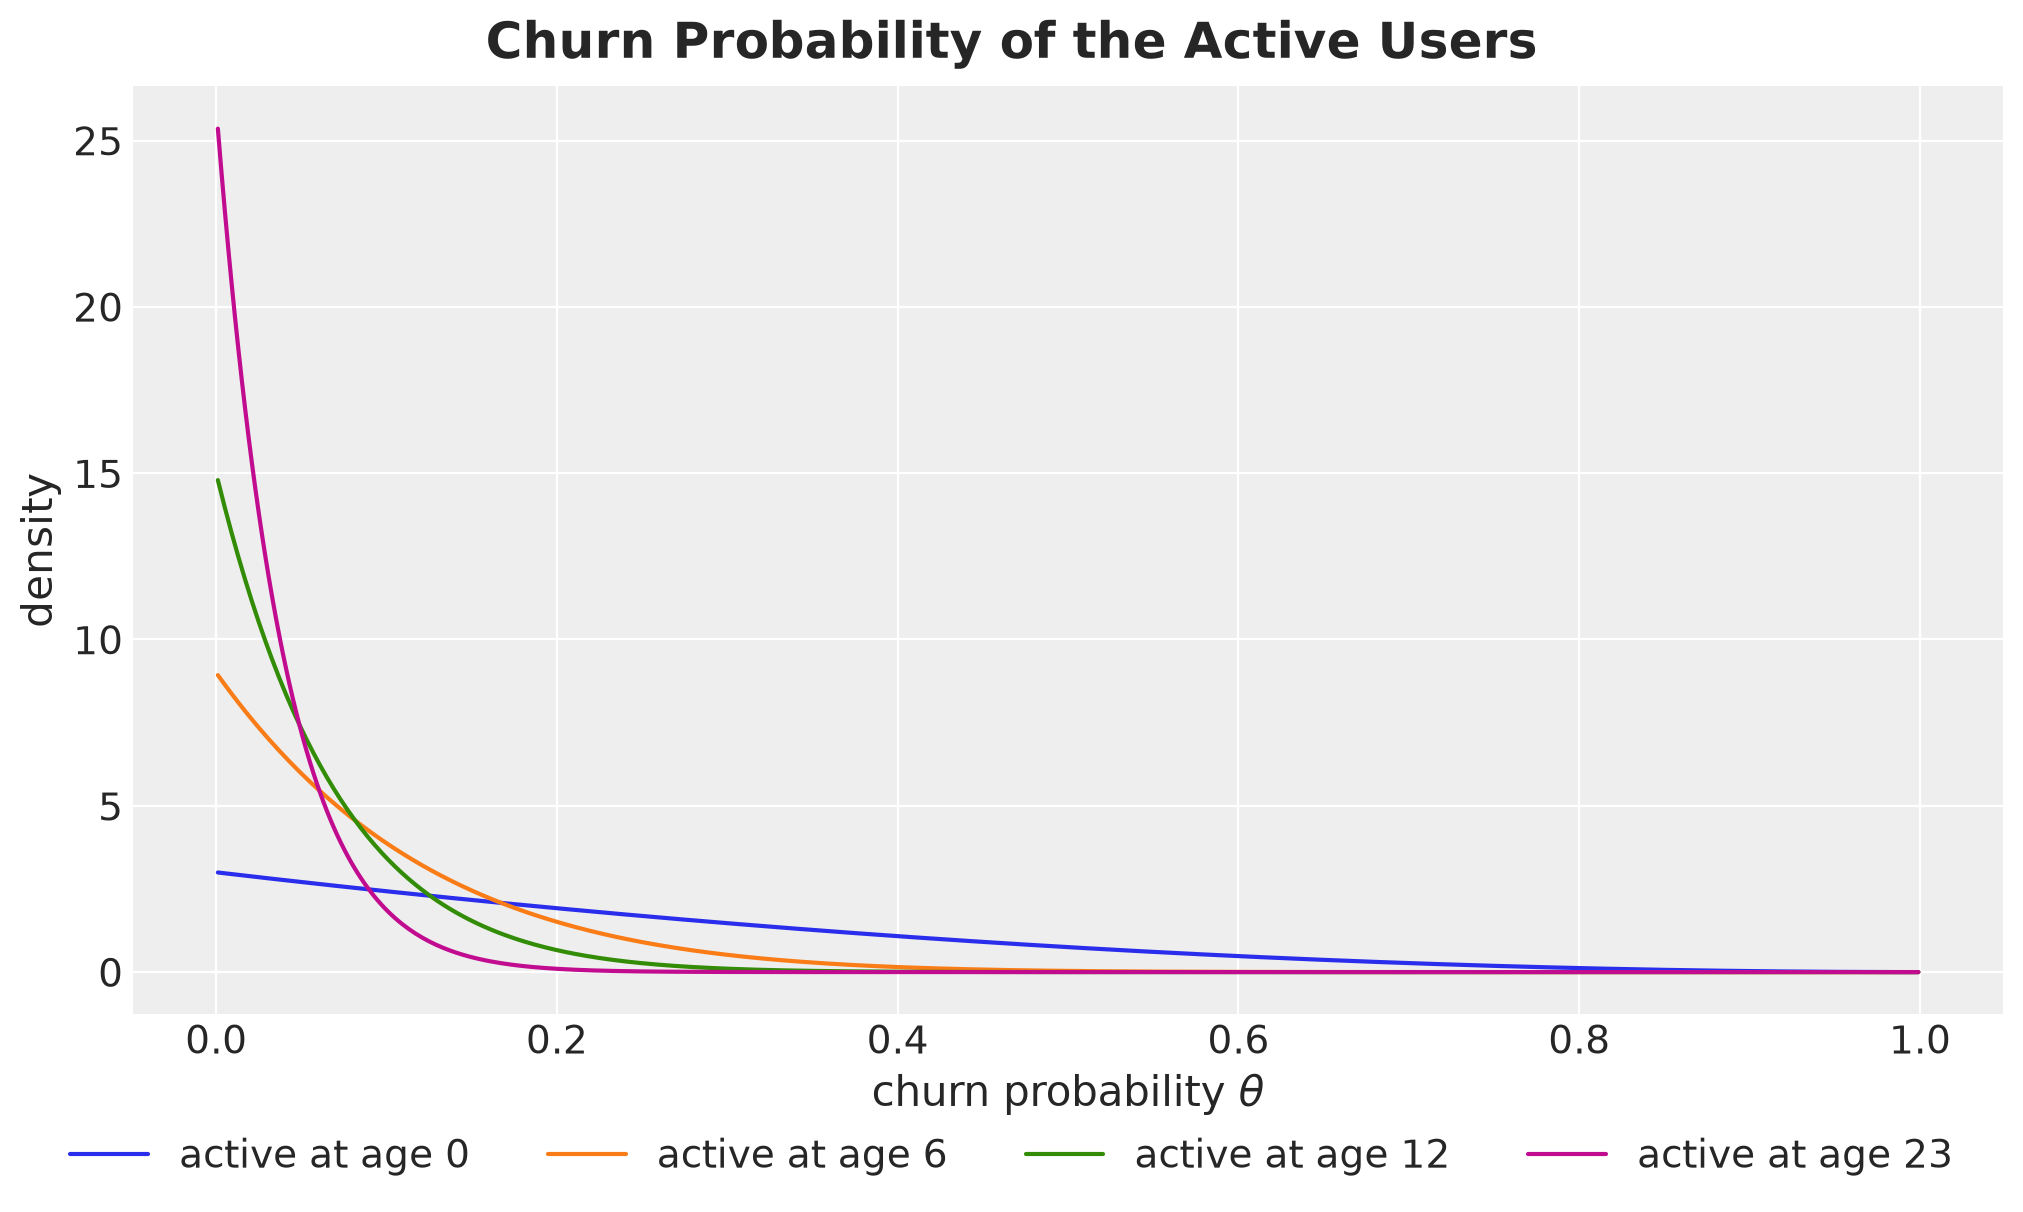

In [3]:
SBG_ALPHA: Final[float] = 1.0
SBG_BETA: Final[float] = 3.0
HORIZON: Final[int] = 24  # months of revenue per cohort, ages 0 to 23

theta_values = np.linspace(0.001, 0.999, 500)

fig, ax = plt.subplots()

for i, age in enumerate([0, 6, 12, HORIZON - 1]):
    density = pz.Beta(SBG_ALPHA, SBG_BETA + age).pdf(theta_values)
    ax.plot(theta_values, density, color=f"C{i}", label=f"active at age {age}")

ax.set(xlabel=r"churn probability $\theta$", ylabel="density")
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Churn Probability of the Active Users", fontsize=18, fontweight="bold");

The mass moves toward low churn probabilities as the cohort ages. No user changes their churn probability, but the users with a high $\theta$ leave first, and the ones who remain churn less. This is **survivor selection**.

Next, let's see what survivor selection does to the hazard and to the survival of the cohort. We compare the sBG cohort with a projection that keeps the churn of the first month, $h(1) = 1/4$, constant over the horizon. The legend gives the expected number of payments of a net start within the horizon, which is one plus the sum of the survival over the ages $1$ to $23$.

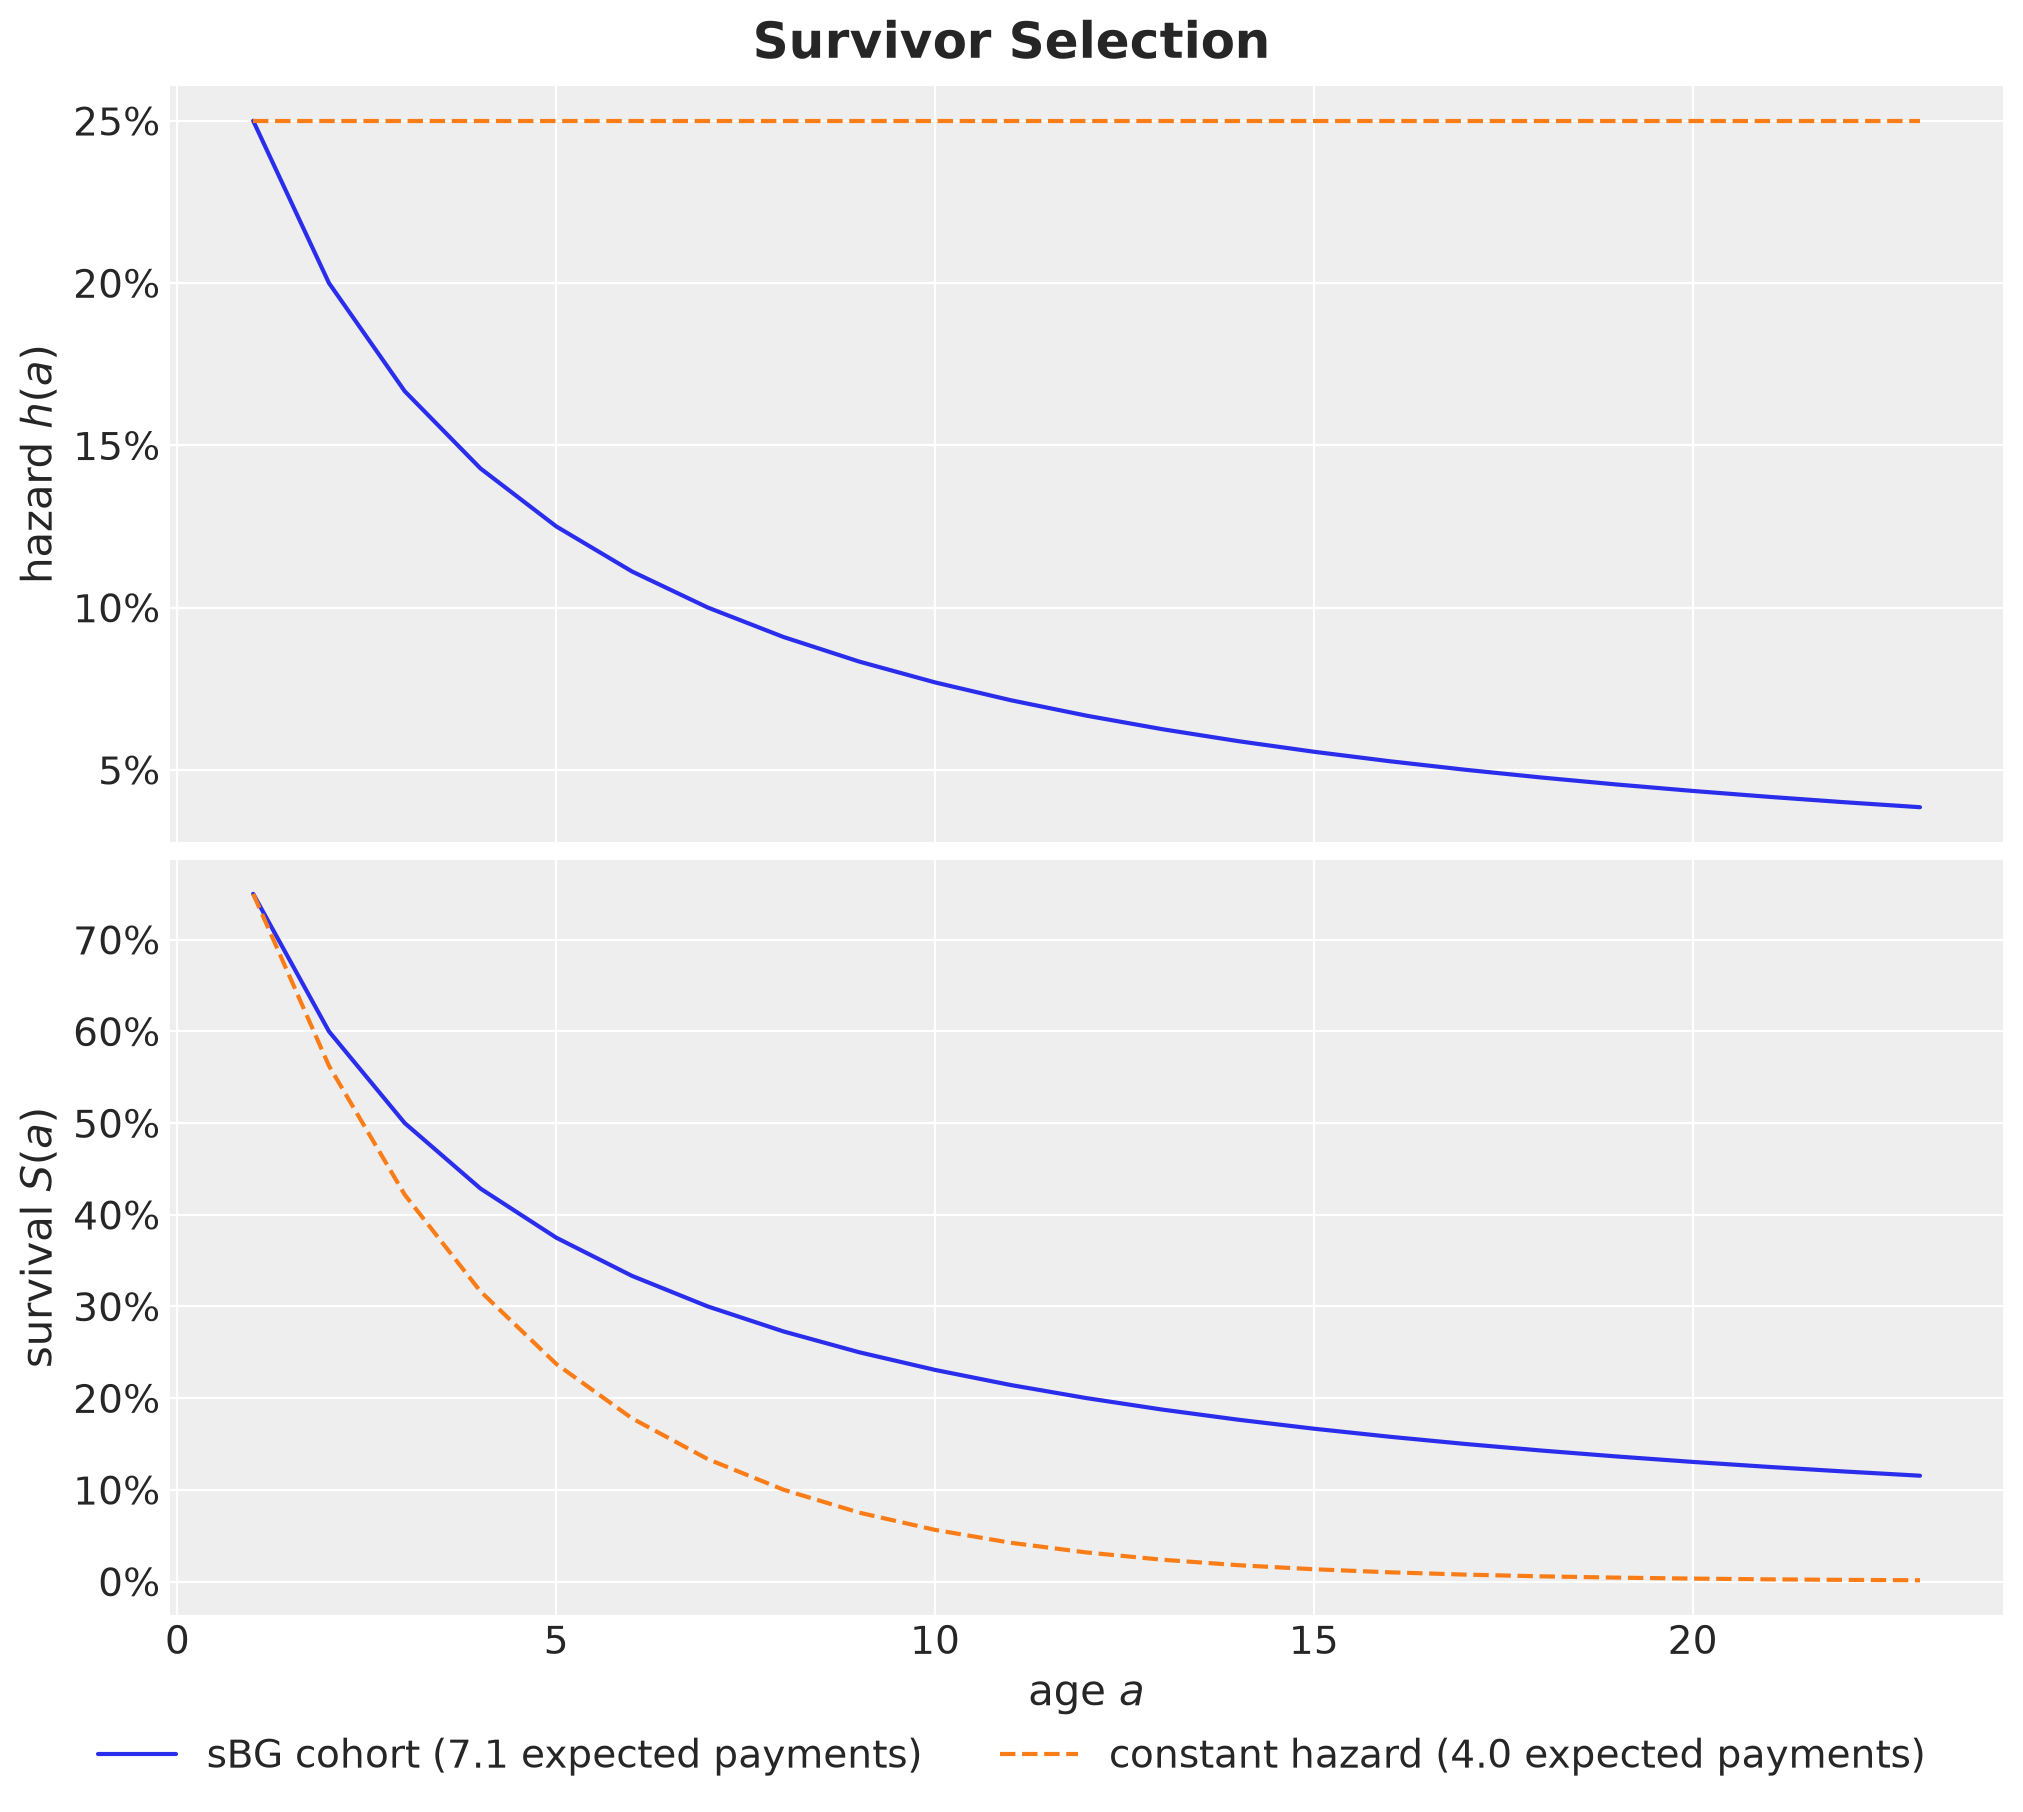

In [4]:
hazard_ages = np.arange(1, HORIZON)
hazard_sbg = SBG_ALPHA / (SBG_ALPHA + SBG_BETA + hazard_ages - 1)
hazard_constant = np.full_like(hazard_sbg, hazard_sbg[0])
survival_sbg = np.cumprod(1 - hazard_sbg)
survival_constant = np.cumprod(1 - hazard_constant)

fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(10, 9), sharex=True, layout="constrained"
)
ax = axes[0]
ax.plot(
    hazard_ages,
    hazard_sbg,
    color="C0",
    label=f"sBG cohort ({1 + survival_sbg.sum():.1f} expected payments)",
)
ax.plot(
    hazard_ages,
    hazard_constant,
    color="C1",
    linestyle="--",
    label=f"constant hazard ({1 + survival_constant.sum():.1f} expected payments)",
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(ylabel="hazard $h(a)$")
ax = axes[1]
ax.plot(hazard_ages, survival_sbg, color="C0")
ax.plot(hazard_ages, survival_constant, color="C1", linestyle="--")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="age $a$", ylabel="survival $S(a)$")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Survivor Selection", fontsize=18, fontweight="bold");

The hazard of the sBG cohort falls from $25\%$ at age $1$ to about $4\%$ at age $23$. The projection with the churn of the first month expects about $4$ payments per net start over two years, against about $7$ for the sBG cohort. A model that ignores survivor selection underestimates the value of a net start of the monthly plan by more than $40\%$.

The shape of the hazard comes from the spread of $\theta$, which we do not know in practice. For this reason the funnel model of the *Model Specification* section does not force a shape on the hazard. The older cohorts have reached every age of the horizon, and their data fix the shape.

Survivor selection has a second consequence. Suppose that a promotion brings users whose churn probabilities are all a bit higher: the logit of the churn probability of each user moves up by $\kappa$, at every age. We call this a **persistent shift**.

The cohort with the promotion loses its high-churn users faster. Its remaining users are therefore more selected than those of a cohort without the promotion, and the gap between the hazards of the two cohorts shrinks with age.

How fast does it shrink? For small churn probabilities the logit is close to the log, so the shift multiplies the churn probability of every user by $e^{\kappa}$. The frailty models of demography give a closed form for this case (Vaupel, Manton and Stallard 1979).

Suppose that every user has a constant hazard $\phi$ times a **frailty** that follows a Gamma distribution with mean one and variance $v$. Then the hazard of the group at age $a$ is $\phi / (1 + v \phi a)$.

A group whose users all have their hazard multiplied by $e^{\kappa}$ has the hazard $e^{\kappa} \phi / (1 + v e^{\kappa} \phi a)$. The log of the ratio of the two hazards is

$$
\begin{align*}
\log \frac{e^{\kappa} \phi / (1 + v e^{\kappa} \phi a)}{\phi / (1 + v \phi a)} & = \kappa - \log\left(1 + v e^{\kappa} \phi a\right) + \log\left(1 + v \phi a\right) \\
& \approx \kappa - \kappa \, \frac{v \phi a}{1 + v \phi a} = \frac{\kappa}{1 + v \phi a},
\end{align*}
$$

where the second line expands the first to first order in $\kappa$. The gap therefore shrinks by the same factor $1 / (1 + v \phi a)$ as the hazard of the group.

Our Beta distribution is close to a Gamma distribution for small churn probabilities, and we expect the gap at age $a$ to be the gap at age $1$ times the factor by which the hazard of the sBG cohort has fallen since age $1$:

$$
\frac{h(a)}{h(1)} = \frac{\alpha + \beta}{\alpha + \beta + a - 1} = \frac{1}{1 + \lambda (a - 1)}, \qquad \lambda = \frac{1}{\alpha + \beta}.
$$

Let's check this with a cohort whose users all have their logit shifted by $\kappa = 0.25$. We compute the hazard of the cohort on a grid of churn probabilities, with weights from the Beta density, and take the gap to the logit of the hazard of a cohort without the shift.

We add a third cohort for comparison, in which the shift acts in one month only, as a season does. For this cohort the value at age $a$ is the gap in the month of age $a$ when the shift acts in that month and in no earlier one.

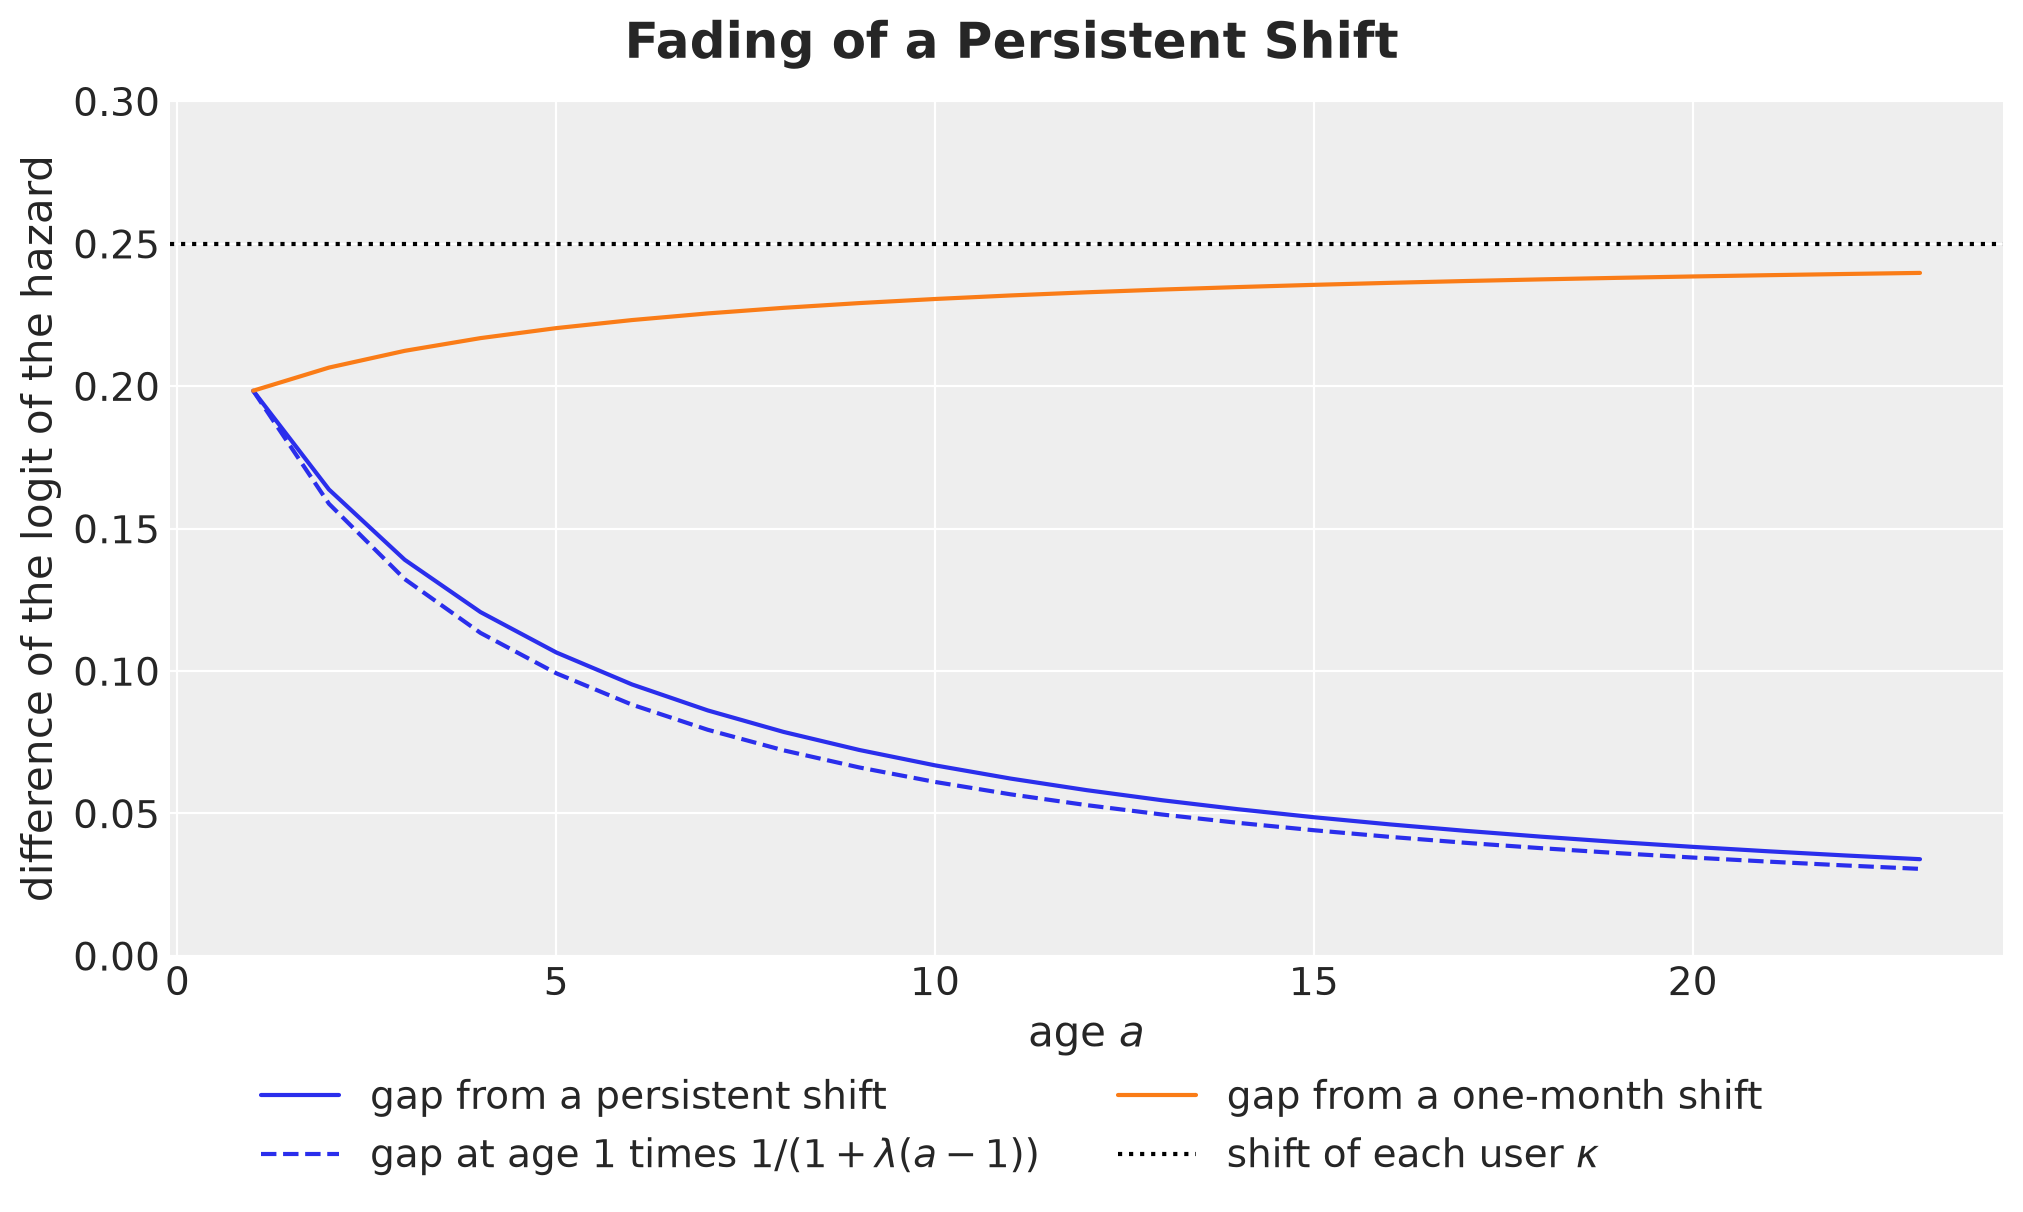

In [5]:
SHIFT: Final[float] = 0.25

theta_weights = pz.Beta(SBG_ALPHA, SBG_BETA).pdf(theta_values)


def cohort_hazard(shift: float, *, persistent: bool) -> np.ndarray:
    """Hazard by age of an sBG cohort whose users have the logit of their churn shifted.

    A persistent shift acts at every age. Otherwise the shift acts only in the month
    of the hazard, and the users churn without a shift in the earlier months.
    """
    churn = expit(logit(theta_values) + shift)
    earlier_churn = churn if persistent else theta_values
    active = (1 - earlier_churn[None, :]) ** (hazard_ages[:, None] - 1)
    return (theta_weights * active * churn).sum(axis=1) / (theta_weights * active).sum(
        axis=1
    )


logit_hazard_sbg = logit(cohort_hazard(0.0, persistent=True))
persistent_gap = logit(cohort_hazard(SHIFT, persistent=True)) - logit_hazard_sbg
one_month_gap = logit(cohort_hazard(SHIFT, persistent=False)) - logit_hazard_sbg
fading_factor = 1 / (1 + (hazard_ages - 1) / (SBG_ALPHA + SBG_BETA))

assert np.allclose(expit(logit_hazard_sbg), hazard_sbg, atol=1e-4)

fig, ax = plt.subplots()
ax.plot(hazard_ages, persistent_gap, color="C0", label="gap from a persistent shift")
ax.plot(
    hazard_ages,
    persistent_gap[0] * fading_factor,
    color="C0",
    linestyle="--",
    label=r"gap at age 1 times $1 / (1 + \lambda (a - 1))$",
)
ax.plot(hazard_ages, one_month_gap, color="C1", label="gap from a one-month shift")
ax.axhline(SHIFT, color="black", linestyle=":", label=r"shift of each user $\kappa$")
ax.set(xlabel="age $a$", ylabel="difference of the logit of the hazard", ylim=(0, 0.3))
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Fading of a Persistent Shift", fontsize=18, fontweight="bold");

The assertion confirms that the grid reproduces the hazard of the sBG cohort. Here are three important remarks:

- At age $1$ both gaps are smaller than the shift of each user, because the logit of an average is not the average of the logits. The hazard of a cohort is a **population-averaged** quantity, and its coefficients are smaller than the ones of each user ([Zeger, Liang and Albert 1988](https://doi.org/10.2307/2531734)).
- After age $1$ the gap from the persistent shift fades, and the simple formula follows it closely. For this reason the effects that last for the whole life of a cohort fade with age in the funnel model, at a rate that we learn from the data.
- The gap from the one-month shift does not fade. It grows a little toward the shift of each user. In the funnel model the season has the same effect at every age, which is a simplification.

The second property is about the differences between cohorts.

### Cohort Quality

The cohorts differ from each other, for example because the mix of ad networks that brings their users changes. We describe this with a **quality** $q_c \sim \text{Normal}(0, 1)$ of each cohort.

We assume that the quality moves three steps of the funnel: a cohort of high quality converts more, churns less and renews more. This is an assumption of our synthetic data, and with real data it is a hypothesis to check.

Let $s$ be one of these three steps. The **cohort effect** $u_{c,s}$ of step $s$ is a shift of the logit of its probability. It mixes the quality with a noise $\xi_{c,s} \sim \text{Normal}(0, 1)$ of its own:

$$
u_{c,s} = \sigma_s \left(w_s \, q_c + \sqrt{1 - w_s^2} \, \xi_{c,s}\right).
$$

Here $\sigma_s$ is the standard deviation of the effect, since its variance is $\sigma_s^2 \left(w_s^2 + 1 - w_s^2\right) = \sigma_s^2$. The **loading** $w_s$ is a number between $-1$ and $1$ that says how much of the effect comes from the quality. Two steps $s$ and $s'$ of one cohort share only the quality, so the covariance of their effects is $\sigma_s \sigma_{s'} w_s w_{s'}$ and their correlation is $\Omega_{s,s'} = w_s w_{s'}$.

Why do we care about the correlation? We know the conversion of a cohort in its first month, while its churn and its renewal show over the next two years. If the effects are correlated, the conversion of a young cohort tells us about its future.

Let's work a simple example with the values of our generator. Both effects have $\sigma_s = 0.15$, and the loadings are $0.8$ for the conversion and $-0.85$ for the churn, so their correlation is $-0.68$. Suppose that the conversion effect of a cohort is $x$. For two jointly Normal variables with mean zero, the [conditional distribution](https://en.wikipedia.org/wiki/Multivariate_normal_distribution#Bivariate_case_2) of the churn effect is Normal with

$$
\text{E}\left[u_{c,\text{churn}} \mid u_{c,\text{conversion}} = x\right] = \Omega \, \frac{\sigma_{\text{churn}}}{\sigma_{\text{conversion}}} \, x, \qquad \text{sd} = \sigma_{\text{churn}} \sqrt{1 - \Omega^2},
$$

where $\Omega$ is the correlation of the two effects. We plot the density of the churn effect for all cohorts and for the cohorts whose conversion effect is one standard deviation above zero.

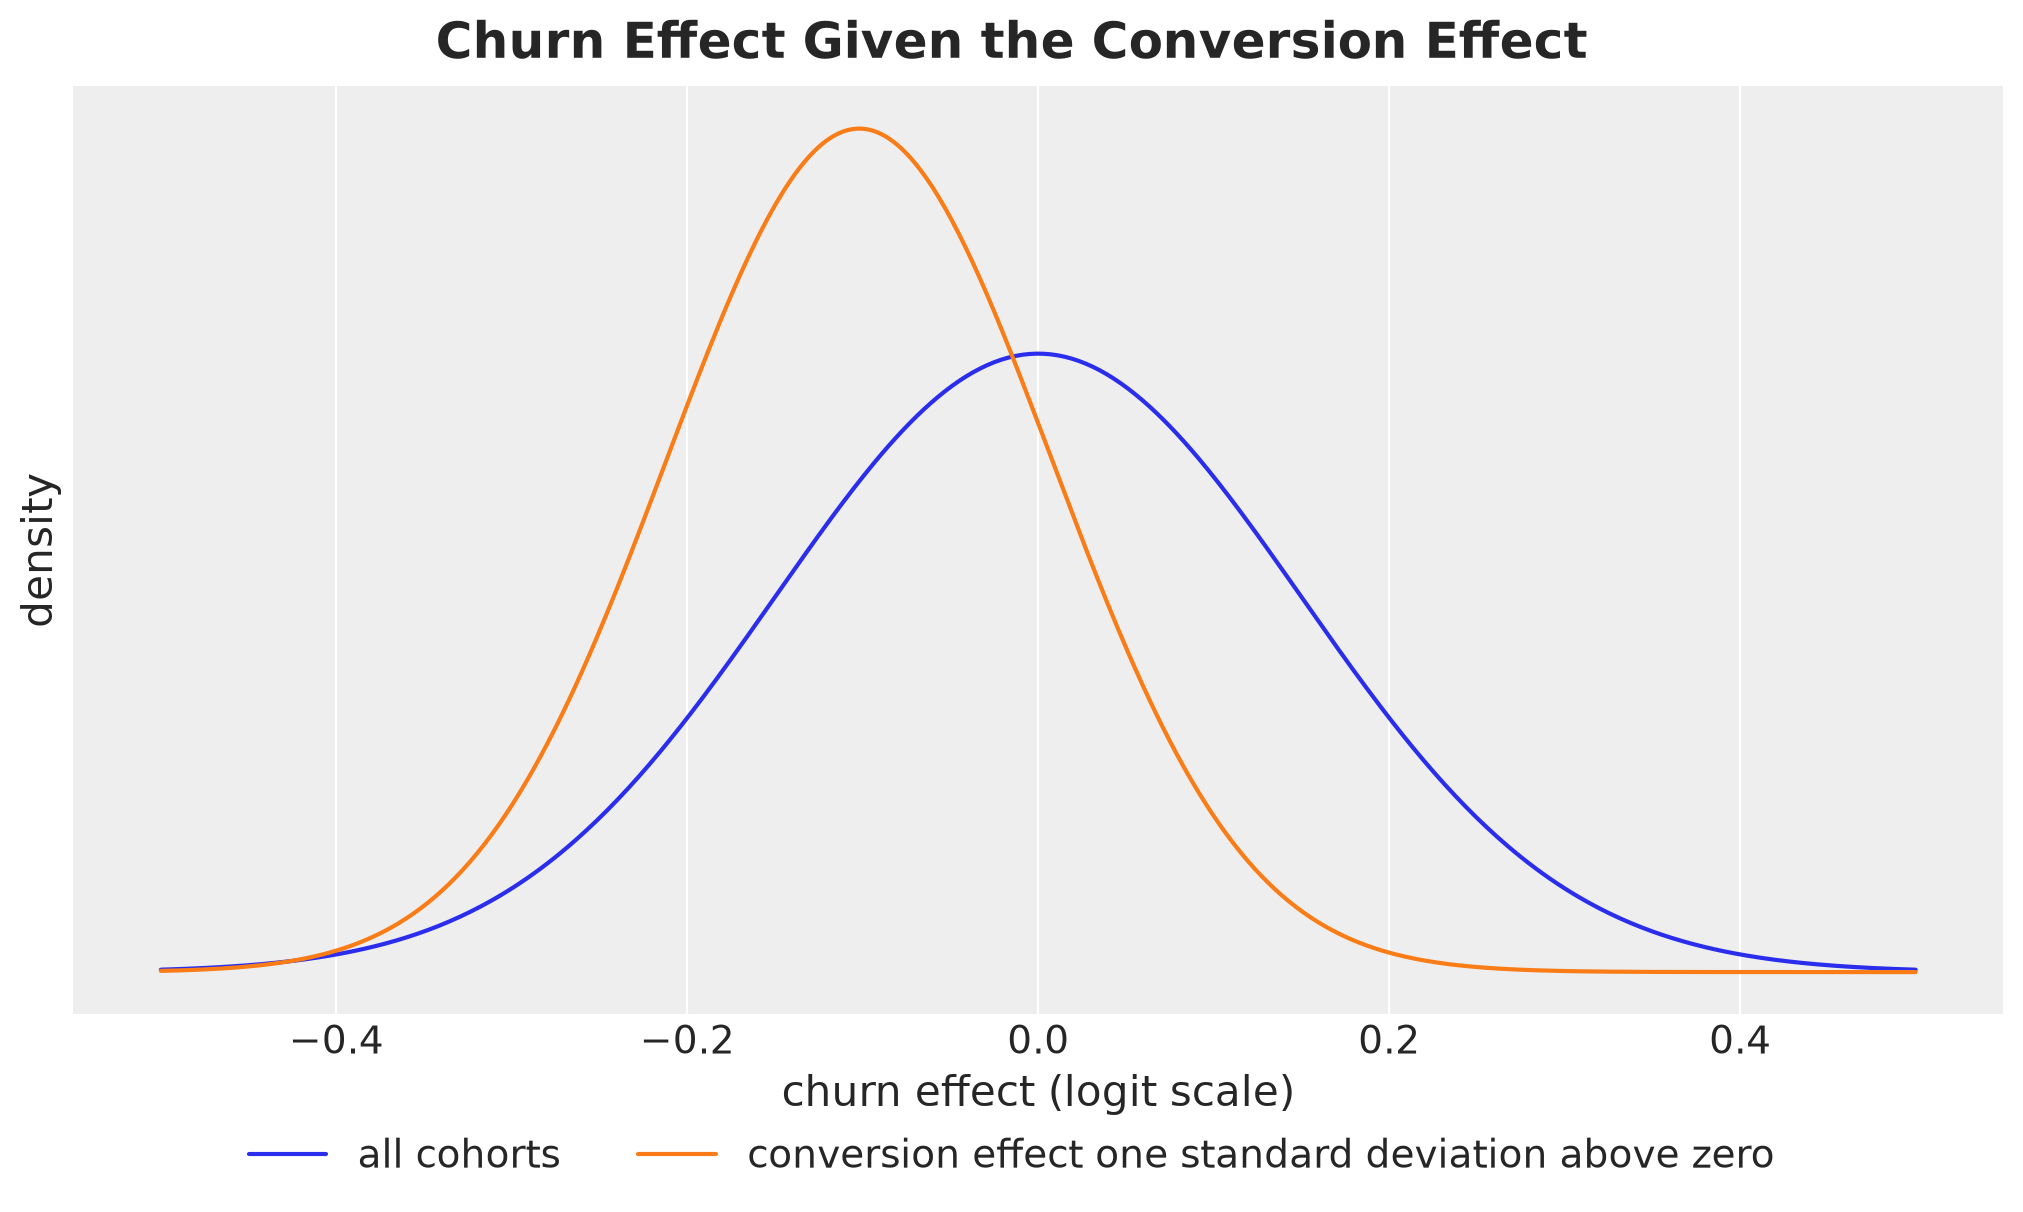

In [6]:
class CohortStep(StrEnum):
    CONVERSION = "conversion"
    CHURN = "churn"
    RENEWAL = "renewal"


COHORT_SIGMA: Final[dict[CohortStep, float]] = {
    CohortStep.CONVERSION: 0.15,
    CohortStep.CHURN: 0.15,
    CohortStep.RENEWAL: 0.15,
}
QUALITY_LOADING: Final[dict[CohortStep, float]] = {
    CohortStep.CONVERSION: 0.8,
    CohortStep.CHURN: -0.85,
    CohortStep.RENEWAL: 0.65,
}


def true_correlation(first: CohortStep, second: CohortStep) -> float:
    """Correlation between the cohort effects of two steps of the generator."""
    return QUALITY_LOADING[first] * QUALITY_LOADING[second]


correlation = true_correlation(CohortStep.CONVERSION, CohortStep.CHURN)
all_cohorts = pz.Normal(0.0, COHORT_SIGMA[CohortStep.CHURN])
good_converters = pz.Normal(
    correlation * COHORT_SIGMA[CohortStep.CHURN],
    COHORT_SIGMA[CohortStep.CHURN] * np.sqrt(1 - correlation**2),
)
effect_values = np.linspace(-0.5, 0.5, 500)

fig, ax = plt.subplots()
ax.plot(effect_values, all_cohorts.pdf(effect_values), color="C0", label="all cohorts")
ax.plot(
    effect_values,
    good_converters.pdf(effect_values),
    color="C1",
    label="conversion effect one standard deviation above zero",
)
ax.set(xlabel="churn effect (logit scale)", ylabel="density", yticks=[])
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    "Churn Effect Given the Conversion Effect", fontsize=18, fontweight="bold"
);

A cohort that converts one standard deviation better than usual has an expected churn effect of about $-0.10$, which means less churn. Its churn effect stays uncertain, since the standard deviation only falls from $0.15$ to $0.11$. With a correlation of $-0.3$ it would fall to $0.14$.

We should therefore expect the conversion to improve the forecast of a new cohort by a moderate amount, and by less when the correlation is weaker.

Now we are ready to generate the data.

## Generate Data

We simulate four years of monthly cohorts with a generative model in PyMC:

1. We write the model in PyMC.
2. We fix the true parameters with `pm.do`.
3. We take one draw with `pm.sample_prior_predictive`.

We first store the plans, the list prices and the calendar of the app.

In [7]:
class Plan(StrEnum):
    MONTHLY = "monthly"
    YEARLY = "yearly"


LIST_PRICE: Final[dict[Plan, float]] = {Plan.MONTHLY: 9.99, Plan.YEARLY: 69.99}
MONTHS: Final[list[str]] = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]


class Calendar(NamedTuple):
    """Cohorts, horizon, renewal age and promotion month of the synthetic app."""

    first_cohort: str = "2021-01"
    n_cohorts: int = 48
    horizon: int = HORIZON
    renewal_age: int = 12  # age at which the yearly plan renews
    promo_month: int = 10  # November, as an index of MONTHS

    @property
    def cohort_index(self) -> np.ndarray:
        return np.arange(self.n_cohorts)

    def month_labels(self, n_months: int) -> list[str]:
        """Labels of the first calendar months, starting with the first cohort."""
        first = np.datetime64(self.first_cohort, "M")
        return [str(first + i) for i in range(n_months)]

    @property
    def cohort_labels(self) -> list[str]:
        return self.month_labels(self.n_cohorts)

    @property
    def start_month(self) -> np.ndarray:
        first = np.datetime64(self.first_cohort, "M").astype(int)
        return (first + self.cohort_index) % 12

    @property
    def promo(self) -> np.ndarray:
        return (self.start_month == self.promo_month).astype(float)

    @property
    def ages(self) -> np.ndarray:
        return np.arange(self.horizon)

    @property
    def hazard_ages(self) -> np.ndarray:
        """Ages at which a user of the monthly plan can churn."""
        return np.arange(1, self.horizon)

    def payment_month(self, start_month: np.ndarray) -> np.ndarray:
        """Calendar month of the payment at each hazard age, one row per start month."""
        return (start_month[:, None] + self.hazard_ages[None, :]) % 12


calendar = Calendar()

### Data Generating Process

Now, let's specify the data generating process. We need the following symbols:

- **Trials:** $\text{years}_c$ is the time of cohort $c$ in years since the first cohort. The trials follow a log-linear trend with level $\tau_0$ and yearly growth $\tau_1$, and they have a **season** $\tau^{\text{s}}_m$, an effect for each calendar month $m$.
- **Conversion:** $\gamma_0$ is the logit of the conversion and $\gamma^{\text{s}}_m$ its season.
- **Plan choice:** $\psi_0$ is the logit of the probability of the yearly plan and $\psi_1$ the effect of the promotion on it.
- **Refunds:** $\rho_k$ is the logit of the refund probability of plan $k$.
- **Renewal:** $\eta_0$ is the logit of the renewal and $\eta_1$ the effect of the promotion on it.
- **Churn:** Each user $i$ has a churn probability $\theta_i \sim \text{Beta}(\alpha, \beta)$, as in the *Survivor Selection* section. The season $\delta_m$ of the calendar month of the payment and the promotion effect $\kappa$ shift its logit. We write $h_i(a)$ for the probability that user $i$ churns at age $a$.
- **Cohort effects:** $u_{c,s}$ is the effect of cohort $c$ on step $s$ of the *Cohort Quality* section. It shifts the logit of the conversion, the logit of the churn probability of every user, and the logit of the renewal.
- **Payments:** $B_{c,k,a}$ is the number of payments of plan $k$ in cohort $c$ at age $a$, and $X_{c,k,a}$ is their revenue. It is the number of active users $A_{c,a}$ for the monthly plan, and $N_{c,\text{yearly}}$ at age $0$ and $Q_c$ at age $12$ for the yearly plan. Each payment is a Gamma draw with mean $\mu_k$ and shape $\nu_k$.

Every season sums to zero over the $12$ calendar months, so $\tau_0$, $\gamma_0$ and the churn probabilities $\theta_i$ describe an average month.

The sum of $B_{c,k,a}$ Gamma payments is a Gamma with shape $B_{c,k,a} \nu_k$. In the earlier post the shape was the number of active users itself, and $\nu_k$ lets the amount of a single payment vary more or less. The data generating process is

$$
\begin{align*}
q_c & \sim \text{Normal}(0, 1), \quad \xi_{c,s} \sim \text{Normal}(0, 1) \\
u_{c,s} & = \sigma_s \left(w_s \, q_c + \sqrt{1 - w_s^2} \, \xi_{c,s}\right) \\
T_c & \sim \text{Poisson}\left(\exp\left(\tau_0 + \tau_1 \, \text{years}_c + \tau^{\text{s}}_{m_c}\right)\right) \\
P_c & \sim \text{Binomial}\left(T_c, \text{logit}^{-1}\left(\gamma_0 + \gamma^{\text{s}}_{m_c} + u_{c,\text{conversion}}\right)\right) \\
Y_c & \sim \text{Binomial}\left(P_c, \text{logit}^{-1}\left(\psi_0 + \psi_1 z_c\right)\right) \\
F_{c,k} & \sim \text{Binomial}\left(P_{c,k}, \text{logit}^{-1}\left(\rho_k\right)\right) \\
\theta_i & \sim \text{Beta}(\alpha, \beta) \\
\text{logit}\, h_i(a) & = \text{logit}\, \theta_i + \delta_{m_c + a} + \kappa z_c + u_{c,\text{churn}} \\
Q_c & \sim \text{Binomial}\left(N_{c,\text{yearly}}, \text{logit}^{-1}\left(\eta_0 + \eta_1 z_c + u_{c,\text{renewal}}\right)\right) \\
X_{c,k,a} & \sim \text{Gamma}\left(B_{c,k,a} \nu_k, \nu_k / \mu_k\right),
\end{align*}
$$

where the Gamma has shape and rate parameters and the month index $m_c + a$ wraps around the year.

Simulating every user is slow, so we draw the users of a cohort at once. Let the **lifetime** of a user of the monthly plan be the number of payments within the horizon, so that a user with lifetime $\ell$ pays at ages $0, \dots, \ell - 1$.

Given the cohort effect, the users of a cohort are independent and have the same distribution of $\theta$. The counts of users by lifetime are therefore $\text{Multinomial}(N_{c,\text{monthly}}, \pi_c)$, with

$$
\pi_{c,\ell} = S_c(\ell - 1) - S_c(\ell) \quad \text{for } \ell < H, \qquad \pi_{c,H} = S_c(H - 1),
$$

where the survival $S_c(a)$ of the cohort is the average over $\theta$ of the survival of a single user. We compute this average on a grid of values of $\theta$, with weights proportional to the Beta density.

The generator records the true hazard $1 - S_c(a) / S_c(a - 1)$ and the true renewal probability of each cohort. We use both to check the model later.

Finally, the generator computes the true value per trial $V_m$ of *The Subscription Funnel* section, which is an expectation over the three effects of a new cohort.

**Remark (Quadrature).** The three effects are jointly Normal with the covariance matrix $\Sigma$ of the *Cohort Quality* section. Let $L$ be the Cholesky factor of $\Sigma$, the lower triangular matrix with $\Sigma = L L^\top$. If $\zeta$ is a vector of three independent standard Normal variables, then $L \zeta$ has the distribution of the three effects.

[Gauss-Hermite quadrature](https://en.wikipedia.org/wiki/Gauss%E2%80%93Hermite_quadrature) approximates the expectation of a function of a standard Normal variable by a weighted sum over a few fixed nodes $r_i$ with weights $b_i$. For the three components of $\zeta$ we sum over all triples of nodes:

$$
V_m \approx \sum_{i} \sum_{j} \sum_{l} b_i \, b_j \, b_l \, V\left(L \, (r_i, r_j, r_l)^\top\right),
$$

where $V(u)$ is the formula of $V_c$ for a cohort of month $m$ with effects $u$.

The generator and the funnel model share a few helpers:

- `by_label` splits a variable along a dimension into a dictionary, so that we can write `refund[Plan.MONTHLY]` instead of a position.
- `CohortCovariates` holds the covariates of a set of cohorts: the start month, the promotion indicator and the calendar month of every payment. We build it for the cohorts of the data and for the cohorts that could start in each calendar month.
- `Conversion`, `PlanChoice` and `Renewal` hold the parameters of one step each, and their `logit` method is the linear predictor of the step. `Payment` holds the mean and the shape of the Gamma amount of a payment.
- `CohortEffects` holds the effects $u_{c,s}$ of the cohorts and the Cholesky factor $L$.
- `survival` turns hazards into survival probabilities. `lifetime_probability` turns survival probabilities into the probabilities $\pi_{c,\ell}$ of the lifetimes, and `remaining_users` turns the counts of users by lifetime into the active users.
- `new_cohort_effects` builds the effects $L \zeta$ of a new cohort on the grid of nodes, and `average_over_new_cohorts` takes the weighted sum over the grid.
- `value_per_trial` holds the formula of $V_c$, and `new_cohort_value` averages it over the effects of a new cohort for each start month. The expected number of payments of the monthly plan is the one input that differs between the generator and the funnel model, so `new_cohort_value` takes it as a function.

In [8]:
class Quadrature(NamedTuple):
    """Nodes and weights of a weighted sum that approximates an expectation."""

    nodes: np.ndarray
    weights: np.ndarray


hermite_nodes, hermite_weights = np.polynomial.hermite_e.hermegauss(10)

QUADRATURE: Final[Quadrature] = Quadrature(
    nodes=hermite_nodes, weights=hermite_weights / hermite_weights.sum()
)
NODE_DIMS: Final[tuple[str, ...]] = tuple(f"node_{i}" for i in range(len(CohortStep)))


def by_label(x: pmd.XTensorVariable, dim: str, labels: type[StrEnum]) -> dict:
    """Split a variable along a dimension into a dictionary keyed by the labels."""
    return {label: x.isel({dim: i}) for i, label in enumerate(labels)}


def survival(hazard: pmd.XTensorVariable) -> pmd.XTensorVariable:
    """Probability to be active at each age, the cumulative product of 1 - hazard."""
    return pmd.math.exp(pmd.math.log1p(-hazard).cumsum("hazard_age"))


def new_cohort_effects(
    chol: pt.TensorVariable,
) -> dict[CohortStep, pmd.XTensorVariable]:
    """Effects of a new cohort on the grid of nodes, one axis per standard Normal."""
    zeta = [pmd.as_xtensor(QUADRATURE.nodes, dims=(dim,)) for dim in NODE_DIMS]
    return {
        step: sum(chol[i, j] * zeta[j] for j in range(i + 1))
        for i, step in enumerate(CohortStep)
    }


def average_over_new_cohorts(x: pmd.XTensorVariable) -> pmd.XTensorVariable:
    """Weighted sum over the grid of nodes, the expectation over a new cohort."""
    for dim in NODE_DIMS:
        x = (x * pmd.as_xtensor(QUADRATURE.weights, dims=(dim,))).sum(dim)

    return x


def lifetime_probability(survival_by_step: pt.TensorVariable) -> pt.TensorVariable:
    """Probability of each lifetime, from the survival after 0, 1, ... steps.

    One row per cohort. The last column is the probability to outlive the last step.
    """
    return pt.concatenate(
        [
            survival_by_step[:, :-1] - survival_by_step[:, 1:],
            survival_by_step[:, -1:],
        ],
        axis=1,
    )


def remaining_users(
    n_start: pt.TensorVariable, n_lifetime: pt.TensorVariable
) -> pt.TensorVariable:
    """Users who are still active after each step, from the users by lifetime."""
    return n_start[:, None] - pt.cumsum(n_lifetime[:, :-1], axis=1)


class CohortCovariates(NamedTuple):
    """Covariates of a set of cohorts, along one dimension."""

    start_month: pmd.XTensorVariable
    promo: pmd.XTensorVariable
    payment_month: pmd.XTensorVariable


def cohort_covariates(start_month: np.ndarray, dim: str) -> CohortCovariates:
    """Start month, promotion indicator and payment months of a set of cohorts."""
    return CohortCovariates(
        start_month=pmd.as_xtensor(start_month, dims=(dim,)),
        promo=pmd.as_xtensor(
            (start_month == calendar.promo_month).astype(float), dims=(dim,)
        ),
        payment_month=pmd.as_xtensor(
            calendar.payment_month(start_month), dims=(dim, "hazard_age")
        ),
    )


class CohortEffects(NamedTuple):
    """Effects of the cohorts by step, and the Cholesky factor of their covariance."""

    by_step: dict[CohortStep, pmd.XTensorVariable]
    chol: pt.TensorVariable


class Conversion(NamedTuple):
    """Parameters of the conversion of a trial into a paying user."""

    intercept: pmd.XTensorVariable
    season: pmd.XTensorVariable

    def logit(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable:
        return self.intercept + self.season.isel(month=cohorts.start_month) + effect


class PlanChoice(NamedTuple):
    """Parameters of the choice of the yearly plan."""

    intercept: pmd.XTensorVariable
    promo: pmd.XTensorVariable

    def logit(self, cohorts: CohortCovariates) -> pmd.XTensorVariable:
        return self.intercept + self.promo * cohorts.promo


class Renewal(NamedTuple):
    """Parameters of the renewal of the yearly plan."""

    intercept: pmd.XTensorVariable
    promo: pmd.XTensorVariable

    def logit(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable:
        return self.intercept + self.promo * cohorts.promo + effect


class Payment(NamedTuple):
    """Mean and shape of the Gamma amount of one payment, by plan."""

    revenue_per_payment: pmd.XTensorVariable
    shape: pmd.XTensorVariable


def value_per_trial(
    conversion: Conversion,
    plan_choice: PlanChoice,
    refund_logit: pmd.XTensorVariable,
    renewal: Renewal,
    payment: Payment,
    monthly_payments: pmd.XTensorVariable,
    cohorts: CohortCovariates,
    effect: dict[CohortStep, pmd.XTensorVariable],
) -> pmd.XTensorVariable:
    """Expected revenue of one trial over the horizon (the formula of V_c)."""
    refund = by_label(pmd.math.sigmoid(refund_logit), "plan", Plan)
    revenue_per_payment = by_label(payment.revenue_per_payment, "plan", Plan)
    yearly_share = pmd.math.sigmoid(plan_choice.logit(cohorts))
    renewal_probability = pmd.math.sigmoid(
        renewal.logit(cohorts, effect[CohortStep.RENEWAL])
    )
    monthly_value = (
        (1 - yearly_share)
        * (1 - refund[Plan.MONTHLY])
        * revenue_per_payment[Plan.MONTHLY]
        * monthly_payments
    )
    yearly_value = (
        yearly_share
        * (1 - refund[Plan.YEARLY])
        * revenue_per_payment[Plan.YEARLY]
        * (1 + renewal_probability)
    )
    conversion_probability = pmd.math.sigmoid(
        conversion.logit(cohorts, effect[CohortStep.CONVERSION])
    )
    return conversion_probability * (monthly_value + yearly_value)


class ExpectedPayments(Protocol):
    """Expected payments of a net start of the monthly plan within the horizon."""

    def __call__(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable: ...


def new_cohort_value(
    conversion: Conversion,
    plan_choice: PlanChoice,
    refund_logit: pmd.XTensorVariable,
    renewal: Renewal,
    payment: Payment,
    expected_payments: ExpectedPayments,
    chol: pt.TensorVariable,
) -> pmd.XTensorVariable:
    """Value per trial by start month, averaged over the effects of a new cohort."""
    cohorts = cohort_covariates(np.arange(len(MONTHS)), dim="month")
    effect = new_cohort_effects(chol)
    return average_over_new_cohorts(
        value_per_trial(
            conversion,
            plan_choice,
            refund_logit,
            renewal,
            payment,
            monthly_payments=expected_payments(cohorts, effect[CohortStep.CHURN]),
            cohorts=cohorts,
            effect=effect,
        )
    )

### Generator

We proceed by implementing the generator, with one function for each step of the funnel. Each function takes the parameters of its step and the users who reach it. It returns the users who go on, except for the revenue, which is the last step.

We use the [`pymc.dims`](https://www.pymc.io/projects/docs/en/stable/learn/core_notebooks/dims_module.html) module, in which every variable carries named dimensions and arithmetic aligns by name. It does not include the Binomial and the Multinomial distributions yet. For these lines, and for the lines that use their counts, we convert to regular tensors with `.values` and use the classic API.

In [9]:
THETA_GRID: Final[np.ndarray] = (np.arange(200) + 0.5) / 200


class UserChurn(NamedTuple):
    """Parameters of the churn of the users in the generator."""

    alpha: pmd.XTensorVariable
    beta: pmd.XTensorVariable
    season: pmd.XTensorVariable
    promo: pmd.XTensorVariable

    def cohort_survival(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable:
        """Share of the net starts of a cohort who are still active at each age."""
        theta = pmd.as_xtensor(THETA_GRID, dims=("theta",))
        theta_density = pmd.math.exp(
            (self.alpha - 1) * pmd.math.log(theta)
            + (self.beta - 1) * pmd.math.log1p(-theta)
        )
        theta_weight = theta_density / theta_density.sum("theta")
        logit_theta = pmd.math.log(theta) - pmd.math.log1p(-theta)
        user_hazard = pmd.math.sigmoid(
            logit_theta
            + self.season.isel(month=cohorts.payment_month)
            + self.promo * cohorts.promo
            + effect
        )
        return (survival(user_hazard) * theta_weight).sum("theta")

    def expected_payments(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable:
        """Expected payments of a net start of the monthly plan within the horizon."""
        return 1 + self.cohort_survival(cohorts, effect).sum("hazard_age")


def simulate_cohort_effects() -> CohortEffects:
    """Quality of each cohort and its effect on the three steps."""
    cohort_sigma = pmd.HalfNormal("cohort_sigma", 0.2, dims="cohort_step")
    quality_loading = pmd.Uniform("quality_loading", -1.0, 1.0, dims="cohort_step")
    cohort_quality = pmd.Normal("cohort_quality", 0.0, 1.0, dims="cohort")
    cohort_noise = pmd.Normal("cohort_noise", 0.0, 1.0, dims=("cohort", "cohort_step"))
    noise_loading = pmd.math.sqrt(1 - quality_loading**2)
    cohort_effect = pmd.Deterministic(
        "cohort_effect",
        (
            cohort_sigma
            * (quality_loading * cohort_quality + noise_loading * cohort_noise)
        ).transpose("cohort", "cohort_step"),
    )
    quality_scale = (cohort_sigma * quality_loading).values
    noise_variance = (cohort_sigma**2 * (1 - quality_loading**2)).values
    covariance = pt.outer(quality_scale, quality_scale) + pt.diag(noise_variance)
    return CohortEffects(
        by_step=by_label(cohort_effect, "cohort_step", CohortStep),
        chol=pt.linalg.cholesky(covariance),
    )


def simulate_trials(cohorts: CohortCovariates) -> pmd.XTensorVariable:
    """Trials of each cohort: a log-linear trend with a season."""
    years = pmd.as_xtensor(calendar.cohort_index / 12, dims=("cohort",))
    trial_intercept = pmd.Normal("trial_intercept", 8.0, 1.0)
    trial_growth = pmd.Normal("trial_growth", 0.0, 0.2)
    trial_season = pmd.ZeroSumNormal(
        "trial_season", sigma=0.2, core_dims="month", dims="month"
    )
    return pmd.Poisson(
        "n_trials",
        mu=pmd.math.exp(
            trial_intercept
            + trial_growth * years
            + trial_season.isel(month=cohorts.start_month)
        ),
    )


def simulate_conversion(
    conversion: Conversion,
    cohorts: CohortCovariates,
    n_trials: pmd.XTensorVariable,
    effect: pmd.XTensorVariable,
) -> pt.TensorVariable:
    """Trials that convert into paying users."""
    return pm.Binomial(
        "n_paid",
        n=n_trials.values,
        logit_p=conversion.logit(cohorts, effect).values,
        dims="cohort",
    )


def simulate_plan_choice(
    plan_choice: PlanChoice, cohorts: CohortCovariates, n_paid: pt.TensorVariable
) -> pt.TensorVariable:
    """Paying users who choose the yearly plan."""
    return pm.Binomial(
        "n_yearly", n=n_paid, logit_p=plan_choice.logit(cohorts).values, dims="cohort"
    )


def simulate_refunds(
    refund_logit: pmd.XTensorVariable,
    n_paid: pt.TensorVariable,
    n_yearly: pt.TensorVariable,
) -> dict[Plan, pmd.XTensorVariable]:
    """Net starts of each plan: the paying users minus the refunds."""
    n_plan = pt.stack([n_paid - n_yearly, n_yearly], axis=-1)
    n_refund = pm.Binomial(
        "n_refund", n=n_plan, logit_p=refund_logit.values, dims=("cohort", "plan")
    )
    n_starts = pmd.Deterministic(
        "n_starts", pmd.as_xtensor(n_plan - n_refund, dims=("cohort", "plan"))
    )
    return by_label(n_starts, "plan", Plan)


def simulate_churn(
    churn: UserChurn,
    cohorts: CohortCovariates,
    n_starts: pmd.XTensorVariable,
    effect: pmd.XTensorVariable,
) -> pt.TensorVariable:
    """Active users of the monthly plan at each age, from one draw of the lifetimes."""
    cohort_survival = pt.concatenate(
        [
            pt.ones((calendar.n_cohorts, 1)),
            churn.cohort_survival(cohorts, effect)
            .transpose("cohort", "hazard_age")
            .values,
        ],
        axis=1,
    )
    pm.Deterministic(
        "true_hazard",
        1 - cohort_survival[:, 1:] / cohort_survival[:, :-1],
        dims=("cohort", "hazard_age"),
    )
    n_lifetime = pm.Multinomial(
        "n_lifetime",
        n=n_starts.values,
        p=pm.Deterministic(
            "lifetime_probability",
            lifetime_probability(cohort_survival),
            dims=("cohort", "lifetime"),
        ),
        dims=("cohort", "lifetime"),
    )
    return pm.Deterministic(
        "n_active",
        pt.concatenate(
            [n_starts.values[:, None], remaining_users(n_starts.values, n_lifetime)],
            axis=1,
        ),
        dims=("cohort", "age"),
    )


def simulate_renewal(
    renewal: Renewal,
    cohorts: CohortCovariates,
    n_starts: pmd.XTensorVariable,
    effect: pmd.XTensorVariable,
) -> pt.TensorVariable:
    """Renewals of the yearly plan at age 12."""
    renewal_logit = renewal.logit(cohorts, effect)
    pmd.Deterministic("true_renewal_probability", pmd.math.sigmoid(renewal_logit))
    return pm.Binomial(
        "n_renewed", n=n_starts.values, logit_p=renewal_logit.values, dims="cohort"
    )


def simulate_revenue(
    payment: Payment,
    n_active: pt.TensorVariable,
    n_starts_yearly: pmd.XTensorVariable,
    n_renewed: pt.TensorVariable,
) -> None:
    """Revenue of the payments of both plans."""
    shape = by_label(payment.shape, "plan", Plan)
    revenue_per_payment = by_label(payment.revenue_per_payment, "plan", Plan)
    pm.Gamma(
        "revenue_monthly",
        alpha=n_active * shape[Plan.MONTHLY].values,
        beta=(shape[Plan.MONTHLY] / revenue_per_payment[Plan.MONTHLY]).values,
        dims=("cohort", "age"),
    )
    yearly_payments = pt.stack([n_starts_yearly.values, n_renewed], axis=-1)
    pm.Gamma(
        "revenue_yearly",
        alpha=yearly_payments * shape[Plan.YEARLY].values,
        beta=(shape[Plan.YEARLY] / revenue_per_payment[Plan.YEARLY]).values,
        dims=("cohort", "payment"),
    )

Now we assemble the steps in one PyMC model. The priors inside it play no role, since `pm.do` fixes every parameter, and we choose the priors of the funnel model later. The last lines compute the true value per trial, with the `Cohorts` of the $12$ calendar months and the effects of a new cohort on the grid of nodes.

In [10]:
generator_coords = {
    "cohort": calendar.cohort_labels,
    "month": MONTHS,
    "plan": list(Plan),
    "cohort_step": list(CohortStep),
    "age": calendar.ages,
    "hazard_age": calendar.hazard_ages,
    "lifetime": np.arange(1, calendar.horizon + 1),
    "payment": ["initial", "renewal"],
    "theta": THETA_GRID,
}

with pm.Model(coords=generator_coords) as generator:
    cohorts = cohort_covariates(calendar.start_month, dim="cohort")
    effects = simulate_cohort_effects()
    n_trials = simulate_trials(cohorts)
    conversion = Conversion(
        intercept=pmd.Normal("conversion_intercept", 0.0, 1.0),
        season=pmd.ZeroSumNormal(
            "conversion_season", sigma=0.3, core_dims="month", dims="month"
        ),
    )
    plan_choice = PlanChoice(
        intercept=pmd.Normal("yearly_intercept", 0.0, 1.0),
        promo=pmd.Normal("yearly_promo", 0.0, 1.0),
    )
    refund_logit = pmd.Normal("refund_logit", -3.0, 1.0, dims="plan")
    n_paid = simulate_conversion(
        conversion, cohorts, n_trials, effects.by_step[CohortStep.CONVERSION]
    )
    n_yearly = simulate_plan_choice(plan_choice, cohorts, n_paid)
    n_starts = simulate_refunds(refund_logit, n_paid, n_yearly)
    churn = UserChurn(
        alpha=pmd.HalfNormal("churn_alpha", 2.0),
        beta=pmd.HalfNormal("churn_beta", 5.0),
        season=pmd.ZeroSumNormal(
            "churn_season", sigma=0.2, core_dims="month", dims="month"
        ),
        promo=pmd.Normal("churn_promo", 0.0, 0.5),
    )
    n_active = simulate_churn(
        churn, cohorts, n_starts[Plan.MONTHLY], effects.by_step[CohortStep.CHURN]
    )
    renewal = Renewal(
        intercept=pmd.Normal("renewal_intercept", 0.0, 1.0),
        promo=pmd.Normal("renewal_promo", 0.0, 1.0),
    )
    n_renewed = simulate_renewal(
        renewal, cohorts, n_starts[Plan.YEARLY], effects.by_step[CohortStep.RENEWAL]
    )
    log_revenue_per_payment = pmd.Normal(
        "log_revenue_per_payment",
        pmd.as_xtensor(np.log(list(LIST_PRICE.values())), dims=("plan",)),
        0.2,
    )
    payment = Payment(
        shape=pmd.LogNormal("payment_shape", np.log(50.0), 1.0, dims="plan"),
        revenue_per_payment=pmd.math.exp(log_revenue_per_payment),
    )
    simulate_revenue(payment, n_active, n_starts[Plan.YEARLY], n_renewed)

    pmd.Deterministic(
        "value_per_trial",
        new_cohort_value(
            conversion,
            plan_choice,
            refund_logit,
            renewal,
            payment,
            expected_payments=churn.expected_payments,
            chol=effects.chol,
        ),
    )

### Simulation

We now fix the true parameter values that we intervene on. We choose the following rates:

- **Conversion:** $60\%$ of the trials convert in an average month.
- **Plan choice:** $30\%$ of the paying users choose the yearly plan, and the promotion multiplies the odds of the yearly plan by $e^{0.9} \approx 2.5$.
- **Refunds:** $2\%$ of the first payments of the monthly plan and $12\%$ of the ones of the yearly plan are refunded.
- **Churn:** The churn probabilities follow the $\text{Beta}(1, 3)$ distribution of the *Survivor Selection* section. We assume that the promotion brings users who are more sensitive to the price, so they churn more, with $\kappa = 0.25$.
- **Renewal:** $32\%$ of the net starts of the yearly plan renew. For the same reason the promotion multiplies the odds of the renewal by $e^{-0.6} \approx 0.55$.
- **Cohort effects:** The standard deviations and the loadings are the ones of the *Cohort Quality* section. The loading of the renewal is $0.65$.
- **Payments:** The average payment is $5\%$ below the list price of the monthly plan and $7\%$ below the one of the yearly plan, for example because of regional prices and coupons.

Then we take one draw, which we call a **simulation**. The assertion checks that the grid of nodes of the *Data Generating Process* section reproduces the covariance of the three effects.

In [11]:
def centered(values: np.ndarray | list[float]) -> np.ndarray:
    """Subtract the mean, so that the effects of the calendar months sum to zero."""
    values = np.asarray(values, dtype=float)
    return values - values.mean()


TRUE_PARAMS: Final[dict[str, float | np.ndarray]] = {
    "trial_intercept": np.log(3_000.0),
    "trial_growth": 0.12,
    "trial_season": centered(np.log([1.35, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1.25, 1.15])),
    "conversion_intercept": logit(0.6),
    "conversion_season": centered(
        [0.45, 0.10, 0.05, 0.0, -0.05, -0.40, -0.80, -0.70, -0.05, 0.10, 0.25, 0.35]
    ),
    "yearly_intercept": logit(0.3),
    "yearly_promo": 0.9,
    "refund_logit": logit(np.array([0.02, 0.12])),
    "cohort_sigma": np.array([COHORT_SIGMA[step] for step in CohortStep]),
    "quality_loading": np.array([QUALITY_LOADING[step] for step in CohortStep]),
    "churn_alpha": SBG_ALPHA,
    "churn_beta": SBG_BETA,
    "churn_season": centered(
        [0.20, 0.05, 0.0, -0.05, -0.05, 0.0, 0.05, 0.05, 0.10, -0.05, -0.10, -0.20]
    ),
    "churn_promo": SHIFT,
    "renewal_intercept": logit(0.32),
    "renewal_promo": -0.6,
    "log_revenue_per_payment": np.log(
        np.array(list(LIST_PRICE.values())) * [0.95, 0.93]
    ),
    "payment_shape": np.array([40.0, 60.0]),
}
TRUE_CORRELATION: Final[np.ndarray] = np.array(
    [
        [
            1.0 if row == column else true_correlation(row, column)
            for column in CohortStep
        ]
        for row in CohortStep
    ]
)
TRUE_COVARIANCE: Final[np.ndarray] = TRUE_CORRELATION * np.outer(
    TRUE_PARAMS["cohort_sigma"], TRUE_PARAMS["cohort_sigma"]
)

grid_effects = new_cohort_effects(pt.as_tensor(np.linalg.cholesky(TRUE_COVARIANCE)))
grid_covariance = np.array(
    [
        [
            average_over_new_cohorts(grid_effects[row] * grid_effects[column]).eval()
            for column in CohortStep
        ]
        for row in CohortStep
    ]
)

assert np.allclose(grid_covariance, TRUE_COVARIANCE)

draw = pm.sample_prior_predictive(
    draws=1, model=pm.do(generator, TRUE_PARAMS), random_seed=rng
)["prior"].dataset.isel(chain=0, draw=0)

Next, we collect the simulation in two polars tables: `cohorts`, with one row per cohort and the counts of the first steps of the funnel, and `payments`, with one row per cohort, plan and age at which a payment can happen. The `period` column counts the calendar months since January 2021.

We look at the app at the end of a month, the **freeze**, as if that month were today. The `Simulation` named tuple holds the complete draw and cuts it at a freeze.

The `FunnelData` named tuple holds what we know at the freeze: the cohorts that have started and the payments that have happened. A cohort is **open** at the freeze if it has not reached the end of its horizon.

In [12]:
class FunnelData(NamedTuple):
    """The cohorts and the payments that we know at the end of the freeze month."""

    freeze: int
    cohorts: pl.DataFrame
    payments: pl.DataFrame

    @property
    def cohort_labels(self) -> list[str]:
        return [calendar.cohort_labels[c] for c in self.cohorts["cohort"]]

    @property
    def transitions(self) -> pl.DataFrame:
        """Users of the monthly plan who could churn, by cohort and age."""
        return (
            self.payments.filter(pl.col("plan") == Plan.MONTHLY)
            .with_columns(n_previous=pl.col("n_payments").shift(1).over("cohort"))
            .filter(pl.col("age") >= 1)
        )

    @property
    def renewals(self) -> pl.DataFrame:
        return self.payments.filter(
            (pl.col("plan") == Plan.YEARLY) & (pl.col("age") == calendar.renewal_age)
        )

    @property
    def current_age(self) -> np.ndarray:
        """Age of each cohort at the freeze, capped at the end of the horizon."""
        return np.minimum(
            self.freeze - self.cohorts["cohort"].to_numpy(), calendar.horizon - 1
        )

    @property
    def is_open(self) -> np.ndarray:
        """Cohorts that have not reached the end of the horizon at the freeze."""
        return self.current_age < calendar.horizon - 1

    @property
    def current_active(self) -> np.ndarray:
        """Active users of the monthly plan of each cohort at its current age."""
        return (
            self.payments.filter(pl.col("plan") == Plan.MONTHLY)
            .group_by("cohort")
            .agg(pl.col("n_payments").sort_by("age").last())
            .sort("cohort")["n_payments"]
            .to_numpy()
        )

    @property
    def revenue_to_date(self) -> np.ndarray:
        """Revenue of each cohort up to the freeze, both plans."""
        return (
            self.payments.group_by("cohort")
            .agg(pl.col("revenue").sum())
            .sort("cohort")["revenue"]
            .to_numpy()
        )


class Simulation(NamedTuple):
    """One complete draw of the generator: every cohort over its whole horizon."""

    cohorts: pl.DataFrame
    payments: pl.DataFrame
    truth: xr.Dataset

    def observe(self, freeze: int) -> FunnelData:
        """Cut the simulation at the end of the freeze month."""
        return FunnelData(
            freeze=freeze,
            cohorts=self.cohorts.filter(pl.col("cohort") <= freeze),
            payments=self.payments.filter(pl.col("period") <= freeze),
        )

    @property
    def cohort_revenue(self) -> np.ndarray:
        """True revenue of each cohort over the horizon."""
        return self.observe(calendar.n_cohorts + calendar.horizon).revenue_to_date


def make_simulation(draw: xr.Dataset) -> Simulation:
    """Collect one draw of the generator in two tables and its true quantities."""
    n_starts = draw["n_starts"]
    cohorts = pl.DataFrame(
        {
            "cohort": calendar.cohort_index,
            "start_month": calendar.start_month,
            "promo": calendar.promo,
            "n_trials": draw["n_trials"].values,
            "n_paid": draw["n_paid"].values,
            "n_yearly": draw["n_yearly"].values,
            "n_refund_monthly": draw["n_refund"].sel(plan=Plan.MONTHLY).values,
            "n_refund_yearly": draw["n_refund"].sel(plan=Plan.YEARLY).values,
            "n_starts_monthly": n_starts.sel(plan=Plan.MONTHLY).values,
            "n_starts_yearly": n_starts.sel(plan=Plan.YEARLY).values,
        }
    )
    monthly_payments = pl.DataFrame(
        {
            "cohort": np.repeat(calendar.cohort_index, calendar.horizon),
            "age": np.tile(calendar.ages, calendar.n_cohorts),
            "n_payments": draw["n_active"].values.ravel(),
            "revenue": draw["revenue_monthly"].values.ravel(),
        }
    ).with_columns(plan=pl.lit(Plan.MONTHLY.value))
    yearly_payments = pl.DataFrame(
        {
            "cohort": np.repeat(calendar.cohort_index, 2),
            "age": np.tile([0, calendar.renewal_age], calendar.n_cohorts),
            "n_payments": np.column_stack(
                [n_starts.sel(plan=Plan.YEARLY).values, draw["n_renewed"].values]
            ).ravel(),
            "revenue": draw["revenue_yearly"].values.ravel(),
        }
    ).with_columns(plan=pl.lit(Plan.YEARLY.value))
    payments = (
        pl.concat([monthly_payments, yearly_payments])
        .with_columns(period=pl.col("cohort") + pl.col("age"))
        .sort("cohort", "plan", "age")
    )
    truth = draw[["true_hazard", "true_renewal_probability", "value_per_trial"]]
    return Simulation(cohorts=cohorts, payments=payments, truth=truth)


simulation = make_simulation(draw)

FREEZE: Final[int] = calendar.cohort_labels.index("2024-12")

data = simulation.observe(FREEZE)

data.payments.head().with_columns(pl.col("revenue").round(2))

cohort,age,n_payments,revenue,plan,period
i64,i64,i64,f64,str,i64
0,0,1868,17837.84,"""monthly""",0
0,1,1328,12502.84,"""monthly""",1
0,2,1039,9908.69,"""monthly""",2
0,3,836,7860.4,"""monthly""",3
0,4,723,6876.82,"""monthly""",4


The table shows the first payments of the oldest cohort in the monthly plan. The number of payments falls with age, and the revenue is close to $\$9.49$ times that number.

### Exploratory Data Analysis

Let's look at the first steps of the funnel for every cohort at the freeze of December 2024: the trials and the paying users, and the share of the paying users who choose the yearly plan. The vertical lines mark the November cohorts, which get the promotion.

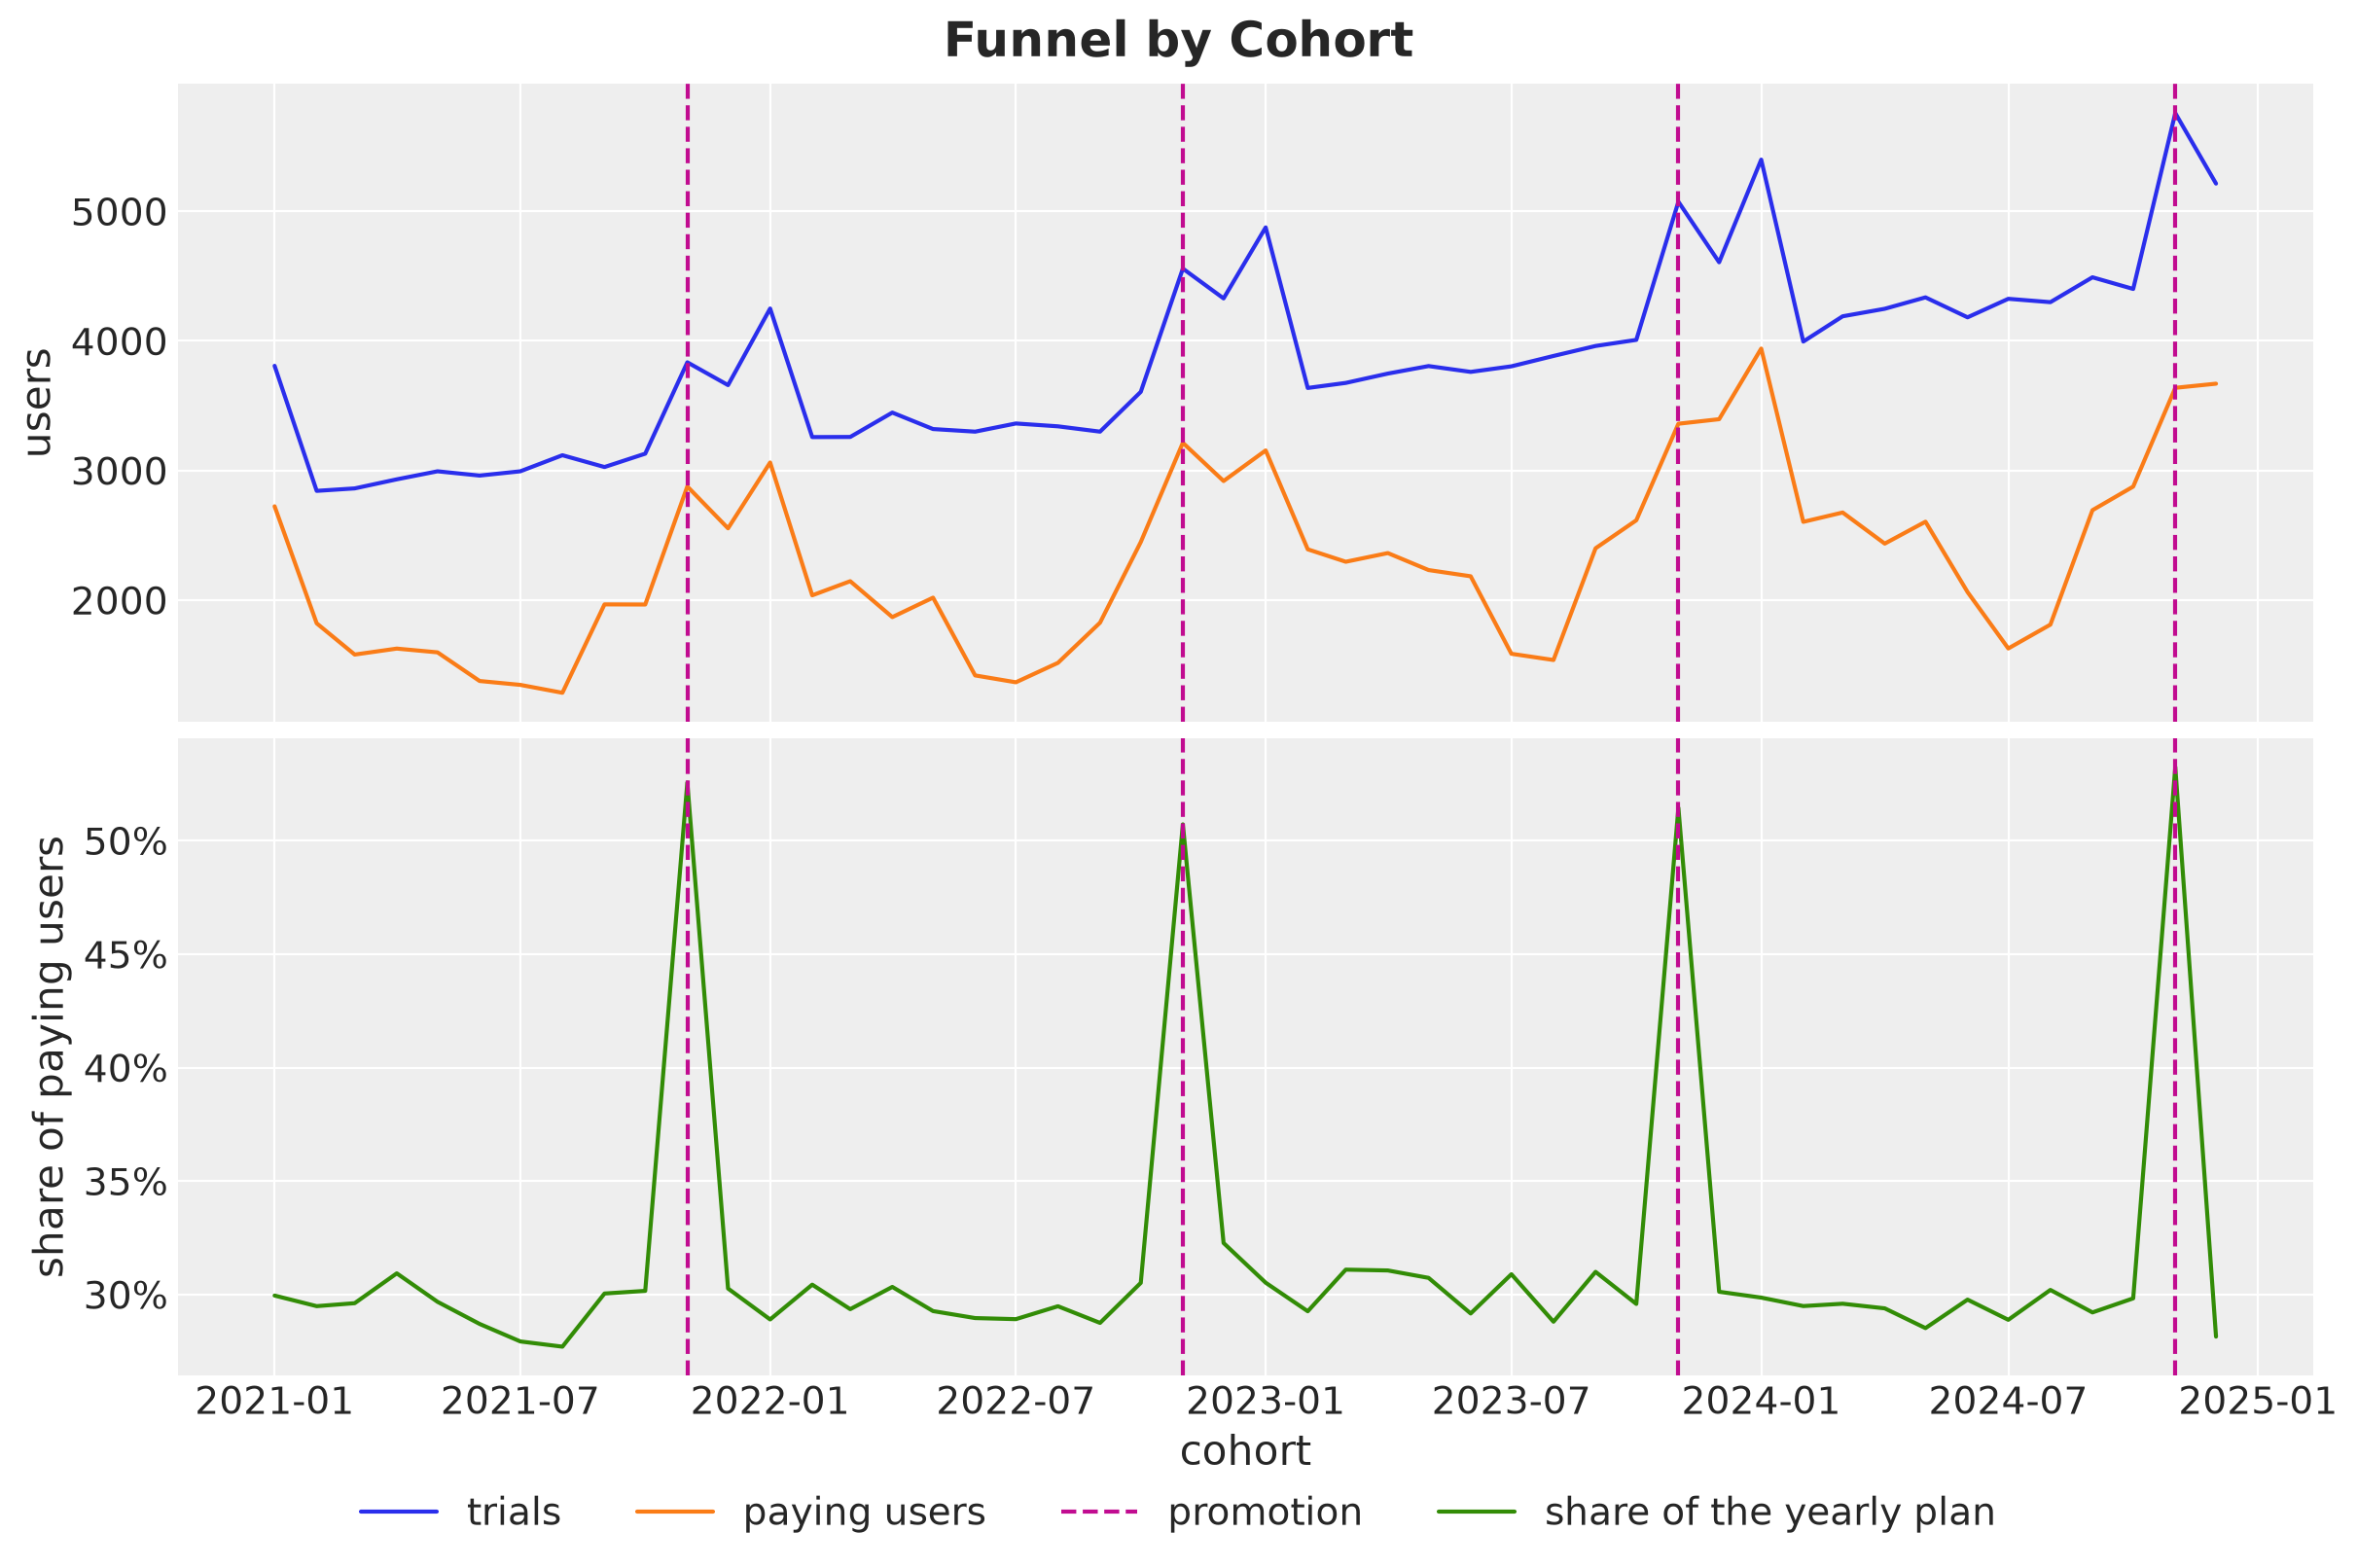

In [13]:
cohort_dates = np.array(data.cohort_labels, dtype="datetime64[M]")
promo_dates = cohort_dates[data.cohorts["promo"].to_numpy() > 0]

fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(12, 8), sharex=True, layout="constrained"
)
ax = axes[0]
ax.plot(cohort_dates, data.cohorts["n_trials"], color="C0", label="trials")
ax.plot(cohort_dates, data.cohorts["n_paid"], color="C1", label="paying users")
ax.set(ylabel="users")
ax = axes[1]
ax.plot(
    cohort_dates,
    data.cohorts["n_yearly"] / data.cohorts["n_paid"],
    color="C2",
    label="share of the yearly plan",
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="cohort", ylabel="share of paying users")

for ax in axes:
    for i, date in enumerate(promo_dates):
        ax.axvline(
            date,
            color="C3",
            linestyle="--",
            label="promotion" if ax is axes[0] and i == 0 else None,
        )

fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Funnel by Cohort", fontsize=18, fontweight="bold");

The trials grow over the years and are highest from November to January. The conversion drops in the summer, so the paying users dip in July and August while the trials stay flat. In every November the promotion lifts the share of the yearly plan from about $30\%$ to more than $50\%$.

Next, let's look for the quality of the cohorts in the data. For each cohort we compute three rates: the conversion, the **first-month churn** of the monthly plan (the share of its net starts who do not pay a second time) and the renewal of the yearly plan.

From each rate we subtract its mean over the cohorts of the same calendar month, which removes the season and the promotion. We plot the deviations of the churn and of the renewal against the deviation of the conversion.

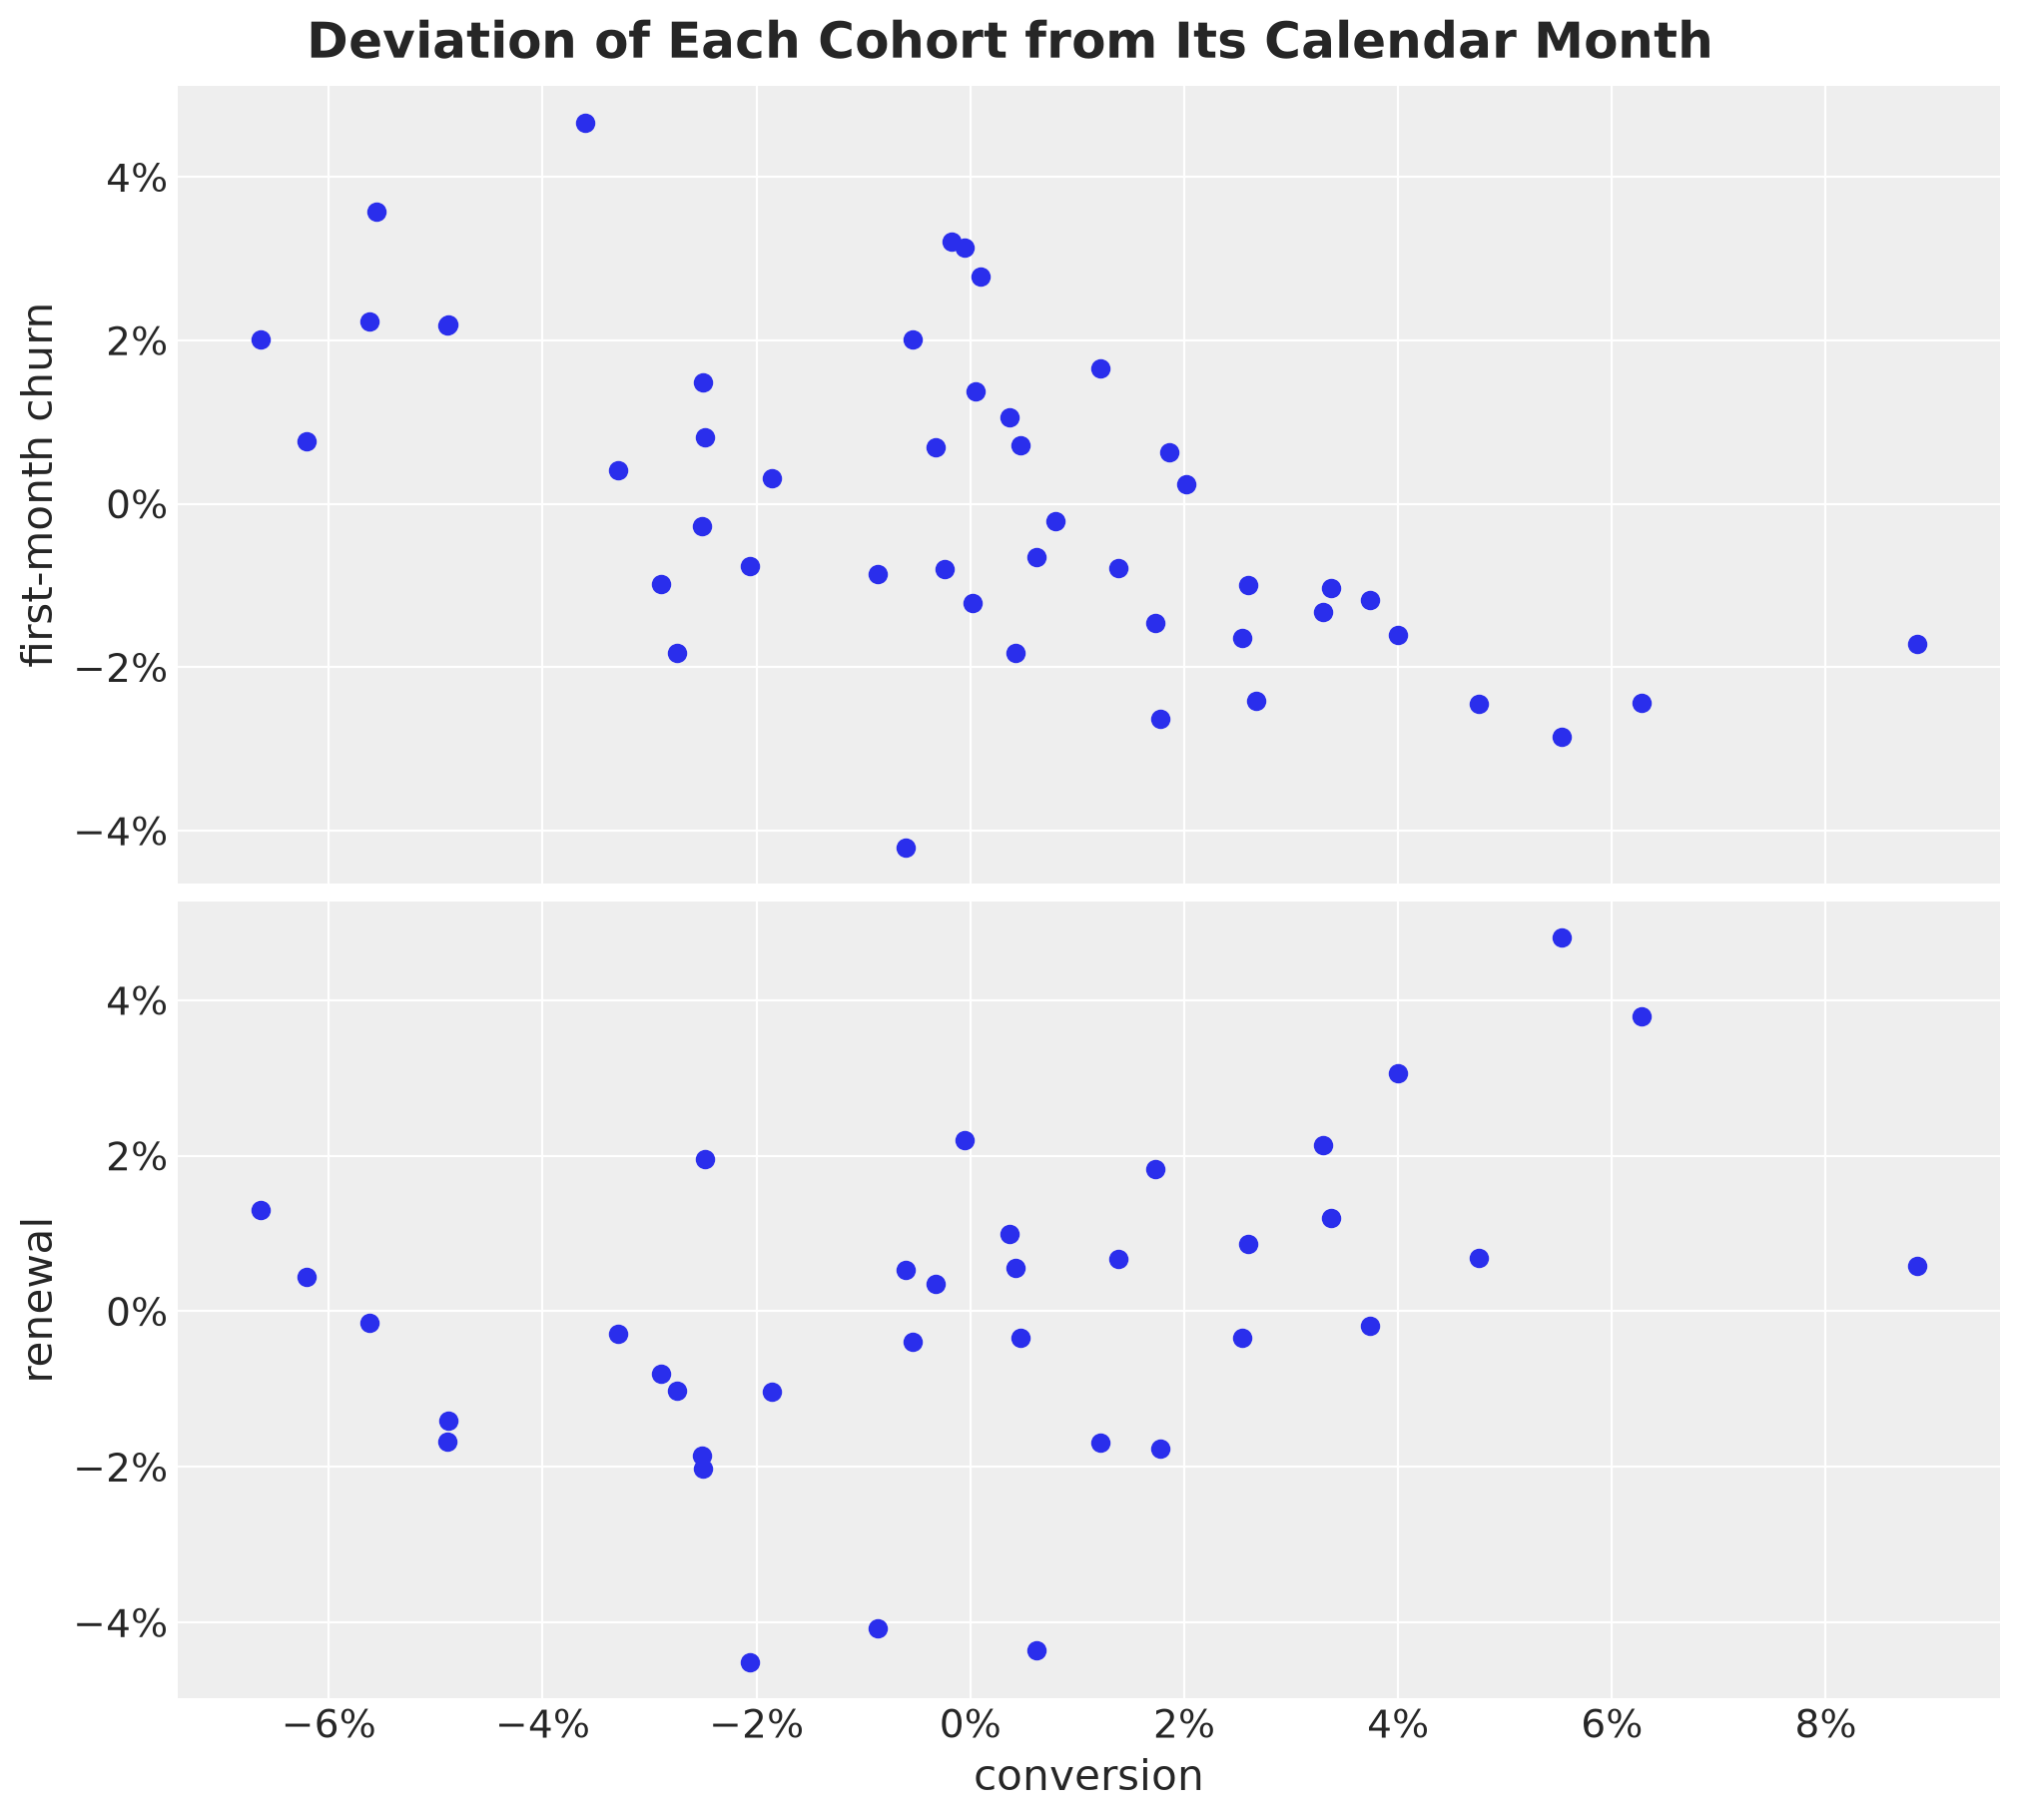

In [14]:
rates = ["conversion", "churn", "renewal"]

cohort_rates = (
    data.cohorts.join(
        data.transitions.filter(pl.col("age") == 1).select(
            "cohort", churn=1 - pl.col("n_payments") / pl.col("n_previous")
        ),
        on="cohort",
        how="left",
    )
    .join(
        data.renewals.select("cohort", n_renewed="n_payments"), on="cohort", how="left"
    )
    .with_columns(
        conversion=pl.col("n_paid") / pl.col("n_trials"),
        renewal=pl.col("n_renewed") / pl.col("n_starts_yearly"),
    )
    .with_columns(
        (pl.col(rate) - pl.col(rate).mean().over("start_month")).alias(rate)
        for rate in rates
    )
)

fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(10, 9), sharex=True, layout="constrained"
)
axes[0].scatter(cohort_rates["conversion"], cohort_rates["churn"], color="C0")
axes[0].set(ylabel="first-month churn")
axes[1].scatter(cohort_rates["conversion"], cohort_rates["renewal"], color="C0")
axes[1].set(xlabel="conversion", ylabel="renewal")

for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

fig.suptitle(
    "Deviation of Each Cohort from Its Calendar Month", fontsize=18, fontweight="bold"
);

Each point is a cohort. A cohort that converts better than the other cohorts of its calendar month tends to churn less in its first month and to renew more. We know the conversion of a cohort in its first month, so it carries information about the payments that are still to come.

Finally, let's look at the monthly plan over the ages. At the freeze the oldest cohorts are complete and the youngest one has made its first payment. We plot the **observed survival**, the share $A_{c,a} / N_{c,\text{monthly}}$ of the net starts that are still active, for every cohort and age that we have observed.

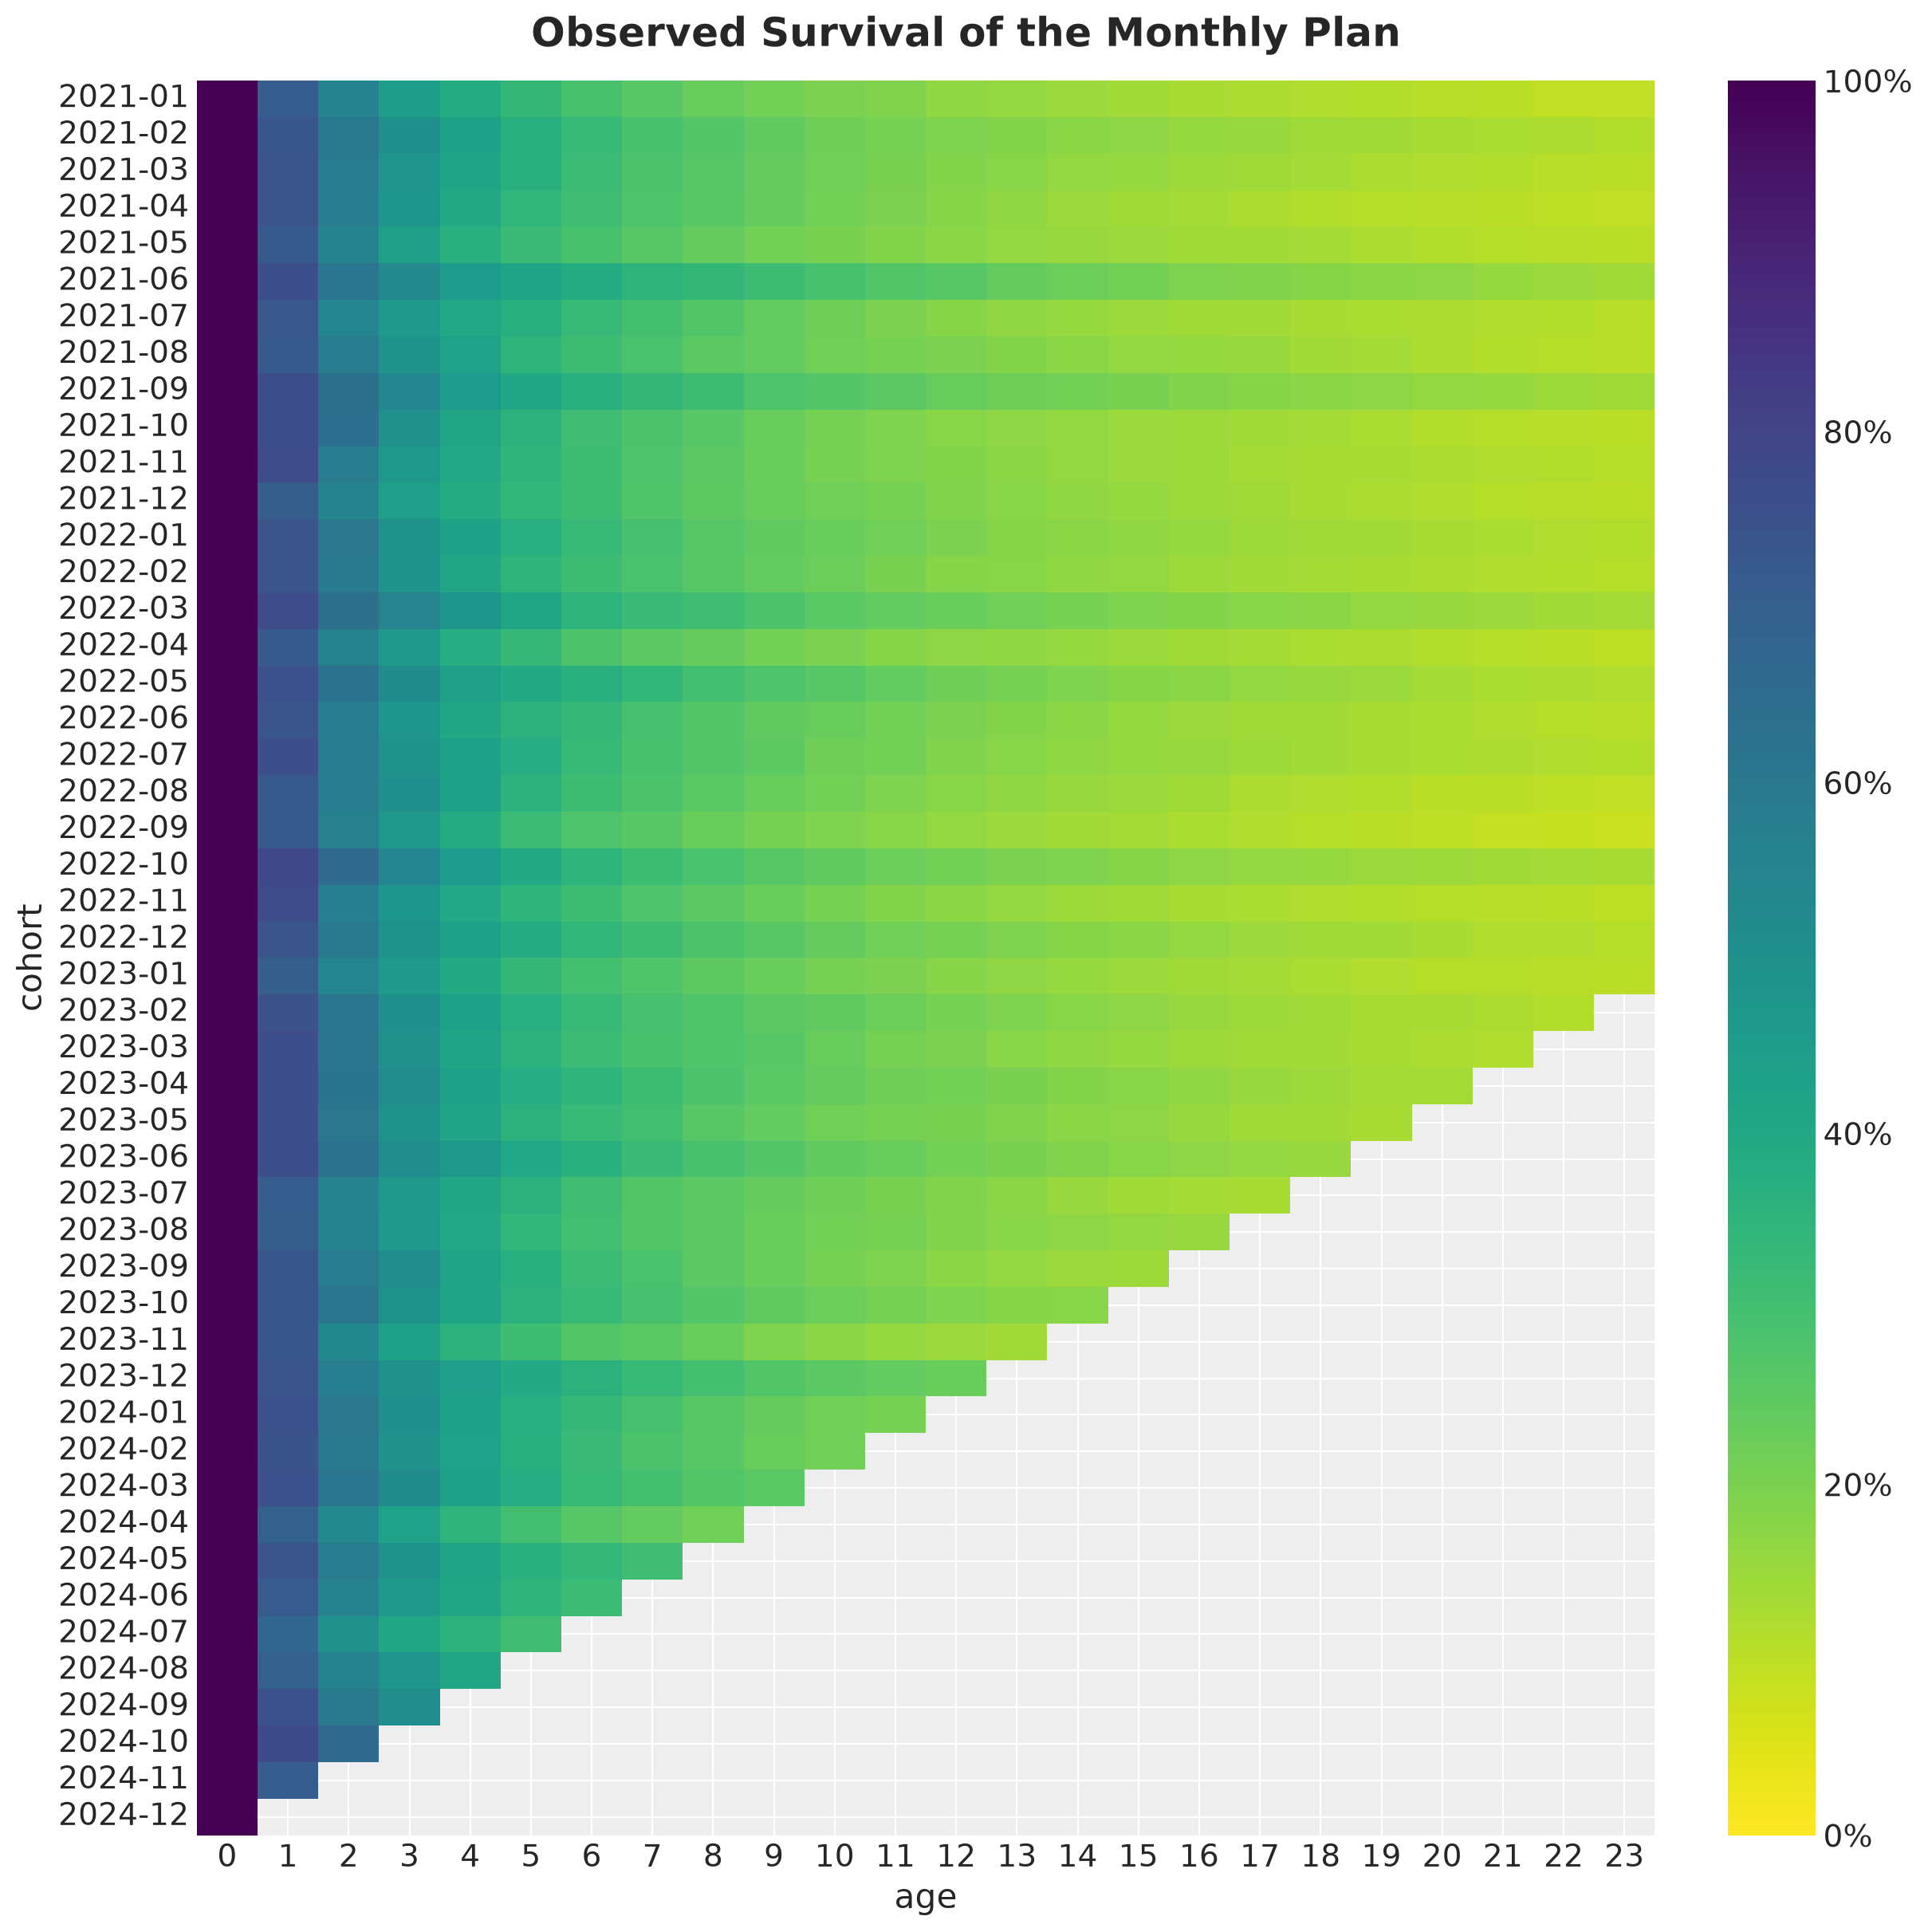

In [15]:
observed_survival = (
    data.payments.filter(pl.col("plan") == Plan.MONTHLY)
    .join(data.cohorts.select("cohort", "n_starts_monthly"), on="cohort")
    .with_columns(survival=pl.col("n_payments") / pl.col("n_starts_monthly"))
    .pivot(on="age", index="cohort", values="survival")
    .sort("cohort")
)

fig, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(
    observed_survival.drop("cohort").to_numpy(),
    cmap="viridis_r",
    vmin=0,
    vmax=1,
    yticklabels=data.cohort_labels,
    cbar_kws={"format": PercentFormatter(xmax=1, decimals=0)},
    ax=ax,
)
ax.set(xlabel="age", ylabel="cohort")
fig.suptitle("Observed Survival of the Monthly Plan", fontsize=18, fontweight="bold");

We make two observations:

- The survival falls fast in the first months and slowly afterward, as survivor selection predicts.
- Some cohorts keep more or fewer users than their neighbors at every age, which shows as a darker or a lighter row. This is consistent with a cohort effect of the churn, and in the November rows with the promotion as well. For a young cohort the model has to learn this effect from the conversion and from the first months of churn.

Now that we have the data, we can describe the funnel model.

## Model Specification

### Funnel Model

The funnel model has one GLM for each step after the trials. The plan choice, the refunds and the payments have the same form as in the generator. The conversion and the renewal have the same form as well, including their cohort effects.

For the churn the model takes another view than the generator. The data have no record of single users, only the counts of active users of each cohort, so the model describes the hazard $\bar{h}_c(a)$ of the whole cohort, a population-averaged quantity. We write the parameters of the churn and the cohort effects of the model with a bar, to keep them apart from the parameters of the generator.

The hazard has the following components:

- $\bar{\omega}$ is the logit of the hazard at age $1$ for a typical cohort in an average month, that is, the first-month churn.
- $\bar{\chi}_a$ is the **age effect**. It is a random walk over the ages, with $\bar{\chi}_1 = 0$ and increments $\varepsilon_a$ of scale $\bar{\sigma}_{\chi}$, so it can take the shape that survivor selection gives it.
- $\bar{\delta}_m$ is the season of the payment month.
- $\bar{\kappa}$ is the promotion effect at age $1$, and $\bar{u}_{c,\text{churn}}$ is the cohort effect at age $1$. Both fade with age through $g_{\bar{\lambda}}(a) = 1 / (1 + \bar{\lambda} (a - 1))$, as the persistent shift of the *Survivor Selection* section.

The three cohort effects $\bar{u}_{c,s}$ follow a multivariate Normal distribution with mean zero and covariance matrix $\bar{\Sigma}$. We build $\bar{\Sigma}$ from the standard deviations $\bar{\sigma}_s$ and a correlation matrix $\bar{\Omega}$.

The prior of $\bar{\Omega}$ is the **LKJ distribution** of Lewandowski, Kurowicka and Joe (2009), a distribution over correlation matrices with one parameter. With the value $1$ it is uniform over all correlation matrices, and larger values pull the correlations toward zero. For more details on correlated group effects with this prior, see [Multilevel Elasticities for a Single SKU](https://juanitorduz.github.io/multilevel_elasticities_single_sku/).

Here is the model:

$$
\begin{align*}
\left(\bar{u}_{c,\text{conversion}}, \bar{u}_{c,\text{churn}}, \bar{u}_{c,\text{renewal}}\right) & \sim \text{MvNormal}\left(0, \bar{\Sigma}\right), \quad \bar{\Sigma} = \text{diag}(\bar{\sigma}) \, \bar{\Omega} \, \text{diag}(\bar{\sigma}), \quad \bar{\Omega} \sim \text{LKJ}(2) \\
P_c & \sim \text{Binomial}\left(T_c, \text{logit}^{-1}\left(\gamma_0 + \gamma^{\text{s}}_{m_c} + \bar{u}_{c,\text{conversion}}\right)\right) \\
Y_c & \sim \text{Binomial}\left(P_c, \text{logit}^{-1}\left(\psi_0 + \psi_1 z_c\right)\right) \\
F_{c,k} & \sim \text{Binomial}\left(P_{c,k}, \text{logit}^{-1}\left(\rho_k\right)\right) \\
A_{c,a} & \sim \text{Binomial}\left(A_{c,a-1}, 1 - \bar{h}_c(a)\right) \\
\text{logit}\, \bar{h}_c(a) & = \bar{\omega} + \bar{\chi}_a + \bar{\delta}_{m_c + a} + g_{\bar{\lambda}}(a) \left(\bar{\kappa} z_c + \bar{u}_{c,\text{churn}}\right) \\
\bar{\chi}_1 = 0, \quad \bar{\chi}_a & = \bar{\chi}_{a-1} + \varepsilon_a, \quad \varepsilon_a \sim \text{Normal}(0, \bar{\sigma}_{\chi}) \\
Q_c & \sim \text{Binomial}\left(N_{c,\text{yearly}}, \text{logit}^{-1}\left(\eta_0 + \eta_1 z_c + \bar{u}_{c,\text{renewal}}\right)\right) \\
X_{c,k,a} & \sim \text{Gamma}\left(B_{c,k,a} \nu_k, \nu_k / \mu_k\right).
\end{align*}
$$

The seasons sum to zero as in the generator, and the *Prior Elicitation* section gives the priors of the other parameters.

The churn step is a discrete-time hazard model in the sense of Allison (1982): a logistic regression of the users who pay again on the users who could.

We add some remarks on the model:

- **No quality variable:** The model has three correlated effects for each cohort and no quality $q_c$. Unlike the generator, it does not assume that one factor drives the three effects.
- **Shared effects:** The conversion, the churn and the renewal share the cohort effects. A cohort that has paid for a few months informs its own effects, and partial pooling shrinks them toward zero when the cohort has little data. For a step that a young cohort has not reached, the model predicts the effect from the effects of the steps that it has reached, through the correlations.
- **Separate steps:** The plan choice, the refunds and the payments share no parameter with the other steps, and each of their likelihoods conditions on the observed counts of the step before. The posterior of each of these three steps is therefore the same as in a separate fit.

We add the value per trial $V_m$ to the model as a deterministic, with the `value_per_trial` function and the grid of nodes of the generator, now with the Cholesky factor of $\bar{\Sigma}$. Every posterior draw then gives the value per trial directly.

### Prior Elicitation

For the rates of the funnel we state a range on the probability scale and use [PreliZ](https://preliz.readthedocs.io/) to turn it into a prior. The function `pz.maxent` returns the member of a family that puts a given mass in a range (the one with maximum entropy, so it adds nothing beyond our constraints). We ask for $94\%$ of the mass in the range. Here are the ranges that we believe before we look at the data:

- **Conversion:** Between $20\%$ and $90\%$ of the trials convert. A free trial attracts users who never intend to pay, so we allow a low conversion.
- **Yearly share:** Between $5\%$ and $70\%$ of the paying users choose the yearly plan, since it asks for a larger payment up front.
- **Refund:** Between $0.5\%$ and $25\%$ of the first payments are refunded, for each plan. We expect refunds to be the exception.
- **First-month churn:** Between $5\%$ and $60\%$ of the net starts of the monthly plan do not pay a second time.
- **Renewal:** Between $10\%$ and $80\%$ of the net starts of the yearly plan renew.

For these five quantities we use a `LogitNormal`. If a probability follows a LogitNormal distribution, its logit follows a Normal distribution with the same two parameters, which is the prior of the intercept on the logit scale.

For the revenue we reason about two more quantities:

- **Revenue per payment:** The average payment is between $70\%$ and $105\%$ of the list price, since regional prices and coupons lower it and a price increase could raise it a little. We use a `LogNormal` for this ratio, so the log of the revenue per payment $\log \mu_k$ is Normal around the log of the list price.
- **Variation of a payment:** A single payment varies around its mean with a coefficient of variation between $5\%$ and $50\%$. For a Gamma with shape $\nu_k$ the coefficient of variation is $1 / \sqrt{\nu_k}$, so $\log \nu_k$ is $-2$ times the log of the coefficient of variation. We use a `LogNormal` for the coefficient of variation, multiply the mean of its log by $-2$ and its standard deviation by $2$, and get a `LogNormal` prior for $\nu_k$.

The function `elicit` runs the elicitations and asserts that every prior puts the mass that we asked for in its range. We plot each density on the scale on which we reasoned, with its range.

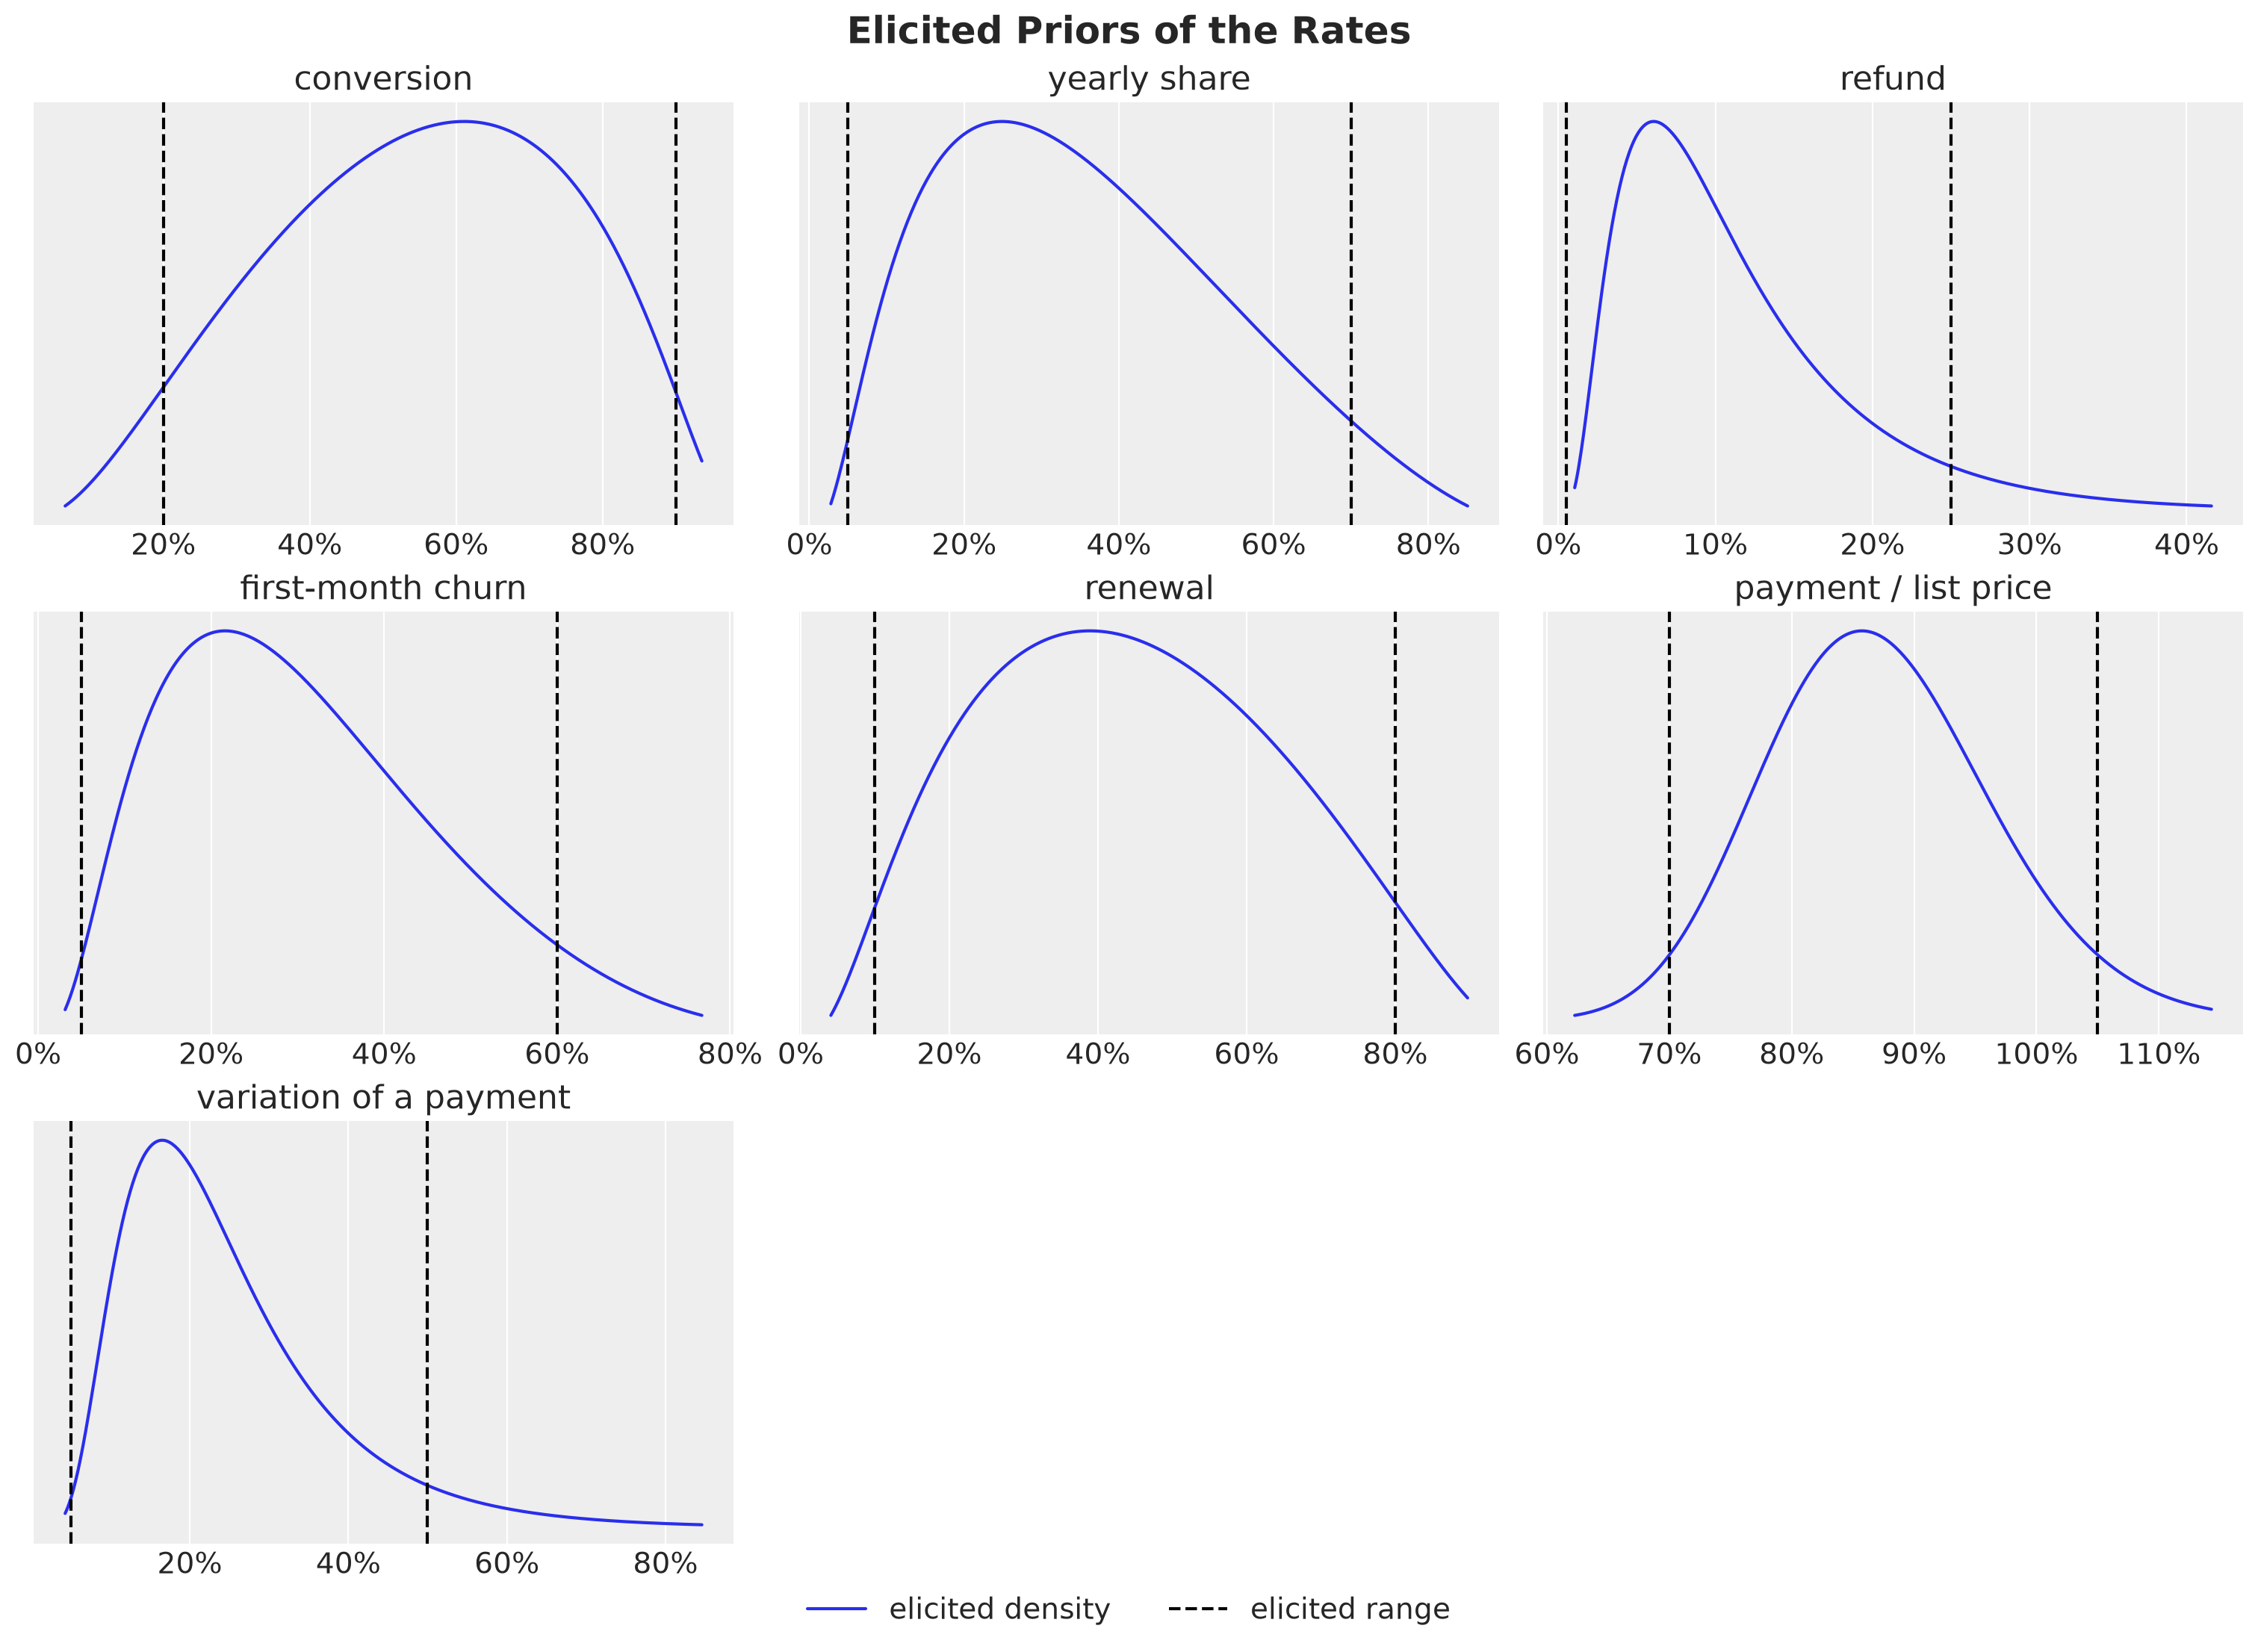

In [16]:
class Elicitation(NamedTuple):
    """A range that we believe in, and the PreliZ family that we fit to it."""

    lower: float
    upper: float
    family: pz.distributions.distributions.Continuous
    label: str


ELICITATION_MASS: Final[float] = 0.94


def elicit(elicitations: dict[str, Elicitation]) -> dict:
    """Maximum entropy member of each family with the elicited mass in its range."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        priors = {
            name: pz.maxent(
                elicitation.family,
                elicitation.lower,
                elicitation.upper,
                mass=ELICITATION_MASS,
                plot=False,
            )
            for name, elicitation in elicitations.items()
        }

    for name, elicitation in elicitations.items():
        mass = priors[name].cdf(elicitation.upper) - priors[name].cdf(elicitation.lower)
        assert np.isclose(mass, ELICITATION_MASS, atol=1e-3)

    return priors


def plot_elicitation(ax: plt.Axes, elicitation: Elicitation, prior) -> None:
    """Density of an elicited prior on the scale of its range, with the range."""
    x = np.linspace(*prior.ppf([0.001, 0.995]), 500)
    ax.plot(x, prior.pdf(x), color="C0", label="elicited density")
    ax.axvline(elicitation.lower, color="black", linestyle="--", label="elicited range")
    ax.axvline(elicitation.upper, color="black", linestyle="--")
    ax.set(title=elicitation.label, yticks=[])


rate_elicitations = {
    "conversion": Elicitation(0.2, 0.9, pz.LogitNormal(), "conversion"),
    "yearly": Elicitation(0.05, 0.7, pz.LogitNormal(), "yearly share"),
    "refund": Elicitation(0.005, 0.25, pz.LogitNormal(), "refund"),
    "churn": Elicitation(0.05, 0.6, pz.LogitNormal(), "first-month churn"),
    "renewal": Elicitation(0.1, 0.8, pz.LogitNormal(), "renewal"),
    "revenue_ratio": Elicitation(0.7, 1.05, pz.LogNormal(), "payment / list price"),
    "payment_cv": Elicitation(0.05, 0.5, pz.LogNormal(), "variation of a payment"),
}
rate_priors = elicit(rate_elicitations)

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 11), layout="constrained")

for ax, (name, elicitation) in zip(axes.flat, rate_elicitations.items(), strict=False):
    plot_elicitation(ax, elicitation, rate_priors[name])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

for ax in axes.flat[len(rate_elicitations) :]:
    ax.remove()

fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors of the Rates", fontsize=18, fontweight="bold");

Every prior spreads its mass over the range that we stated. The true values of the generator lie inside these ranges:

- $60\%$ conversion and $30\%$ yearly share.
- Refunds of $2\%$ and $12\%$.
- $25\%$ first-month churn and $32\%$ renewal.
- Payments at $95\%$ and $93\%$ of the list price.
- Coefficients of variation of $1 / \sqrt{40} \approx 16\%$ and $1 / \sqrt{60} \approx 13\%$.

The other parameters are effects and scales on the logit scale. We elicit them in the same way:

- **Promotion:** We reason about the factor by which the promotion multiplies the odds of each step and use a `LogNormal`, so the effect on the logit scale is Normal. Each range leaves the opposite direction possible.
    - The promotion advertises the yearly plan, so we expect a factor between $0.6$ and $4.5$ for the yearly share.
    - We assume that it brings users who are more sensitive to the price, so we expect a factor between $0.7$ and $2.1$ for the churn and between $0.25$ and $1.6$ for the renewal.
- **Seasons:** The scale of the season is between $0$ and $1$ for the conversion and between $0$ and $0.6$ for the churn. We use a `HalfNormal` for every scale.
- **Age increments:** The scale $\bar{\sigma}_{\chi}$ is between $0$ and $0.6$. Under the sBG model the logit of the hazard falls by about $0.3$ from age $1$ to age $2$ and by less afterward, so this range allows the increments that survivor selection produces.
- **Fading rate:** The rate $\bar{\lambda}$ is between $0$, which means no fading, and $1$. The range covers the value $1 / (\alpha + \beta) = 0.25$ of the sBG cohort.
- **Cohort effects:** Each standard deviation $\bar{\sigma}_s$ is between $0$ and $0.4$. At the upper end the odds of a step in a cohort one standard deviation above the typical cohort are $e^{0.4} \approx 1.5$ times as large.
- **Correlations:** We use $\text{LKJ}(2)$. With three effects the prior of each correlation is then a $\text{Beta}(2.5, 2.5)$ distribution stretched to the interval from $-1$ to $1$ (Lewandowski, Kurowicka and Joe 2009). It is centered on zero and puts little mass near $-1$ and $1$.

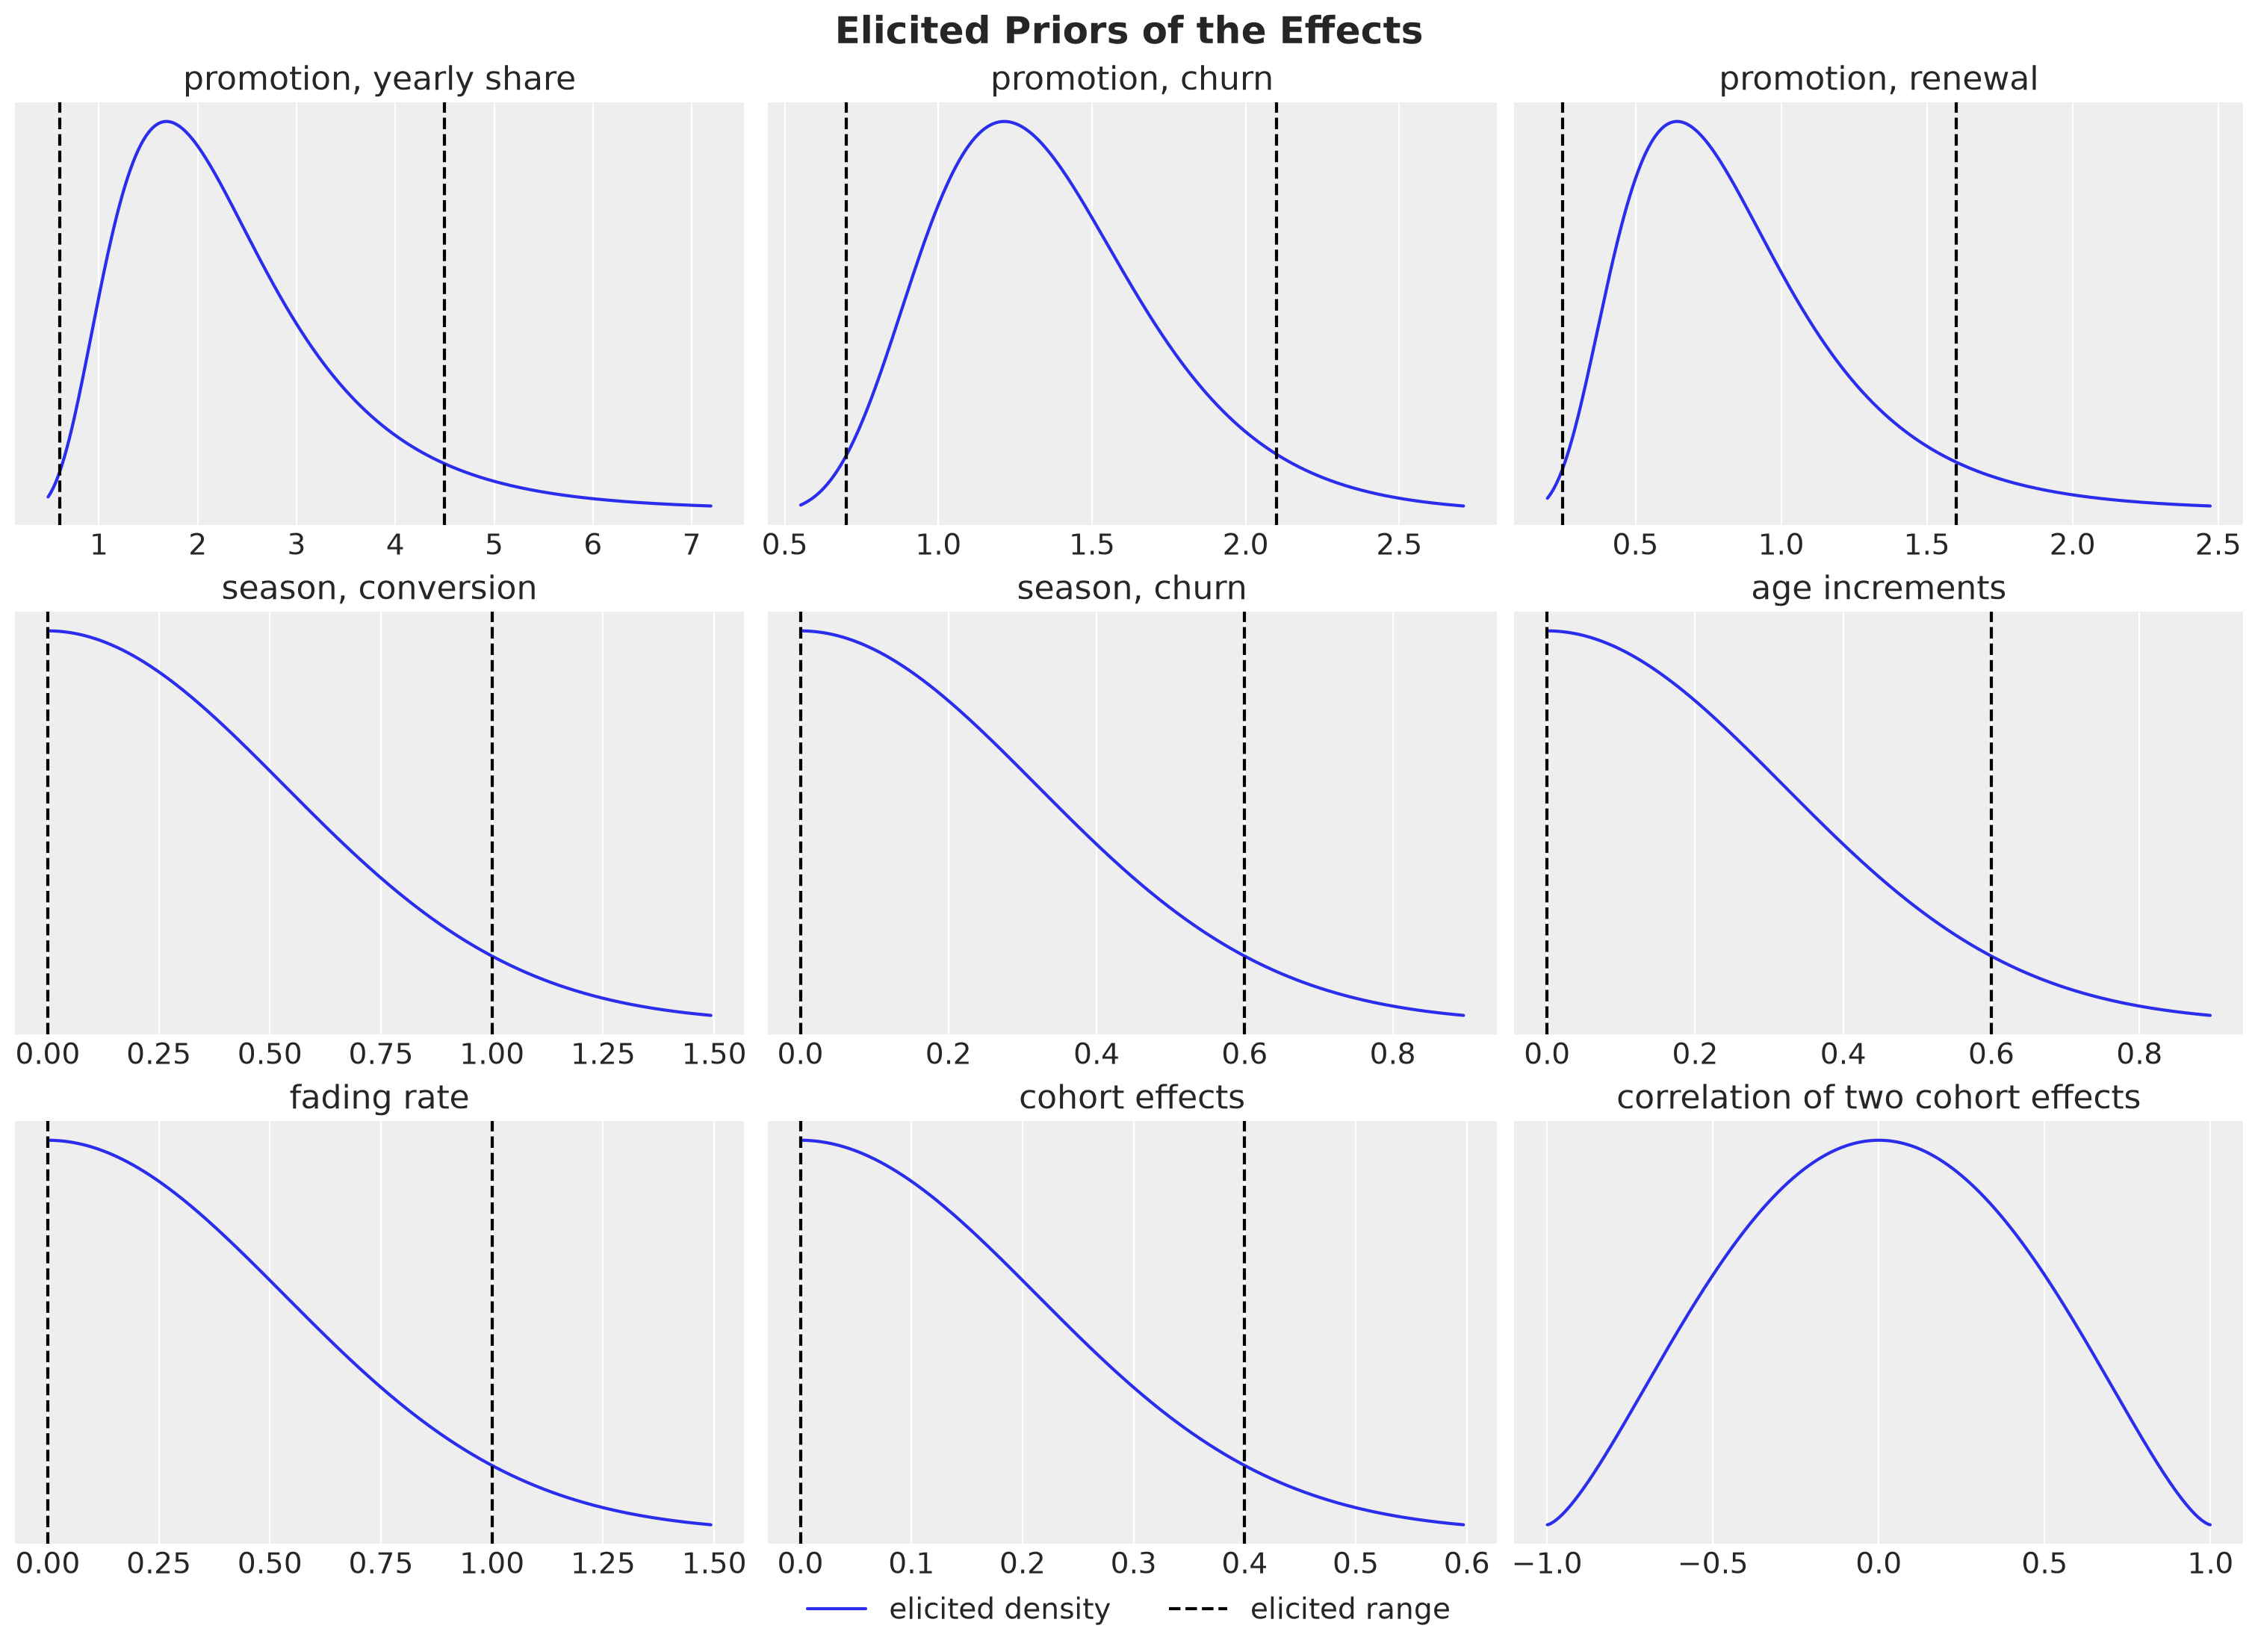

In [17]:
LKJ_ETA: Final[float] = 2.0

effect_elicitations = {
    "yearly_promo": Elicitation(0.6, 4.5, pz.LogNormal(), "promotion, yearly share"),
    "churn_promo": Elicitation(0.7, 2.1, pz.LogNormal(), "promotion, churn"),
    "renewal_promo": Elicitation(0.25, 1.6, pz.LogNormal(), "promotion, renewal"),
    "conversion_sigma": Elicitation(0.0, 1.0, pz.HalfNormal(), "season, conversion"),
    "churn_season_sigma": Elicitation(0.0, 0.6, pz.HalfNormal(), "season, churn"),
    "age_sigma": Elicitation(0.0, 0.6, pz.HalfNormal(), "age increments"),
    "fading_rate": Elicitation(0.0, 1.0, pz.HalfNormal(), "fading rate"),
    "cohort_sigma": Elicitation(0.0, 0.4, pz.HalfNormal(), "cohort effects"),
}
priors = rate_priors | elicit(effect_elicitations)

correlation_values = np.linspace(-0.999, 0.999, 500)
lkj_marginal = pz.Beta(
    LKJ_ETA - 1 + len(CohortStep) / 2, LKJ_ETA - 1 + len(CohortStep) / 2
)

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 11), layout="constrained")

for ax, (name, elicitation) in zip(
    axes.flat, effect_elicitations.items(), strict=False
):
    plot_elicitation(ax, elicitation, priors[name])

ax = axes.flat[-1]
ax.plot(
    correlation_values, lkj_marginal.pdf((correlation_values + 1) / 2) / 2, color="C0"
)
ax.set(title="correlation of two cohort effects", yticks=[])
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors of the Effects", fontsize=18, fontweight="bold");

The priors of the three promotion effects lean toward the direction that we expect and leave mass on both sides of one, the value of no effect. The priors of the scales have their mode at zero, so the model can switch an effect off if the data do not show it.

### Calendar Time

In the *Backtest* section we fit the same model at many freezes and forecast from each of them. PyMC-Forecast is built for this task. We write the model once, as a function of the data up to a date, and the package builds it for the fit and for the forecast.

At a freeze we know every payment up to one month and nothing after it. Neither the cohort nor the age splits the churn data into a known part and an unknown part in this way, but the month of the payment does. PyMC-Forecast calls the two parts `time` and `time_future`.

Recall that the `period` column counts the months since January 2021. We write $t$ for it, so that cohort $c$ starts in period $t = c$ and reaches age $a$ in period $t = c + a$. We arrange the churn data by period and age:

- **Rows:** There is one row for each period $t$ up to the freeze.
- **Columns:** There is one column for each age $a = 1, \dots, 23$.
- **Cells:** The cell $(t, a)$ holds the users of cohort $c = t - a$ who could churn at age $a$, and the ones who pay again.

The functions `at_risk_table` and `retained_table` build the two tables from the data of a freeze, and `forecast_months` adds the $23$ months that the youngest cohort has left. The package carries the months in a table of covariates, which has no columns here (`null_covariates`).

Let's look at the users who could churn at the freeze of December 2024, from January 2023 on.

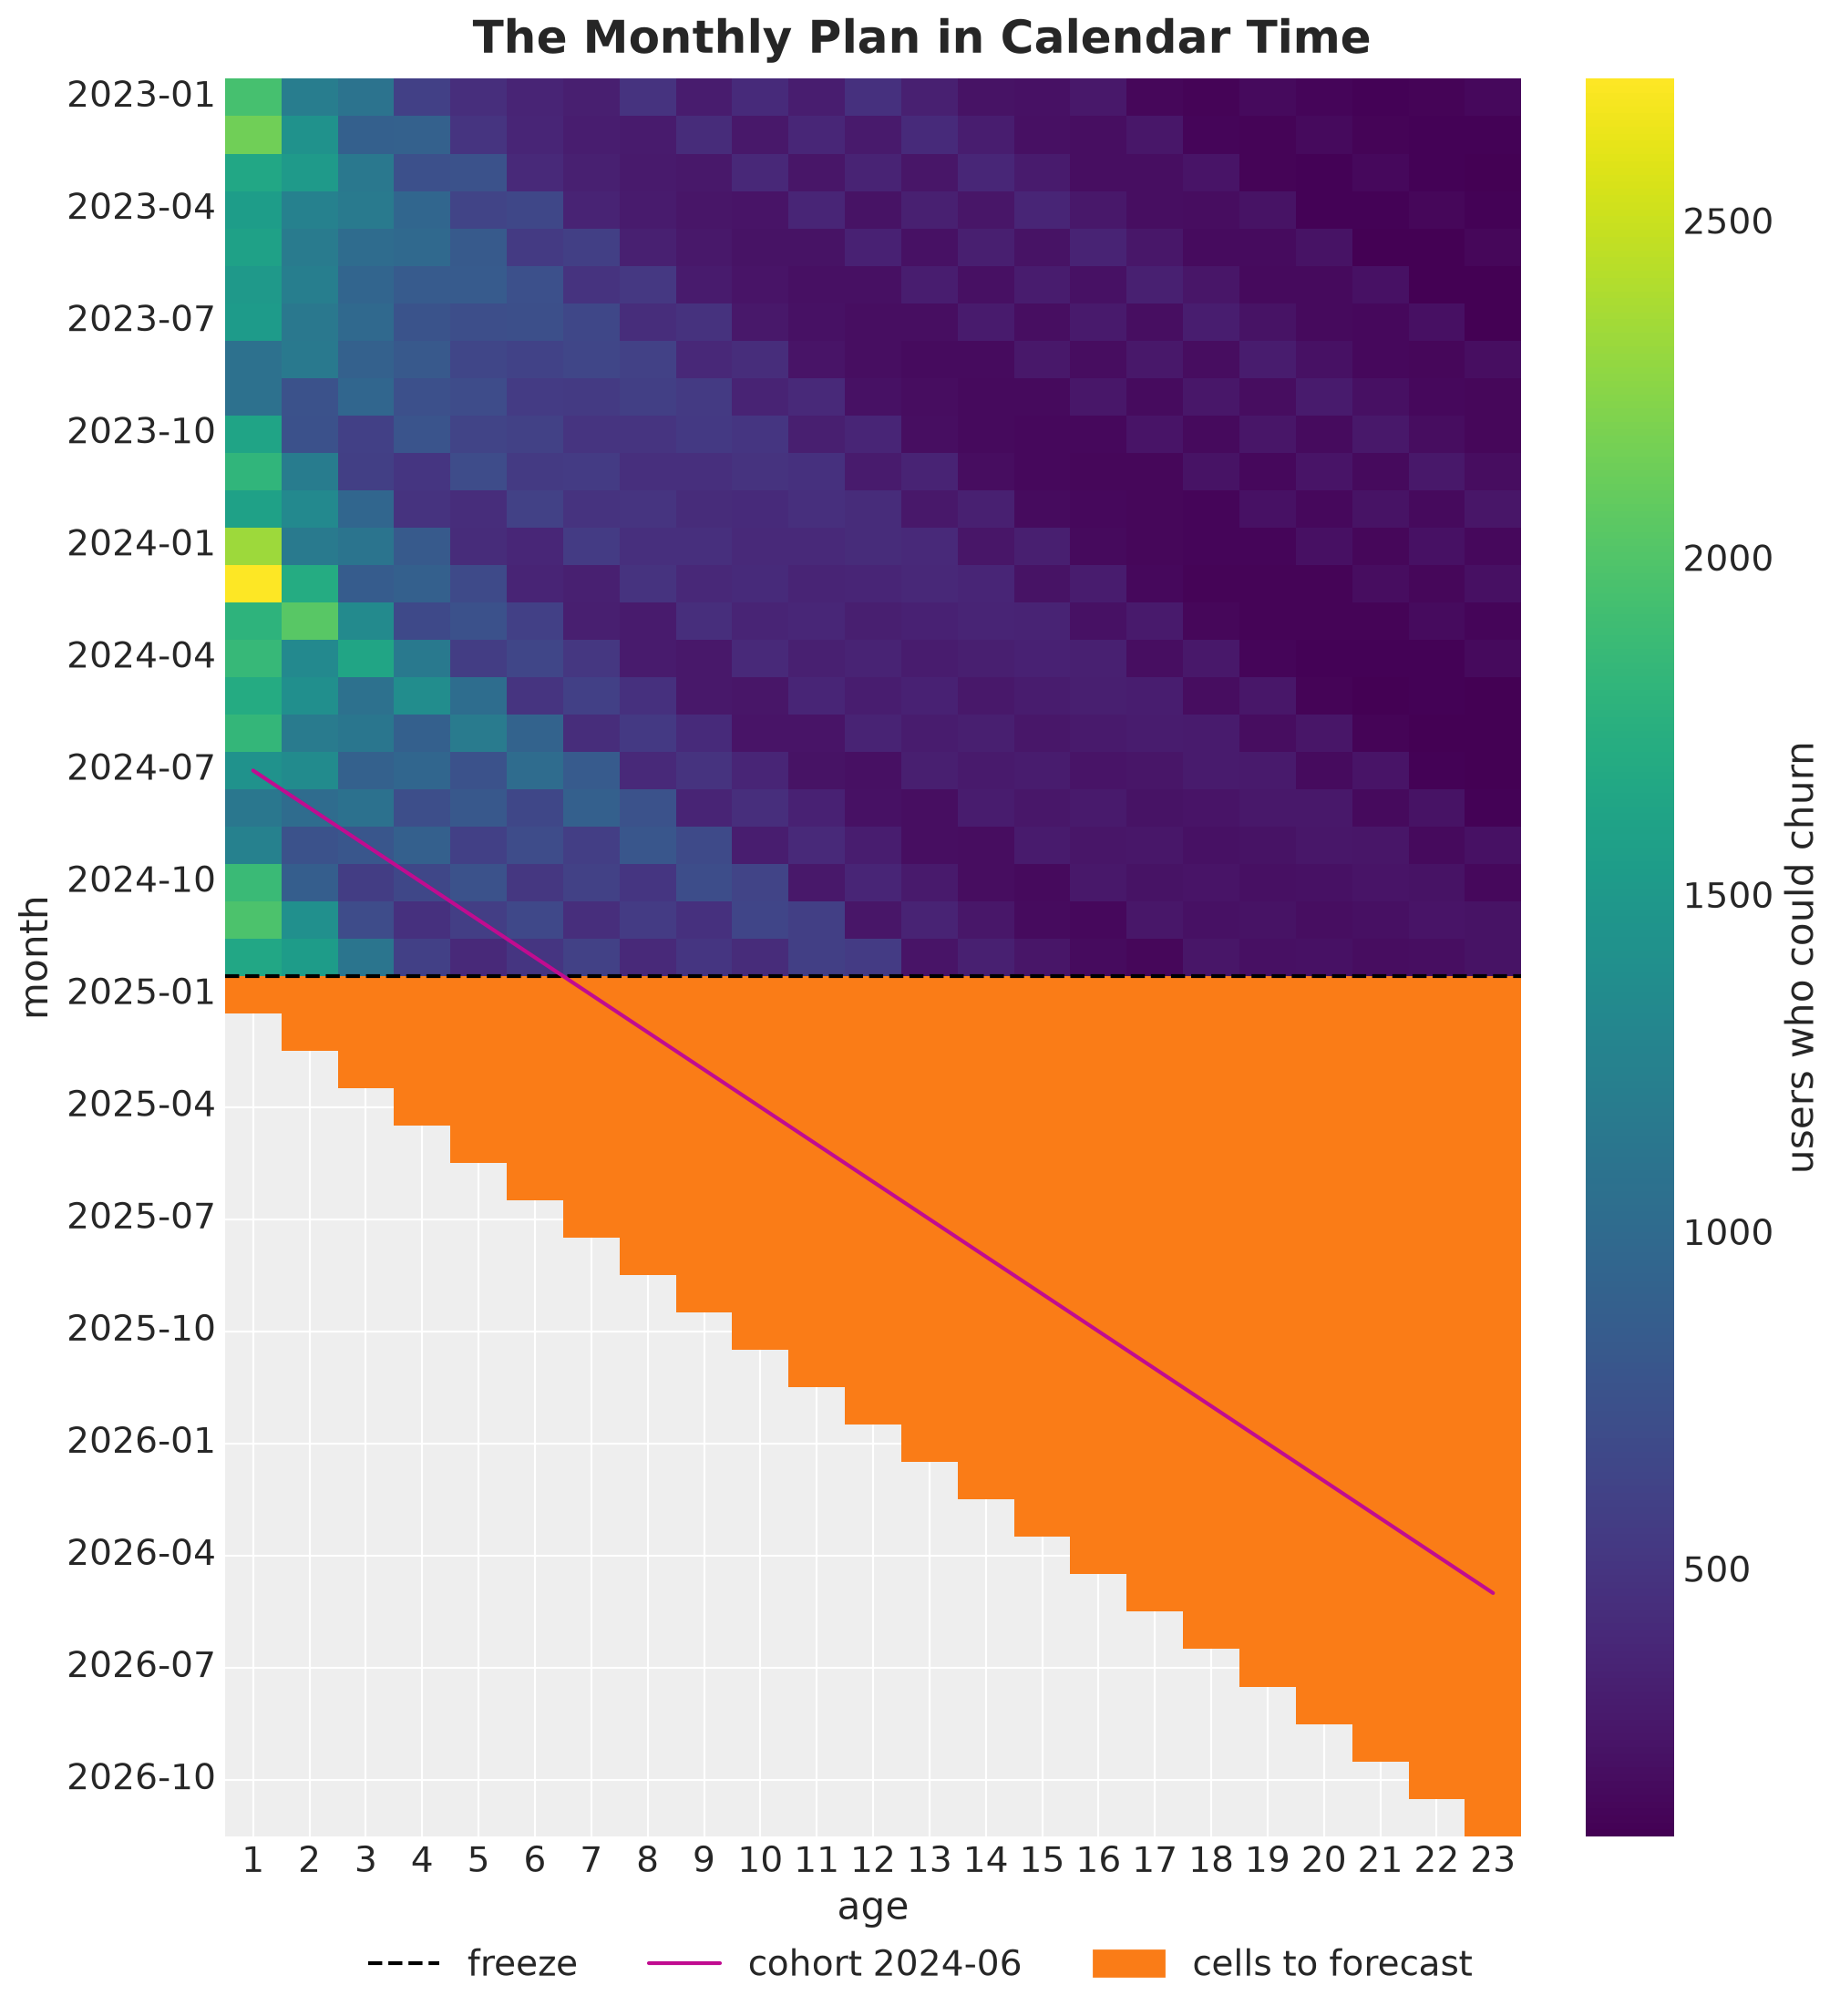

In [18]:
def month_table(data: FunnelData, column: str) -> xr.DataArray:
    """A column of the transitions of the monthly plan, by period and age."""
    transitions = data.transitions
    values = np.zeros((data.freeze + 1, len(calendar.hazard_ages)), dtype=int)
    values[transitions["period"].to_numpy(), transitions["age"].to_numpy() - 1] = (
        transitions[column].to_numpy()
    )
    return xr.DataArray(
        values,
        dims=("time", "hazard_age"),
        coords={
            "time": calendar.month_labels(data.freeze + 1),
            "hazard_age": calendar.hazard_ages,
        },
    )


def retained_table(data: FunnelData) -> xr.DataArray:
    """Users of the monthly plan who pay again, by period and age."""
    return month_table(data, "n_payments")


def at_risk_table(data: FunnelData) -> xr.DataArray:
    """Users of the monthly plan who could churn, by period and age."""
    return month_table(data, "n_previous")


def forecast_months(data: FunnelData) -> xr.DataArray:
    """The months up to the freeze and the months that the youngest cohort has left."""
    return null_covariates(calendar.month_labels(data.freeze + calendar.horizon))


months = forecast_months(data)["time"].values
first_row = calendar.cohort_labels.index("2023-01")
example_cohort = calendar.cohort_labels.index("2024-06")
cell_cohort = np.arange(len(months))[:, None] - calendar.hazard_ages
is_future = (np.arange(len(months))[:, None] > data.freeze) & (
    cell_cohort <= data.freeze
)
at_risk = np.full(cell_cohort.shape, np.nan)
at_risk[: data.freeze + 1] = at_risk_table(data).where(lambda x: x > 0).values

fig, ax = plt.subplots(figsize=(10, 11), layout="constrained")
sns.heatmap(
    at_risk[first_row:],
    cmap="viridis",
    cbar_kws={"label": "users who could churn"},
    ax=ax,
)
sns.heatmap(
    np.where(is_future, 1.0, np.nan)[first_row:],
    cmap=ListedColormap(["C1"]),
    cbar=False,
    ax=ax,
)
ax.axhline(data.freeze + 1 - first_row, color="black", linestyle="--", label="freeze")
ax.plot(
    calendar.hazard_ages - 0.5,
    example_cohort + calendar.hazard_ages - first_row + 0.5,
    color="C3",
    label=f"cohort {calendar.cohort_labels[example_cohort]}",
)
ax.set_xticks(np.arange(len(calendar.hazard_ages)) + 0.5, calendar.hazard_ages)
ax.set_yticks(
    np.arange(0, len(months) - first_row, 3) + 0.5, months[first_row::3], rotation=0
)
ax.set(xlabel="age", ylabel="month")
handles, labels = ax.get_legend_handles_labels()
fig.legend(
    [*handles, Patch(color="C1")],
    [*labels, "cells to forecast"],
    loc="outside lower center",
    ncol=3,
)
fig.suptitle("The Monthly Plan in Calendar Time", fontsize=18, fontweight="bold");

We read the table as follows:

- **Cohorts:** A cohort moves down a diagonal, one age per month. The line follows the cohort `2024-06`, which is $6$ months old at the freeze.
- **Observed months:** Every row of the figure above the freeze holds the $23$ cohorts that could churn in that month, one per age.
- **Future months:** The cells that the open cohorts have left form a triangle below the freeze. The youngest cohort has $23$ months to go, and the oldest open cohort has one. We come back to these cells in the *Cohort Forecasts* section.
- **Empty cells:** The cells below the triangle belong to the cohorts that start after the freeze. They are not part of the forecast. The first rows of the table, which the figure does not show, are also empty at the ages that the first cohort has not reached.

A model for PyMC-Forecast is a function of all the months, observed and future, and of the observed table. Inside it, the function `predict` registers the likelihood of the observed rows under the name `obs` (the constant `OBS_VAR`) and the variable of the future rows under the name `forecast` (`FORECAST_VAR`).

For the fit, the package builds the model on the observed months. For the forecast, it builds the model again with the future months, replays the posterior draws of the parameters and draws the future variables.

### Implementation

We now write the model in PyMC, with one function for each step of the funnel. The parameters that the model shares with the generator keep their names. The symbols of the churn and of the cohort effects map to the following variables:

- $\bar{\omega}$ is `churn_intercept`, $\bar{\delta}_m$ is `churn_season` and $\bar{\kappa}$ is `churn_promo`.
- $\bar{\chi}_a$ is `age_effect`, with the increments `age_increment` and their scale `age_sigma`.
- $\bar{\lambda}$ is `fading_rate`.
- $\bar{u}_{c,s}$ is `cohort_effect`, $\bar{\sigma}_s$ is `cohort_sigma` and the three correlations of $\bar{\Omega}$ are `cohort_correlation`.

Two points of the implementation need a comment:

- **LKJ prior:** `pymc.dims` does not include it, so we use `pm.LKJCholeskyCov` from the classic API. It returns the Cholesky factor of $\bar{\Sigma}$, the correlation matrix and the standard deviations.
- **Parametrization:** We sample independent standard Normal variables `cohort_raw` and multiply them by the Cholesky factor to get the cohort effects. The youngest cohorts have no churn and no renewal data, and this **non-centered** form samples well when the data say little about an effect. The age increments are sampled directly, because thousands of users per cohort and age fix each of them.

We start with the cohort effects and the first three steps. Each function creates the priors of its step, adds its likelihood and returns its parameters.

In [19]:
COHORT_SIGMA_SITE: Final[str] = "cohort_sigma"
COHORT_CORRELATION: Final[str] = "cohort_correlation"
STEP_PAIRS: Final[list[tuple[CohortStep, CohortStep]]] = list(
    combinations(CohortStep, 2)
)


def normal_from(name: str, prior, **kwargs) -> pmd.XTensorVariable:
    """Normal prior on the logit or log scale from a LogitNormal or a LogNormal."""
    return pmd.Normal(name, prior.mu, prior.sigma, **kwargs)


def cohort_effects_prior() -> CohortEffects:
    """Correlated effects of each cohort on conversion, churn and renewal."""
    chol, corr, sd = pm.LKJCholeskyCov(
        "cohort_chol",
        n=len(CohortStep),
        eta=LKJ_ETA,
        sd_dist=pm.HalfNormal.dist(priors["cohort_sigma"].sigma),
        compute_corr=True,
        store_in_trace=False,
    )
    position = {step: i for i, step in enumerate(CohortStep)}
    pm.Deterministic(COHORT_SIGMA_SITE, sd, dims="cohort_step")
    pm.Deterministic(
        COHORT_CORRELATION,
        pt.stack(
            [corr[position[first], position[second]] for first, second in STEP_PAIRS]
        ),
        dims="step_pair",
    )
    cohort_raw = pm.Normal("cohort_raw", 0.0, 1.0, dims=("cohort", "cohort_step"))
    cohort_effect = pmd.Deterministic(
        "cohort_effect",
        pmd.as_xtensor(pt.dot(cohort_raw, chol.T), dims=("cohort", "cohort_step")),
    )
    return CohortEffects(
        by_step=by_label(cohort_effect, "cohort_step", CohortStep), chol=chol
    )


def conversion_step(
    data: FunnelData, cohorts: CohortCovariates, effect: pmd.XTensorVariable
) -> Conversion:
    """Priors and likelihood of the conversion of the trials."""
    conversion = Conversion(
        intercept=normal_from("conversion_intercept", priors["conversion"]),
        season=pmd.ZeroSumNormal(
            "conversion_season",
            sigma=pmd.HalfNormal("conversion_sigma", priors["conversion_sigma"].sigma),
            core_dims="month",
            dims="month",
        ),
    )
    pm.Binomial(
        "n_paid",
        n=data.cohorts["n_trials"].to_numpy(),
        logit_p=conversion.logit(cohorts, effect).values,
        observed=data.cohorts["n_paid"].to_numpy(),
        dims="cohort",
    )
    return conversion


def plan_choice_step(data: FunnelData, cohorts: CohortCovariates) -> PlanChoice:
    """Priors and likelihood of the choice of the yearly plan."""
    plan_choice = PlanChoice(
        intercept=normal_from("yearly_intercept", priors["yearly"]),
        promo=normal_from("yearly_promo", priors["yearly_promo"]),
    )
    pm.Binomial(
        "n_yearly",
        n=data.cohorts["n_paid"].to_numpy(),
        logit_p=plan_choice.logit(cohorts).values,
        observed=data.cohorts["n_yearly"].to_numpy(),
        dims="cohort",
    )
    return plan_choice


def refund_step(data: FunnelData) -> pmd.XTensorVariable:
    """Prior and likelihood of the refunds of the first payment of each plan."""
    refund_logit = normal_from("refund_logit", priors["refund"], dims="plan")
    n_plan = np.column_stack(
        [
            (data.cohorts["n_paid"] - data.cohorts["n_yearly"]).to_numpy(),
            data.cohorts["n_yearly"].to_numpy(),
        ]
    )
    pm.Binomial(
        "n_refund",
        n=n_plan,
        logit_p=refund_logit.values,
        observed=data.cohorts.select("n_refund_monthly", "n_refund_yearly").to_numpy(),
        dims=("cohort", "plan"),
    )
    return refund_logit

Next comes the churn step, which we write in calendar time. It has three parts:

- **Hazard:** `CohortHazard.logit` is the formula of $\text{logit}\, \bar{h}_c(a)$, and the function `hazard_prior` creates its priors. The function `by_month` rearranges a table by cohort and age into a table by period and age, so that the cell $(t, a)$ holds the value of cohort $t - a$.
- **Observed months:** The users who pay again are Binomial draws from the users who could churn. A cell without a cohort has no users at risk, so it adds nothing to the likelihood.
- **Future months:** A user of an open cohort who is active at the freeze leaves in one of the months that the cohort has left, or stays until the end of the horizon. As in the generator, one Multinomial draw of these lifetimes gives the active users of the cohort in every future month. The function `future_payments` draws them, together with the renewals of the cohorts that are younger than $12$ months. For a cohort that is $a_c$ months old at the freeze, the month $j$ after the freeze is the future row $j$ and the age $a_c + j$. The *Cohort Forecasts* section writes these draws down.

The function `retained_users` hands the observed and the future part of the table to `predict`. `predict` stores the table of the logits of the one-month retention under the name `mu`, which is a name of the package and not the $\mu_k$ of the payments.

In [20]:
HAZARD: Final[str] = "hazard"
N_LIFETIME_FUTURE: Final[str] = "n_lifetime_future"
N_RENEWED_FUTURE: Final[str] = "n_renewed_future"


class CohortHazard(NamedTuple):
    """Parameters of the hazard of a cohort in the funnel model."""

    intercept: pmd.XTensorVariable
    age_effect: pmd.XTensorVariable
    season: pmd.XTensorVariable
    promo: pmd.XTensorVariable
    fading: pmd.XTensorVariable

    def logit(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable:
        return (
            self.intercept
            + self.age_effect
            + self.season.isel(month=cohorts.payment_month)
            + self.fading * (self.promo * cohorts.promo + effect)
        )

    def expected_payments(
        self, cohorts: CohortCovariates, effect: pmd.XTensorVariable
    ) -> pmd.XTensorVariable:
        """Expected payments of a net start of the monthly plan within the horizon."""
        hazard = pmd.math.sigmoid(self.logit(cohorts, effect))
        return 1 + survival(hazard).sum("hazard_age")


def hazard_prior() -> CohortHazard:
    """Priors of the level, the age effect, the season, the promotion and the fading."""
    intercept = normal_from("churn_intercept", priors["churn"])
    age_increment = pmd.Normal(
        "age_increment",
        0.0,
        pmd.HalfNormal("age_sigma", priors["age_sigma"].sigma),
        dims="increment_age",
    )
    age_effect = pmd.Deterministic(
        "age_effect",
        pmd.as_xtensor(
            pt.concatenate([pt.zeros(1), age_increment.cumsum("increment_age").values]),
            dims=("hazard_age",),
        ),
    )
    season = pmd.ZeroSumNormal(
        "churn_season",
        sigma=pmd.HalfNormal("churn_season_sigma", priors["churn_season_sigma"].sigma),
        core_dims="month",
        dims="month",
    )
    promo = normal_from("churn_promo", priors["churn_promo"])
    fading_rate = pmd.HalfNormal("fading_rate", priors["fading_rate"].sigma)
    hazard_age = pmd.as_xtensor(
        calendar.hazard_ages.astype(float), dims=("hazard_age",)
    )
    return CohortHazard(
        intercept=intercept,
        age_effect=age_effect,
        season=season,
        promo=promo,
        fading=1 / (1 + fading_rate * (hazard_age - 1)),
    )


def by_month(
    by_cohort: pt.TensorVariable, n_cohorts: int, n_months: int
) -> pt.TensorVariable:
    """Rearrange a table by cohort and age into a table by period and age.

    The cell (t, a) of the result holds the value of cohort t - a at age a. A cell
    without a cohort repeats the value of the nearest cohort.
    """
    n_ages = len(calendar.hazard_ages)
    cell_cohort = np.clip(
        np.arange(n_months)[:, None] - calendar.hazard_ages, 0, n_cohorts - 1
    )
    cell_age = np.broadcast_to(np.arange(n_ages), cell_cohort.shape)
    cell = np.ravel_multi_index((cell_cohort, cell_age), (n_cohorts, n_ages))
    return by_cohort.reshape((-1,))[cell.ravel()].reshape(cell.shape)


class FuturePayments(NamedTuple):
    """Payments after the freeze of the cohorts that exist at the freeze."""

    active: pt.TensorVariable  # monthly plan, by future month and age
    n_monthly: pt.TensorVariable  # payments of the monthly plan, by cohort
    n_renewed: pt.TensorVariable  # renewals of the yearly plan, by cohort


def future_payments(
    data: FunnelData,
    logit_retention: pt.TensorVariable,
    renewal_logit: pmd.XTensorVariable,
    n_months: int,
) -> FuturePayments:
    """Draw the active users and the renewals of every cohort after the freeze.

    The month j after the freeze is the row j - 1 of `logit_retention`, and a cohort
    reaches the age `current_age + j` in it. After the last age of the horizon the
    retention is one, so that no user leaves there.
    """
    n_ages = len(calendar.hazard_ages)
    steps = np.arange(1, n_months + 1)
    age = data.current_age[:, None] + steps
    in_horizon = age <= n_ages
    future_row = np.broadcast_to(steps - 1, age.shape)
    age_column = np.minimum(age, n_ages) - 1
    retention = pt.switch(
        in_horizon, pm.math.sigmoid(logit_retention[future_row, age_column]), 1.0
    )
    survival_future = pt.concatenate(
        [pt.ones((len(age), 1)), pt.cumprod(retention, axis=1)], axis=1
    )
    pm.modelcontext(None).add_coord("lifetime_future", np.arange(1, n_months + 2))
    n_lifetime = pm.Multinomial(
        N_LIFETIME_FUTURE,
        n=data.current_active,
        p=lifetime_probability(survival_future),
        dims=("cohort", "lifetime_future"),
    )
    active = remaining_users(pt.as_tensor(data.current_active), n_lifetime) * in_horizon
    open_cell = np.nonzero(in_horizon)
    not_renewed = data.current_age < calendar.renewal_age
    return FuturePayments(
        active=pt.set_subtensor(
            pt.zeros((n_months, n_ages), dtype=active.dtype)[
                future_row[open_cell], age_column[open_cell]
            ],
            active[open_cell],
        ),
        n_monthly=active.sum(axis=1),
        n_renewed=pm.Binomial(
            N_RENEWED_FUTURE,
            n=data.cohorts["n_starts_yearly"].to_numpy() * not_renewed,
            logit_p=renewal_logit.values,
            dims="cohort",
        ),
    )


def retained_users(
    data: FunnelData, future: FuturePayments | None
) -> Callable[..., pt.TensorVariable]:
    """Variable of the table for `predict`: observed or future months.

    `predict` calls the returned function with these four arguments for the observed
    rows and for the future rows.
    """

    def variable(
        name: str,
        logit_retention: pt.TensorVariable,
        dims: tuple[str, ...],
        observed: np.ndarray | None,
    ) -> pt.TensorVariable:
        if name == FORECAST_VAR:
            return pm.Deterministic(name, future.active, dims=dims)

        return pm.Binomial(
            name,
            n=at_risk_table(data).values,
            logit_p=logit_retention,
            observed=observed,
            dims=dims,
        )

    return variable


example_table = np.arange(len(data.cohorts) * len(calendar.hazard_ages)).reshape(
    len(data.cohorts), -1
)
example_by_month = by_month(
    pt.as_tensor(example_table), n_cohorts=len(data.cohorts), n_months=data.freeze + 1
).eval()
transition_cohort = data.transitions["cohort"].to_numpy()
transition_age = data.transitions["age"].to_numpy()

assert (
    example_by_month[transition_cohort + transition_age, transition_age - 1]
    == example_table[transition_cohort, transition_age - 1]
).all()

The assertion checks that the cell of every cohort and age of the data holds the value of that cohort and age.

The renewal and the revenue close the funnel. When the model has future months, the function `future_revenue` draws the revenue of the future payments of both plans.

In [21]:
RENEWAL_PROBABILITY: Final[str] = "renewal_probability"
REVENUE_FUTURE: Final[str] = "revenue_future"


def renewal_step(
    data: FunnelData, cohorts: CohortCovariates, effect: pmd.XTensorVariable
) -> Renewal:
    """Priors and likelihood of the renewal of the yearly plan."""
    renewal = Renewal(
        intercept=normal_from("renewal_intercept", priors["renewal"]),
        promo=normal_from("renewal_promo", priors["renewal_promo"]),
    )
    renewal_logit = renewal.logit(cohorts, effect)
    pmd.Deterministic(RENEWAL_PROBABILITY, pmd.math.sigmoid(renewal_logit))
    has_renewed = data.current_age >= calendar.renewal_age
    pm.modelcontext(None).add_coord("renewal", np.arange(len(data.renewals)))
    pm.Binomial(
        "n_renewed",
        n=data.cohorts["n_starts_yearly"].to_numpy()[has_renewed],
        logit_p=renewal_logit.values[has_renewed],
        observed=data.renewals["n_payments"].to_numpy(),
        dims="renewal",
    )
    return renewal


def revenue_step(data: FunnelData) -> Payment:
    """Priors and likelihood of the amounts of the payments."""
    ratio_prior = priors["revenue_ratio"]
    log_revenue_per_payment = pmd.Normal(
        "log_revenue_per_payment",
        pmd.as_xtensor(
            np.log(list(LIST_PRICE.values())) + ratio_prior.mu, dims=("plan",)
        ),
        ratio_prior.sigma,
    )
    cv_prior = priors["payment_cv"]
    payment = Payment(
        shape=pmd.LogNormal(
            "payment_shape", -2 * cv_prior.mu, 2 * cv_prior.sigma, dims="plan"
        ),
        revenue_per_payment=pmd.Deterministic(
            "revenue_per_payment", pmd.math.exp(log_revenue_per_payment)
        ),
    )
    payments = data.payments.filter(pl.col("n_payments") > 0)
    pm.modelcontext(None).add_coord("payment", np.arange(payments.height))
    plan = (payments["plan"] == Plan.YEARLY).cast(pl.Int64).to_numpy()
    shape = payment.shape.values[plan]
    pm.Gamma(
        "revenue",
        alpha=payments["n_payments"].to_numpy() * shape,
        beta=shape / payment.revenue_per_payment.values[plan],
        observed=payments["revenue"].to_numpy(),
        dims="payment",
    )
    return payment


def future_revenue(payment: Payment, future: FuturePayments) -> None:
    """Revenue of the payments of both plans after the freeze."""
    pm.Gamma(
        REVENUE_FUTURE,
        alpha=pt.stack([future.n_monthly, future.n_renewed], axis=-1)
        * payment.shape.values,
        beta=(payment.shape / payment.revenue_per_payment).values,
        dims=("cohort", "plan"),
    )

Finally, the function `funnel_model` puts the steps together and adds the value per trial. Its last two arguments are the ones that PyMC-Forecast passes to a model: all the months, observed and future, and the observed table.

`Horizon.from_data` reads from them how many months are observed and how many are future. The function checks that the table that it receives is the table of the data. When there are future months, it also draws the future payments and their revenue.

We bind the data of the freeze with `partial`, build the model and render it.

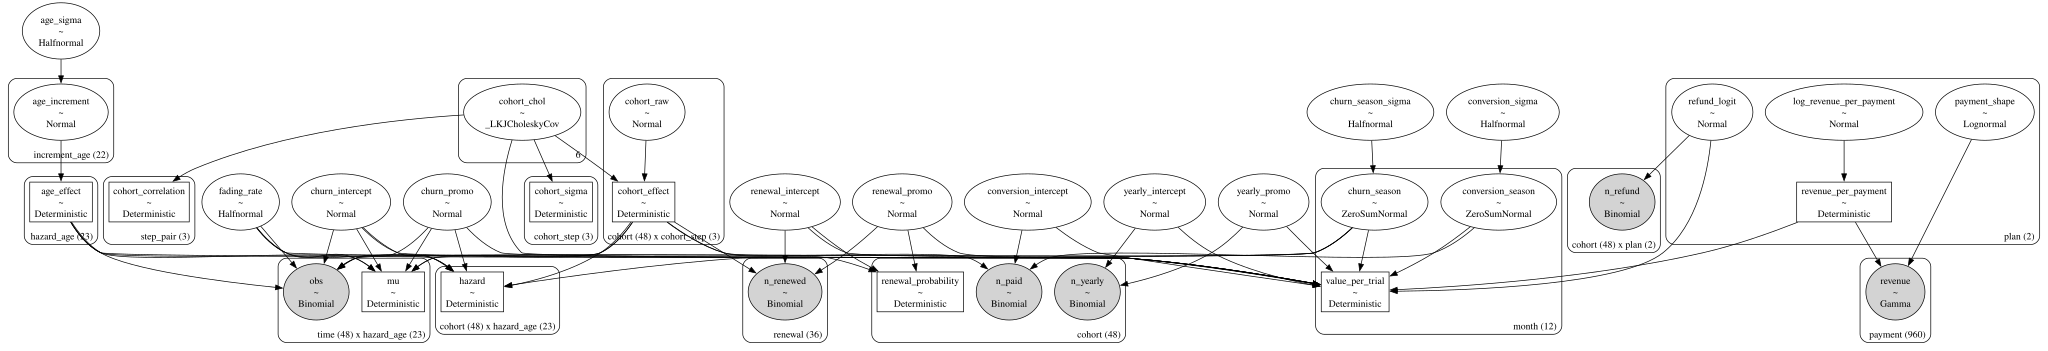

In [22]:
VALUE_PER_TRIAL: Final[str] = "value_per_trial"


def funnel_model(
    data: FunnelData, months: xr.DataArray, retained: xr.DataArray
) -> None:
    """Funnel model on the data of a freeze, with the forecast of the future months."""
    split = Horizon.from_data(months, retained)

    assert np.array_equal(retained.values, retained_table(data).values)

    pm.modelcontext(None).add_coords(
        {
            "cohort": data.cohort_labels,
            "month": MONTHS,
            "plan": list(Plan),
            "cohort_step": list(CohortStep),
            "step_pair": [f"{first}, {second}" for first, second in STEP_PAIRS],
            "increment_age": calendar.hazard_ages[1:],
        }
    )
    cohorts = cohort_covariates(data.cohorts["start_month"].to_numpy(), dim="cohort")
    effects = cohort_effects_prior()
    conversion = conversion_step(data, cohorts, effects.by_step[CohortStep.CONVERSION])
    plan_choice = plan_choice_step(data, cohorts)
    refund_logit = refund_step(data)
    renewal = renewal_step(data, cohorts, effects.by_step[CohortStep.RENEWAL])
    payment = revenue_step(data)
    hazard = hazard_prior()
    logit_hazard = hazard.logit(cohorts, effects.by_step[CohortStep.CHURN]).transpose(
        "cohort", "hazard_age"
    )
    pmd.Deterministic(HAZARD, pmd.math.sigmoid(logit_hazard))
    logit_retention = by_month(
        -logit_hazard.values, n_cohorts=len(data.cohorts), n_months=split.duration
    )
    future = None

    if split.future > 0:
        future = future_payments(
            data,
            logit_retention[split.t_obs :],
            renewal.logit(cohorts, effects.by_step[CohortStep.RENEWAL]),
            n_months=split.future,
        )
        future_revenue(payment, future)

    predict(split, retained_users(data, future), logit_retention)

    pmd.Deterministic(
        VALUE_PER_TRIAL,
        new_cohort_value(
            conversion,
            plan_choice,
            refund_logit,
            renewal,
            payment,
            expected_payments=hazard.expected_payments,
            chol=effects.chol,
        ),
    )


retained = retained_table(data)
model = build_model(
    partial(funnel_model, data), retained, null_covariates(retained["time"].values)
)

pm.model_to_graphviz(model)

The graph shows `cohort_effect` as a common parent of the conversion (`n_paid`), the churn (`obs`) and the renewal (`n_renewed`). The plan choice, the refunds and the revenue have their own parameters. The deterministics `hazard` and `renewal_probability` hold the quantities of every cohort, `mu` is the table of the logits of the retention that `predict` stores, and `value_per_trial` holds the value of a trial by start month.

Before we fit the model, let's check what its priors imply.

## Prior Predictive Checks

We draw from the priors and compare the draws with the data. We look at the one-month retention by age, pooled over the cohorts: the share of the users of the monthly plan who paid at age $a - 1$ and pay again at age $a$. It is the quantity that drives the value of a net start of the monthly plan.

We plot the draws as bands. Every band in this notebook is an **equal-tailed interval** (ETI): the $94\%$ ETI leaves $3\%$ of the draws on each side, and the $50\%$ ETI leaves $25\%$ on each side.

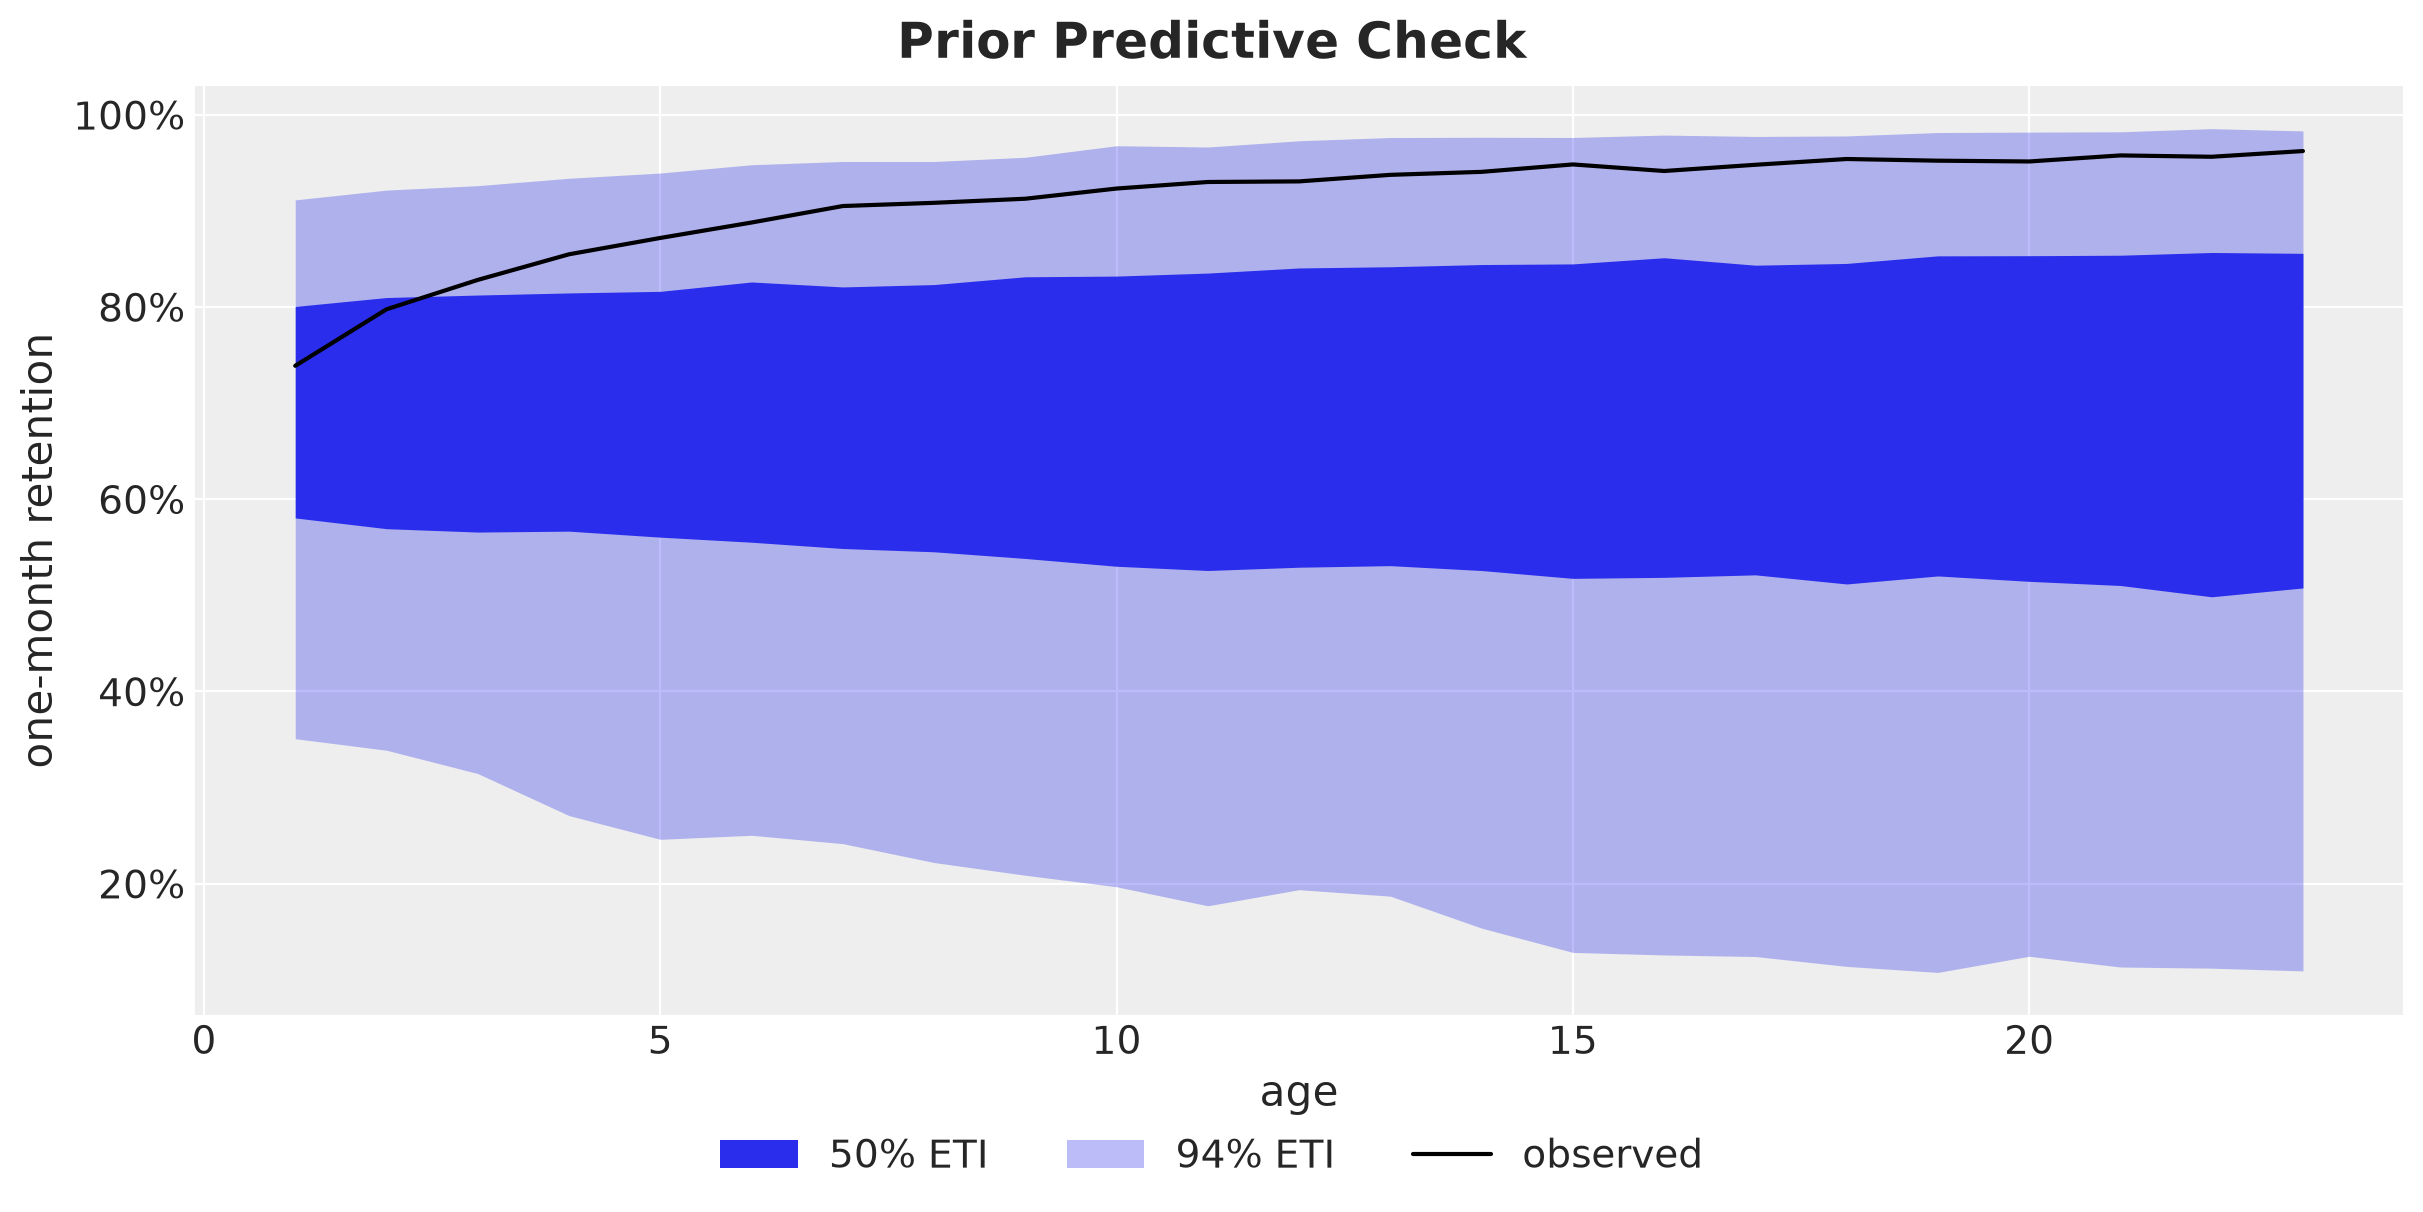

In [23]:
def pooled_retention(retained: xr.DataArray, data: FunnelData) -> xr.DataArray:
    """One-month retention by age: users who pay again over users who could churn."""
    return retained.sum("time") / at_risk_table(data).sum("time")


def label_bands(bands: xr.DataArray) -> None:
    """Give the two bands of one panel of a `plot_lm` figure their legend labels."""
    bands.sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
    bands.sel(prob=0.5).item().set_label("50% ETI")


def plot_retention_check(
    samples: xr.DataArray, observed: xr.DataArray
) -> az.PlotCollection:
    """Bands of the draws of the one-month retention with the observed one on top."""
    ages = samples["hazard_age"].values.astype(float)
    tree = az.from_dict(
        {
            "posterior_predictive": {"retention": samples.values},
            "observed_data": {"retention": observed.values},
            "constant_data": {"x": ages},
        },
        coords={"age": ages},
        dims={"retention": ["age"], "x": ["age"]},
    )
    pc = az.plot_lm(
        tree,
        x="x",
        y="retention",
        smooth=False,
        ci_prob=(0.5, CI_PROB),
        visuals={
            "ci_band": {"color": "C0"},
            "observed_scatter": False,
            "pe_line": False,
        },
        figure_kwargs={"figsize": (12, 6)},
    )
    ax = pc.viz["plot"]["x"].item()
    label_bands(pc.viz["ci_band"]["x"])
    ax.plot(ages, observed.values, color="black", label="observed")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(xlabel="age", ylabel="one-month retention", title="")
    pc.viz["figure"].item().legend(loc="outside lower center", ncol=3)
    return pc


observed_retention = pooled_retention(retained, data)

prior_idata = pm.sample_prior_predictive(
    draws=1_000, model=model, var_names=[OBS_VAR], random_seed=rng
)

pc = plot_retention_check(
    pooled_retention(prior_idata["prior_predictive"][OBS_VAR], data),
    observed_retention,
)
pc.viz["figure"].item().suptitle(
    "Prior Predictive Check", fontsize=18, fontweight="bold"
);

The observed retention rises with age and sits inside the $94\%$ band of the priors at every age. The bands do not rise with age, because the random walk of the age effect has no preferred direction.

They widen instead, and at the old ages the priors allow a retention close to $100\%$, that is, almost no churn. The level and the shape of the retention therefore have to come from the data.

Now we can fit the model.

## Model Fitting

We fit the model with `fit_mcmc` of PyMC-Forecast, which samples it with NUTS, the No-U-Turn sampler, in the implementation of [nutpie](https://github.com/pymc-devs/nutpie).

We ask for more chains and more draws than the defaults of the function. The *Backtest* section refits the model many times, and with these settings every fit clears the diagnostic bars below.

The function `fit` returns the draws together with three diagnostics over all the free parameters of the model:

- **Divergent transitions:** The number of steps at which the sampler could not follow the posterior. We want none.
- **$\hat{R}$:** A comparison of the chains with each other, which is close to $1$ when they agree. We want every value below $1.01$.
- **Effective sample size:** The number of independent draws that the chains are worth, for the center (bulk) and for the tails of each posterior. We want every value above $400$.

In [24]:
class SamplerCheck(NamedTuple):
    """Diagnostics of one fit over all the free parameters of the model."""

    divergences: int
    max_r_hat: float
    min_ess_bulk: float
    min_ess_tail: float

    @property
    def passed(self) -> bool:
        return (
            self.divergences == 0
            and self.max_r_hat < 1.01
            and min(self.min_ess_bulk, self.min_ess_tail) > 400
        )


class Fit(NamedTuple):
    """Posterior draws of the funnel model at one freeze and their diagnostics."""

    idata: xr.DataTree
    check: SamplerCheck


FREE_VARIABLES: Final[list[str]] = [rv.name for rv in model.free_RVs]


def fit(data: FunnelData, rng: np.random.Generator) -> Fit:
    """Fit the funnel model on the data of a freeze and compute its diagnostics."""
    idata = fit_mcmc(
        partial(funnel_model, data),
        retained_table(data),
        draws=2_000,
        chains=4,
        nuts_sampler="nutpie",
        random_seed=rng,
    ).idata
    diagnostics = az.summary(idata, var_names=FREE_VARIABLES, kind="diagnostics")
    check = SamplerCheck(
        divergences=int(idata["sample_stats"]["diverging"].sum()),
        max_r_hat=float(diagnostics["r_hat"].max()),
        min_ess_bulk=float(diagnostics["ess_bulk"].min()),
        min_ess_tail=float(diagnostics["ess_tail"].min()),
    )
    return Fit(idata=idata, check=check)


main_fit = fit(data, rng)
idata = main_fit.idata

assert main_fit.check.passed

The assertion confirms that the fit clears the three bars for every free parameter.

### Model Diagnostics

Let's look at the diagnostics of the parameters of the churn and of the cohort effects, which are the hardest ones to sample.

In [25]:
CHURN_PARAMS: Final[list[str]] = [
    "churn_intercept",
    "age_sigma",
    "churn_season_sigma",
    "churn_promo",
    "fading_rate",
]

az.summary(
    idata,
    var_names=[*CHURN_PARAMS, COHORT_SIGMA_SITE, COHORT_CORRELATION],
    kind="diagnostics",
    round_to=2,
)[["ess_bulk", "ess_tail", "r_hat"]].astype({"ess_bulk": int, "ess_tail": int})

,ess_bulk,ess_tail,r_hat
churn_intercept,2179,3391,1.0
age_sigma,9360,6019,1.0
churn_season_sigma,9922,5755,1.0
churn_promo,2579,3884,1.0
fading_rate,9040,5963,1.0
cohort_sigma[conversion],1731,2733,1.0
cohort_sigma[churn],3137,3900,1.0
cohort_sigma[renewal],3603,4986,1.0
"cohort_correlation[conversion, churn]",2210,3231,1.0
"cohort_correlation[conversion, renewal]",3067,4974,1.0


Every $\hat{R}$ in the table rounds to $1.00$, and the effective sample sizes are in the thousands. Next, we look at the posterior densities and the traces of the five scalar parameters of the churn, one line per chain.

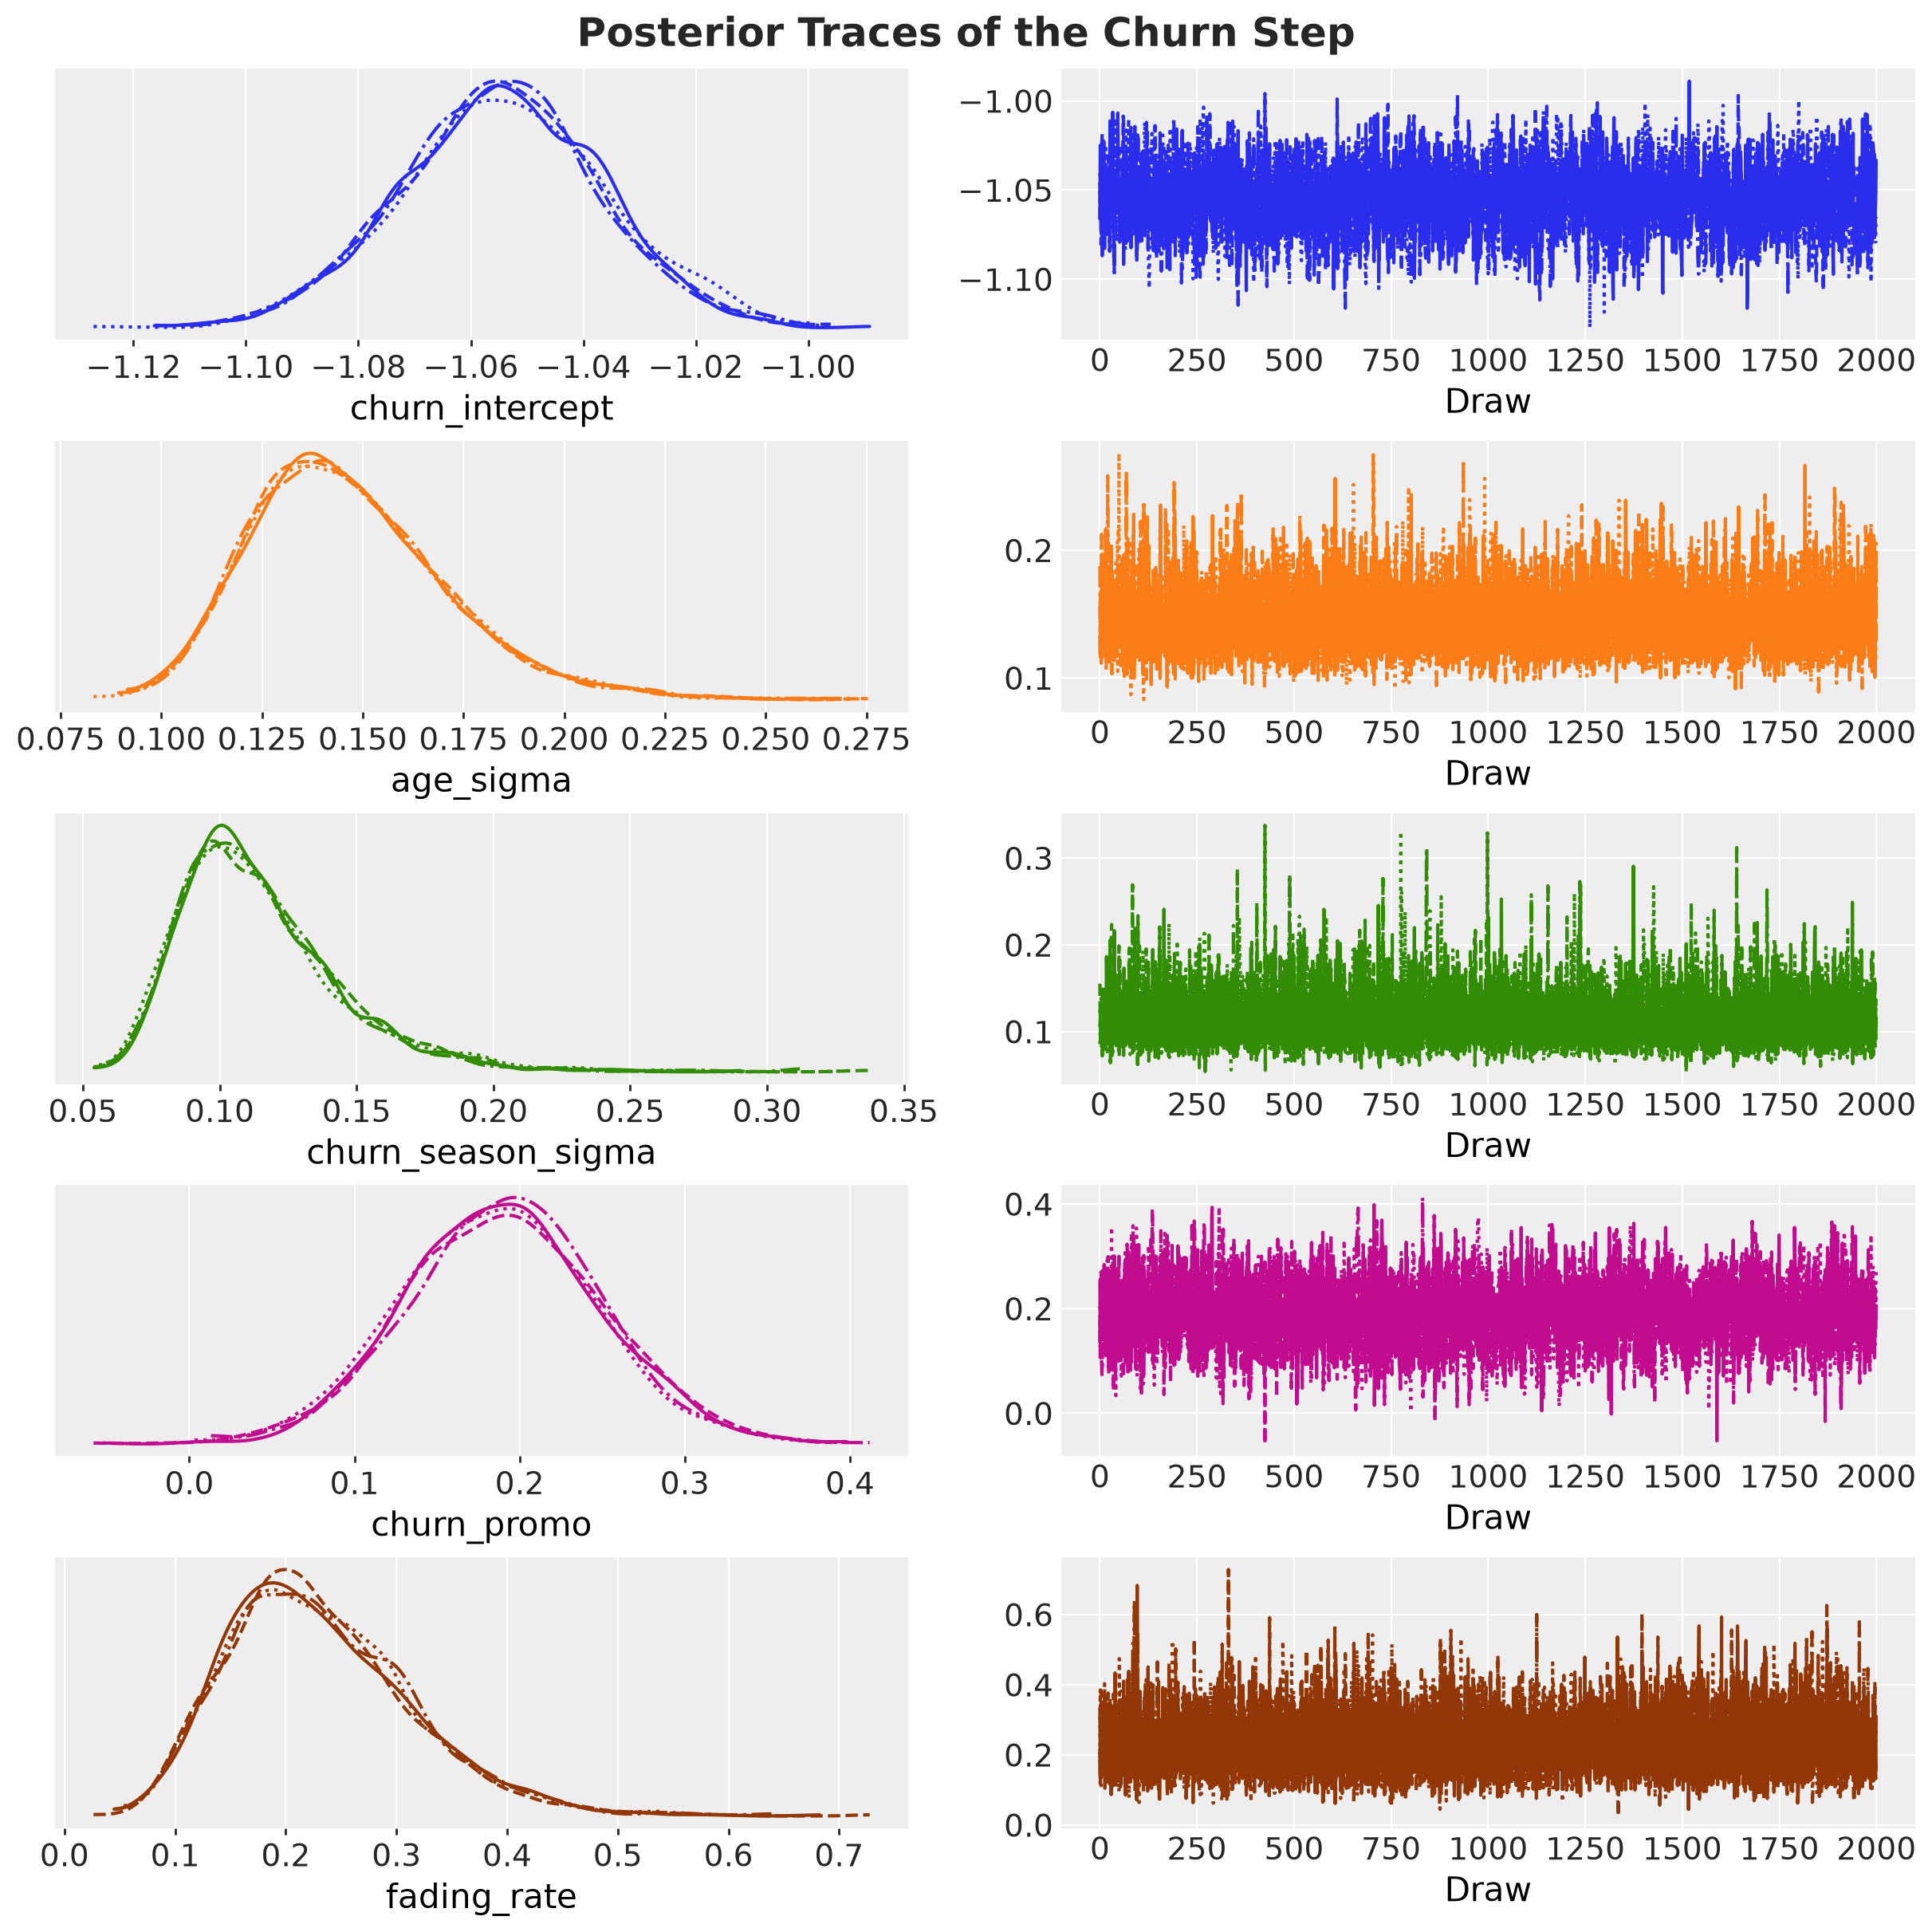

In [26]:
pc = az.plot_trace_dist(
    idata, var_names=CHURN_PARAMS, figure_kwargs={"figsize": (12, 12)}
)

for name in CHURN_PARAMS:
    pc.viz["plot"][name].sel(column="trace").item().set_ylabel("")

pc.viz["figure"].item().suptitle(
    "Posterior Traces of the Churn Step", fontsize=18, fontweight="bold"
);

The four chains agree on every density, and the traces show no trend and no stuck chain.

### Parameter Recovery

Next, we check that the posterior recovers the parameters that we fixed in the generator. We start with the parameters that have the same meaning in both models. The vertical lines are the true values.

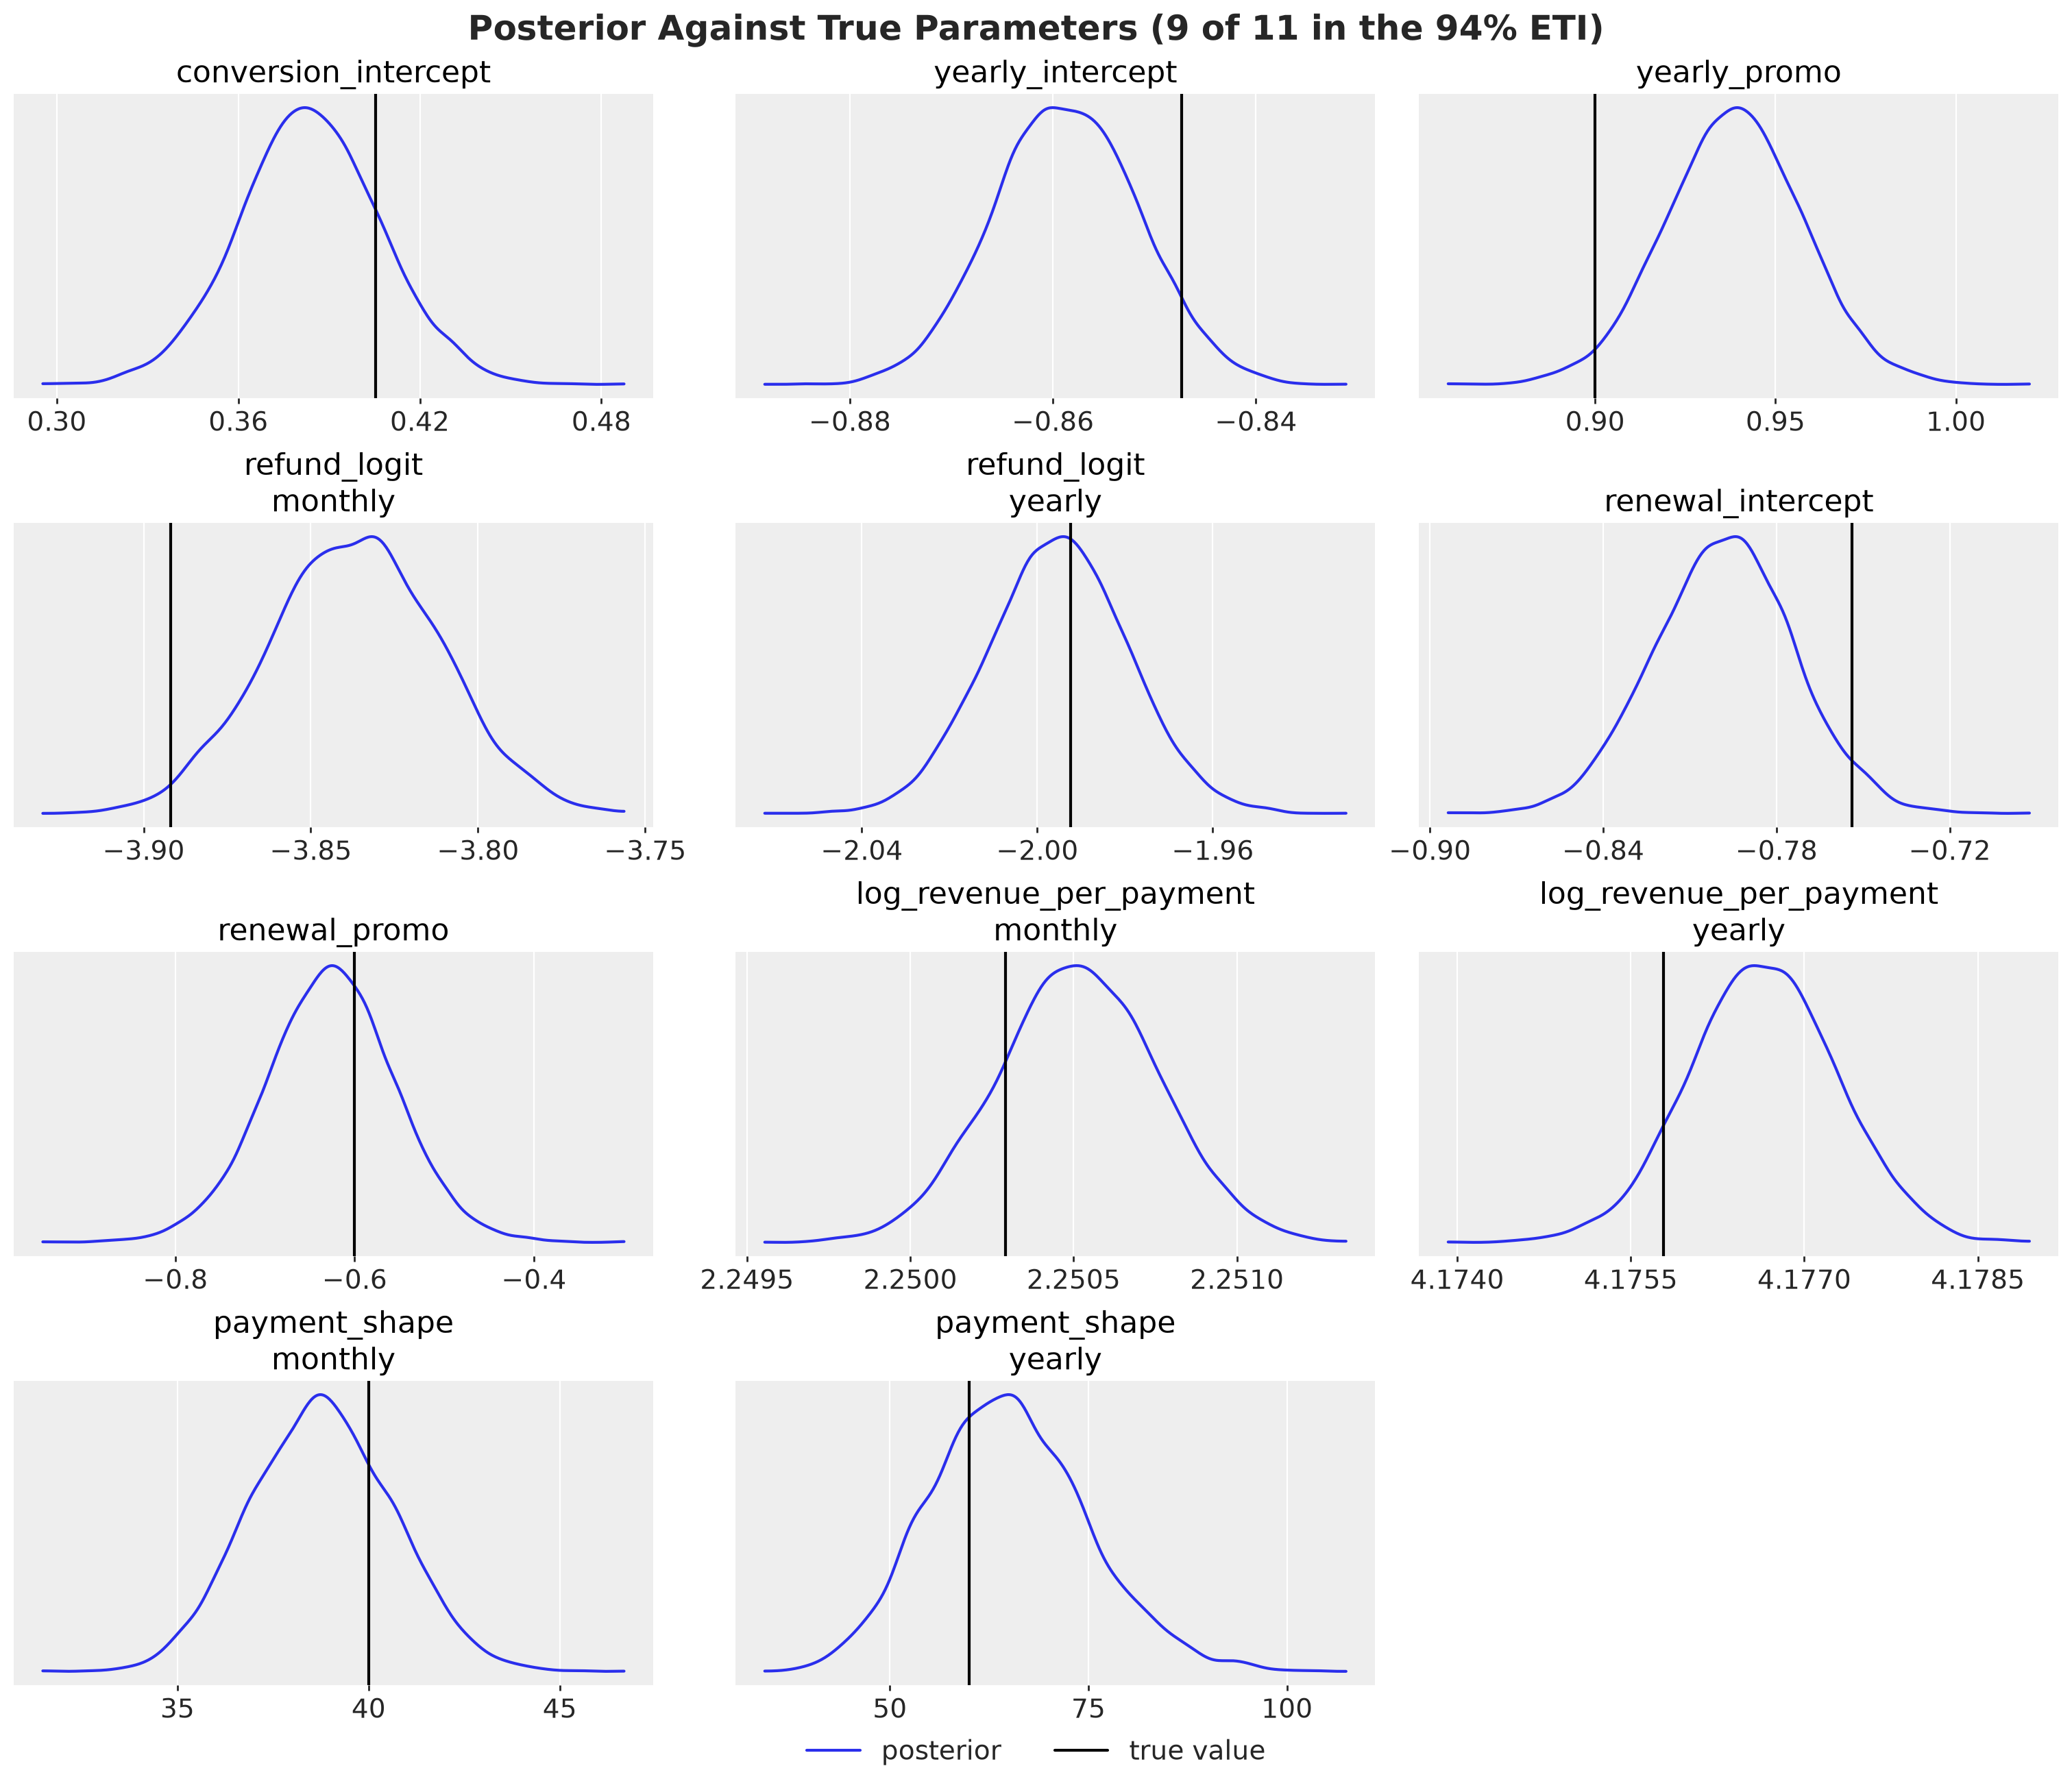

In [27]:
EXACT_PARAMS: Final[list[str]] = [
    "conversion_intercept",
    "yearly_intercept",
    "yearly_promo",
    "refund_logit",
    "renewal_intercept",
    "renewal_promo",
    "log_revenue_per_payment",
    "payment_shape",
]

true_values = xr.Dataset(
    {
        name: ("plan", TRUE_PARAMS[name])
        if np.ndim(TRUE_PARAMS[name])
        else float(TRUE_PARAMS[name])
        for name in EXACT_PARAMS
    },
    coords={"plan": list(Plan)},
)


def is_covered(draws: xr.DataArray, truth: xr.DataArray | np.ndarray) -> xr.DataArray:
    """Whether the central interval of the draws contains the true value."""
    interval = az.eti(draws, prob=CI_PROB)
    return (interval.sel(ci_bound="lower") <= truth) & (
        truth <= interval.sel(ci_bound="upper")
    )


exact_covered = np.concatenate(
    [
        np.ravel(is_covered(idata["posterior"][name], true_values[name]))
        for name in EXACT_PARAMS
    ]
)

pc = az.plot_dist(
    idata,
    var_names=EXACT_PARAMS,
    kind="kde",
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    col_wrap=3,
    figure_kwargs={"figsize": (15, 13)},
)
az.add_lines(
    pc,
    values=true_values,
    aes_by_visuals={"ref_line": []},
    visuals={"ref_line": {"color": "black", "linestyle": "-", "zorder": 3}},
)

for name in EXACT_PARAMS:
    for ax in pc.viz["plot"][name].values.flat:
        ax.xaxis.set_major_locator(MaxNLocator(4))

pc.viz["dist"][EXACT_PARAMS[0]].item().set_label("posterior")
pc.viz["ref_line"][EXACT_PARAMS[0]].item().set_label("true value")
pc.viz["figure"].item().legend(loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    f"Posterior Against True Parameters ({exact_covered.sum()} of "
    f"{exact_covered.size} in the {CI_PROB:.0%} ETI)",
    fontsize=18,
    fontweight="bold",
);

The true value lies inside the $94\%$ ETI of $9$ of the $11$ parameters. For `yearly_promo` and for the refund logit of the monthly plan it lies in a tail of the posterior. One or two misses among $11$ intervals at $94\%$ are consistent with the randomness of a single simulation.

Next, let's look at the standard deviations and the correlations of the cohort effects. Each of them has a reference value from the generator:

- **Conversion and renewal:** These steps have the same form in both models, so the reference value is the true standard deviation $0.15$.
- **Churn:** The churn effect of the model acts on the hazard of the cohort. Recall from the *Fading of a Persistent Shift* figure that at age $1$ the gap of the cohort is about $0.8$ times the shift of each user. The reference value is $0.15$ times that ratio.
- **Correlations:** The reference values are the products $w_s w_{s'}$ of the loadings.

In the forest plot below, the thin line of each row is the $94\%$ ETI and the thick line is the $50\%$ ETI.

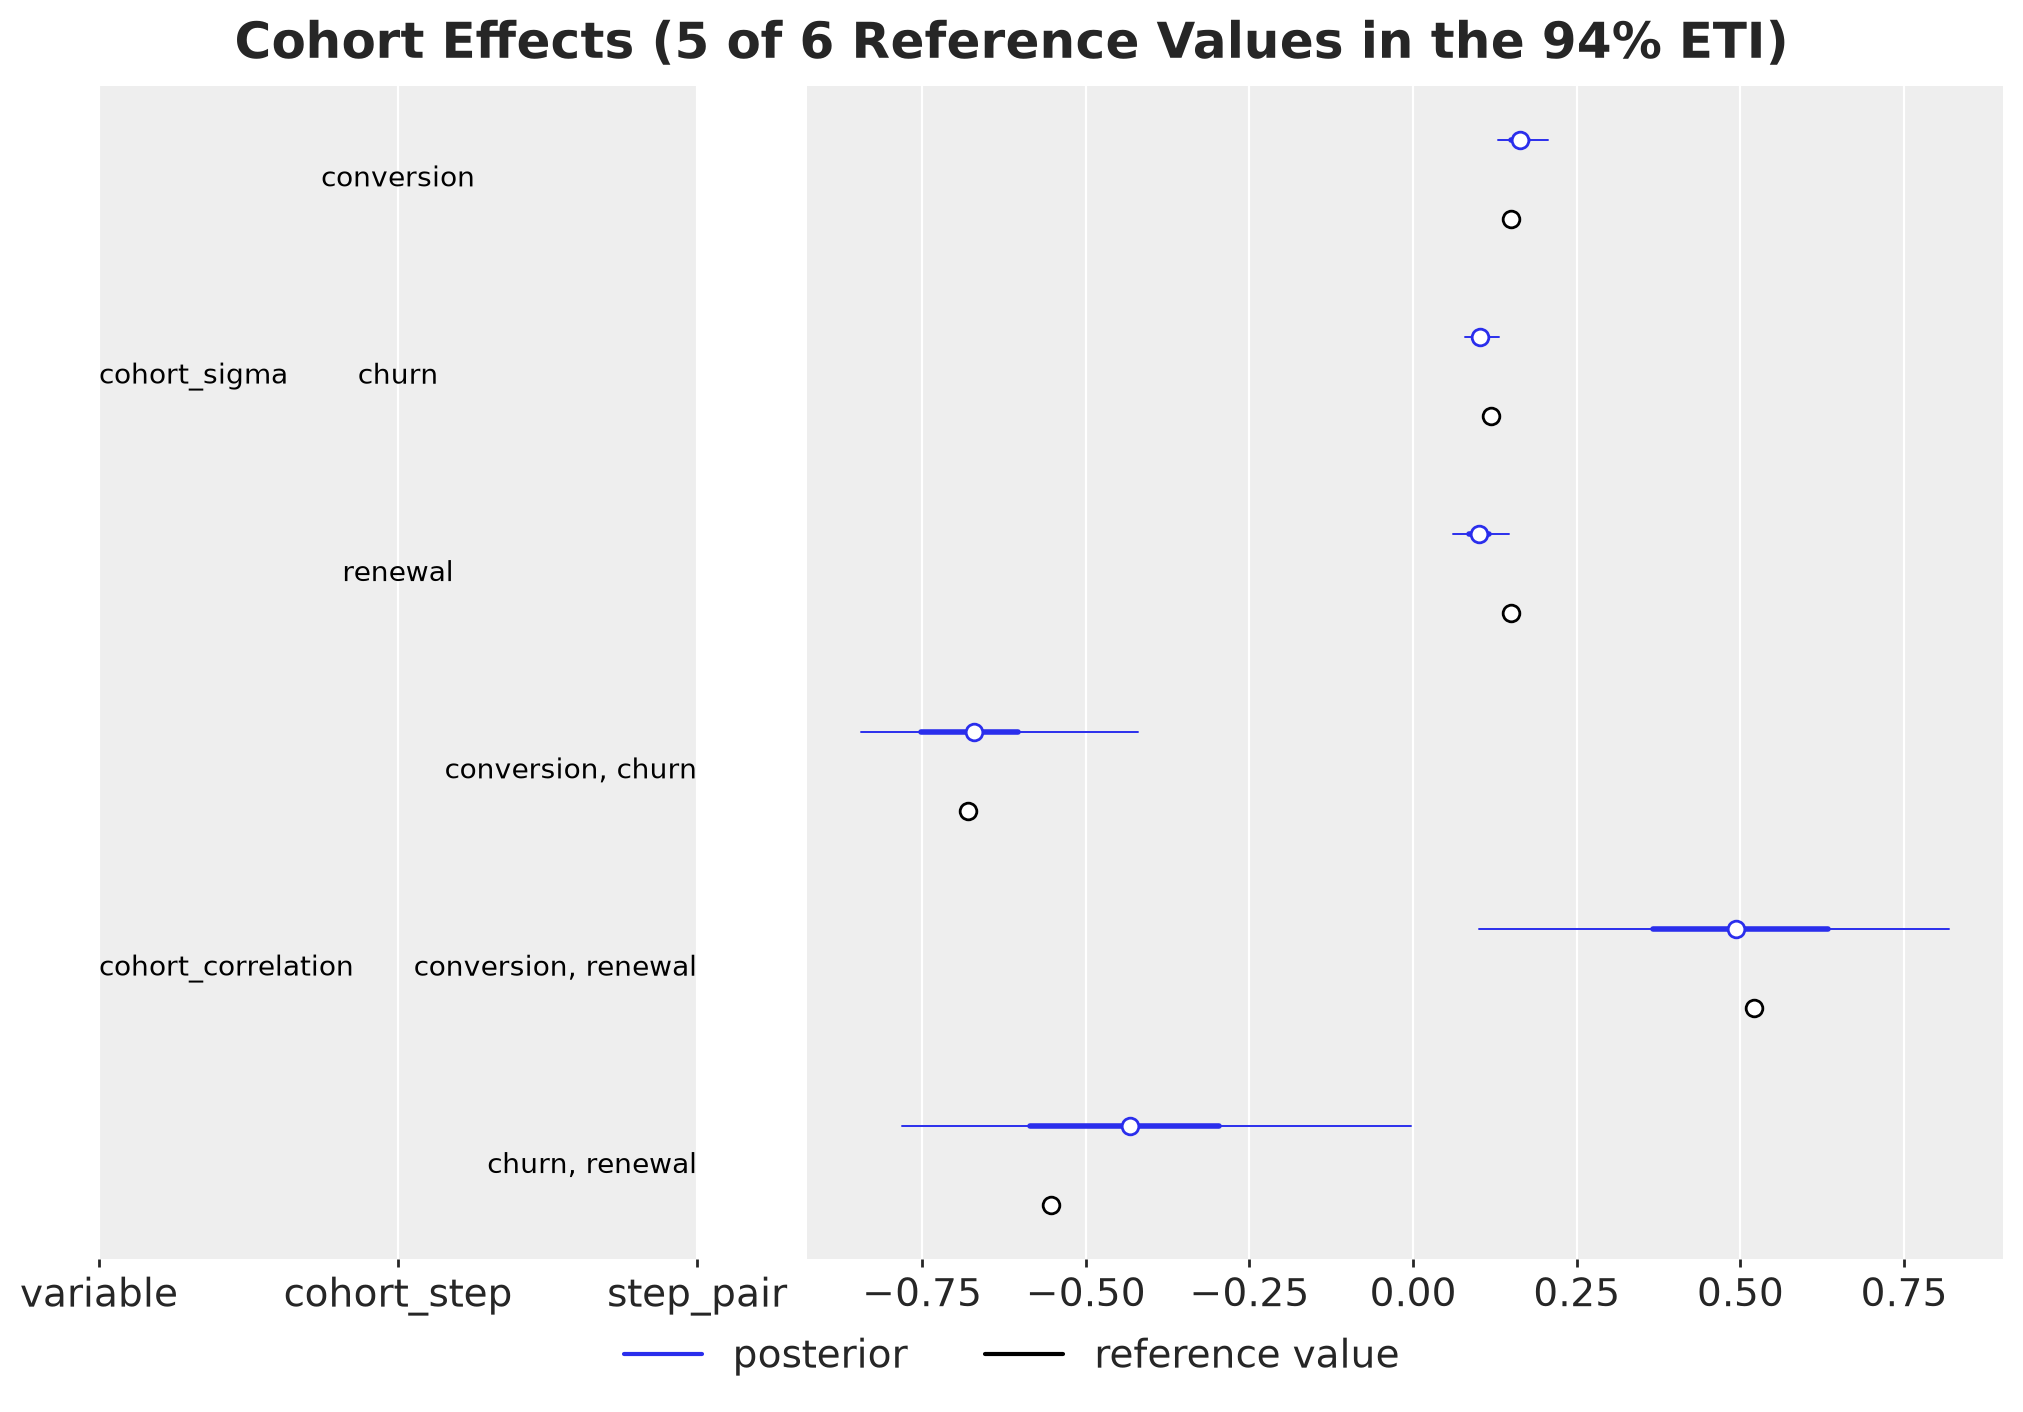

In [28]:
def truth_tree(values: dict[str, xr.DataArray], posterior: xr.Dataset) -> xr.DataTree:
    """Point masses at fixed values, with the chains and draws of a posterior."""
    sample_sizes = {"chain": posterior.sizes["chain"], "draw": posterior.sizes["draw"]}
    return xr.DataTree.from_dict(
        {
            "posterior": xr.Dataset(
                {
                    name: value.expand_dims(sample_sizes)
                    for name, value in values.items()
                }
            )
        }
    )


sigma_reference = xr.DataArray(
    list(COHORT_SIGMA.values()),
    dims="cohort_step",
    coords={"cohort_step": list(CohortStep)},
)
sigma_reference.loc[{"cohort_step": CohortStep.CHURN}] *= persistent_gap[0] / SHIFT
correlation_reference = xr.DataArray(
    [true_correlation(first, second) for first, second in STEP_PAIRS],
    dims="step_pair",
    coords={"step_pair": idata["posterior"]["step_pair"].values},
)
cohort_reference = {
    COHORT_SIGMA_SITE: sigma_reference,
    COHORT_CORRELATION: correlation_reference,
}
reference_covered = np.concatenate(
    [
        np.ravel(is_covered(idata["posterior"][name], reference))
        for name, reference in cohort_reference.items()
    ]
)

pc = az.plot_forest(
    {
        "posterior": idata,
        "reference value": truth_tree(cohort_reference, posterior=idata["posterior"]),
    },
    var_names=[COHORT_SIGMA_SITE, COHORT_CORRELATION],
    combined=True,
    color=["C0", "black"],
    figure_kwargs={"figsize": (10, 7)},
)
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    f"Cohort Effects ({reference_covered.sum()} of {reference_covered.size} "
    f"Reference Values in the {CI_PROB:.0%} ETI)",
    fontsize=18,
    fontweight="bold",
);

Let's go through the parameters:

- **Standard deviations:** The reference values of the conversion and of the churn lie inside the $94\%$ ETI. The one of the renewal lies just above its interval, so the model finds a smaller spread of the renewal effects than the generator used.
- **Correlations:** The posterior has the signs of the three true correlations: a cohort that converts more churns less and renews more. The correlation between the conversion and the churn is clearly different from zero. The two correlations with the renewal have wide intervals, and the one between the churn and the renewal reaches zero.

The renewal is the hardest step to learn, because only the cohorts that are older than a year have renewed.

The parameters of the churn have no exact counterpart in the generator, because they act on the hazard of a cohort and the ones of the generator on the hazard of each user. Recall that the generator recorded the true hazard of every cohort. We compare the posterior `hazard` with it, for four cohorts:

- `2022-12`, a complete cohort.
- `2023-11`, a promotion cohort that is $13$ months old at the freeze.
- `2024-06`, a cohort that is $6$ months old at the freeze.
- `2024-12`, the youngest cohort, which has not paid a second time yet.

The dashed line marks the age of each cohort at the freeze, so the hazards to its right are forecasts. The title gives the share of the true hazards of the four panels that lie inside the $94\%$ ETI.

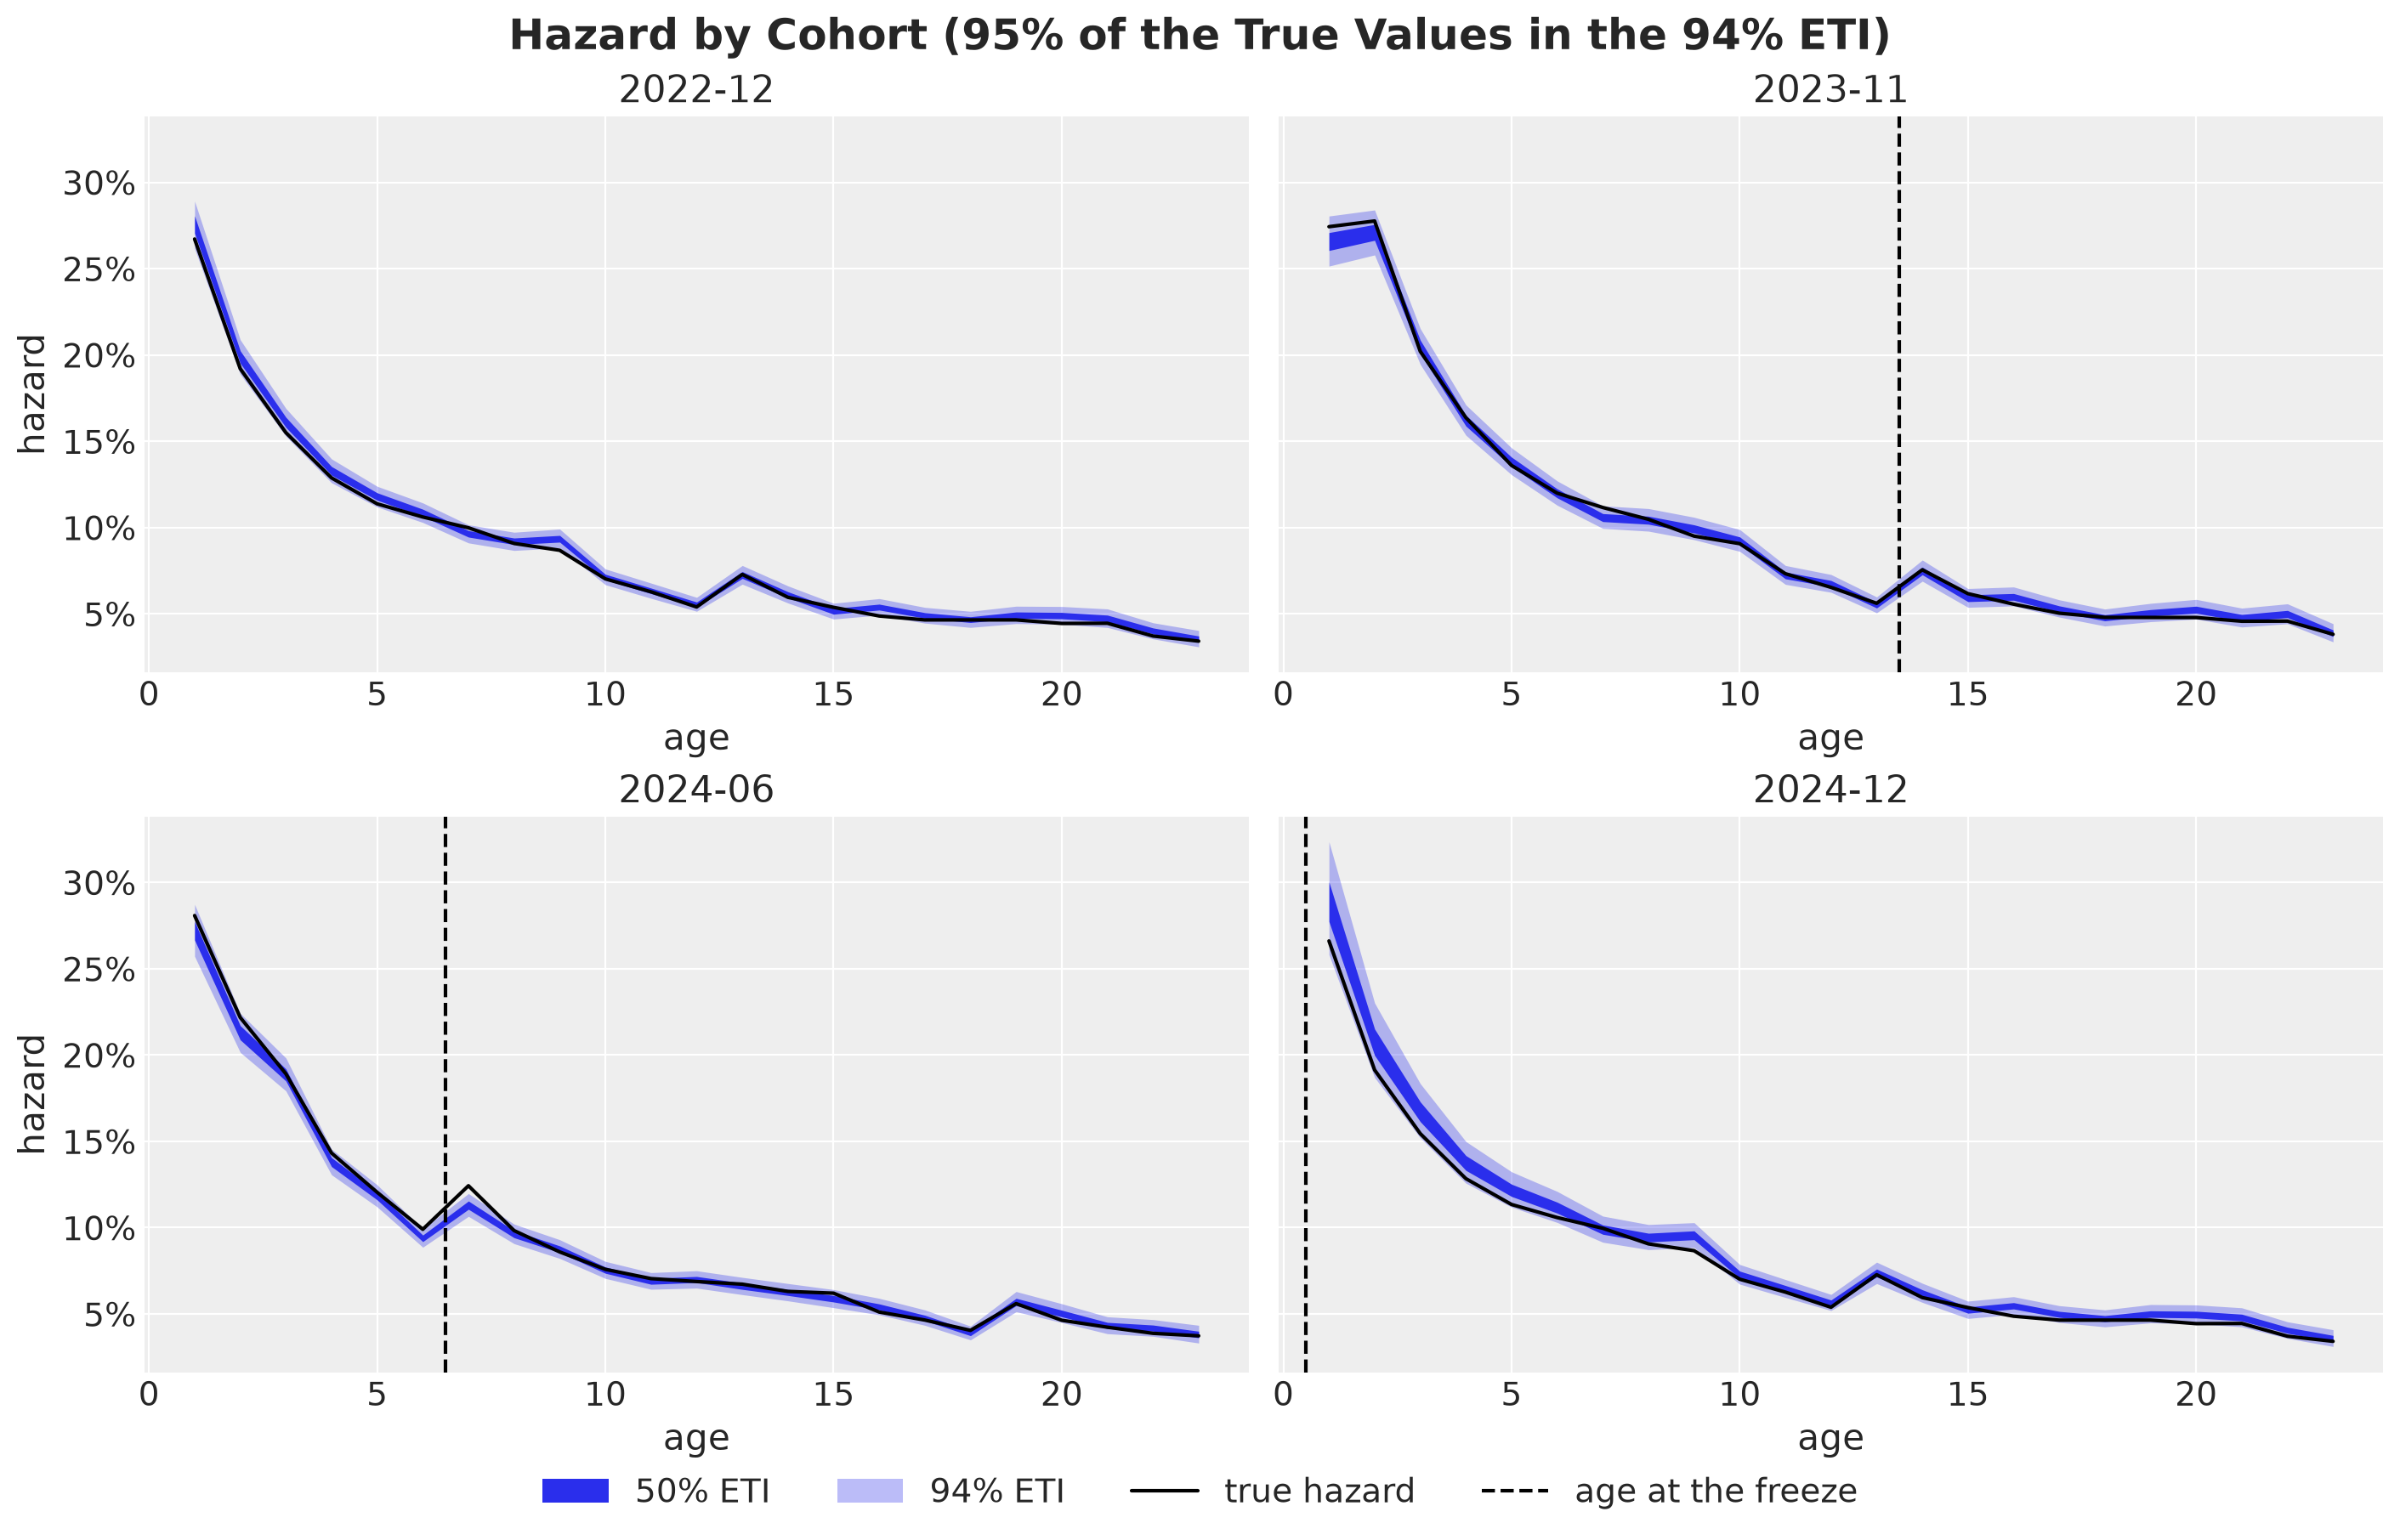

In [29]:
def legend_below(fig: plt.Figure, axes: list[plt.Axes], ncol: int) -> None:
    """Legend below the figure with one entry for each label of the panels."""
    entries = {}

    for ax in axes:
        handles, labels = ax.get_legend_handles_labels()
        entries |= dict(zip(labels, handles, strict=True))

    fig.legend(entries.values(), entries.keys(), loc="outside lower center", ncol=ncol)


HAZARD_COHORTS: Final[list[str]] = ["2022-12", "2023-11", "2024-06", "2024-12"]

hazard_draws = (
    idata["posterior"][HAZARD]
    .sel(cohort=HAZARD_COHORTS)
    .transpose("chain", "draw", "cohort", "hazard_age")
)
true_hazard = (
    simulation.truth["true_hazard"]
    .sel(cohort=HAZARD_COHORTS)
    .transpose("cohort", "hazard_age")
)
hazard_inside = is_covered(hazard_draws, true_hazard)
hazard_tree = az.from_dict(
    {
        "posterior_predictive": {"hazard": hazard_draws.values},
        "observed_data": {"hazard": true_hazard.values},
        "constant_data": {
            "x": np.broadcast_to(
                calendar.hazard_ages.astype(float), true_hazard.shape
            ).copy()
        },
    },
    coords={"cohort": HAZARD_COHORTS, "hazard_age": calendar.hazard_ages},
    dims={"hazard": ["cohort", "hazard_age"], "x": ["cohort", "hazard_age"]},
)

pc = az.plot_lm(
    hazard_tree,
    x="x",
    y="hazard",
    plot_dim="hazard_age",
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    visuals={"ci_band": {"color": "C0"}, "observed_scatter": False, "pe_line": False},
    col_wrap=2,
    figure_kwargs={"figsize": (14, 9), "sharey": True},
)
hazard_axes = [pc.get_target("x", {"cohort": label}) for label in HAZARD_COHORTS]

for label, ax in zip(HAZARD_COHORTS, hazard_axes, strict=True):
    label_bands(pc.viz["ci_band"]["x"].sel(cohort=label))
    current_age = FREEZE - calendar.cohort_labels.index(label)
    ax.plot(
        calendar.hazard_ages,
        true_hazard.sel(cohort=label).values,
        color="black",
        label="true hazard",
    )

    if current_age < calendar.horizon - 1:
        ax.axvline(
            current_age + 0.5, color="black", linestyle="--", label="age at the freeze"
        )

    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(xlabel="age", title=label)
    ax.set_ylabel("hazard" if ax.get_subplotspec().is_first_col() else "")

legend_below(pc.viz["figure"].item(), hazard_axes, ncol=4)
pc.viz["figure"].item().suptitle(
    f"Hazard by Cohort ({hazard_inside.mean().item():.0%} of the True Values in the "
    f"{CI_PROB:.0%} ETI)",
    fontsize=18,
    fontweight="bold",
);

The true hazard lies inside the $94\%$ ETI at almost every age of the four cohorts, including the ages after the freeze, which is good! Each cohort shows a different stage:

- For the complete cohort `2022-12` the bands are narrow and follow the bumps of the season.
- For the promotion cohort `2023-11` the forecast after the freeze continues the observed hazard.
- For the cohort `2024-06` the forecast underestimates the bump of the first month after the freeze and follows the true hazard afterward.
- The youngest cohort `2024-12` has not paid a second time. Its hazard comes from its calendar months and from its conversion, and its bands are the widest. The true hazard lies at the lower edge of the band in the first months, so the model expects more churn than this cohort has.

Finally, let's do the same for the renewal. The cohorts that are younger than $12$ months at the freeze have not renewed yet, so their renewal probability is a forecast from their conversion and their churn. The title counts how many of these forecasts cover the true renewal probability.

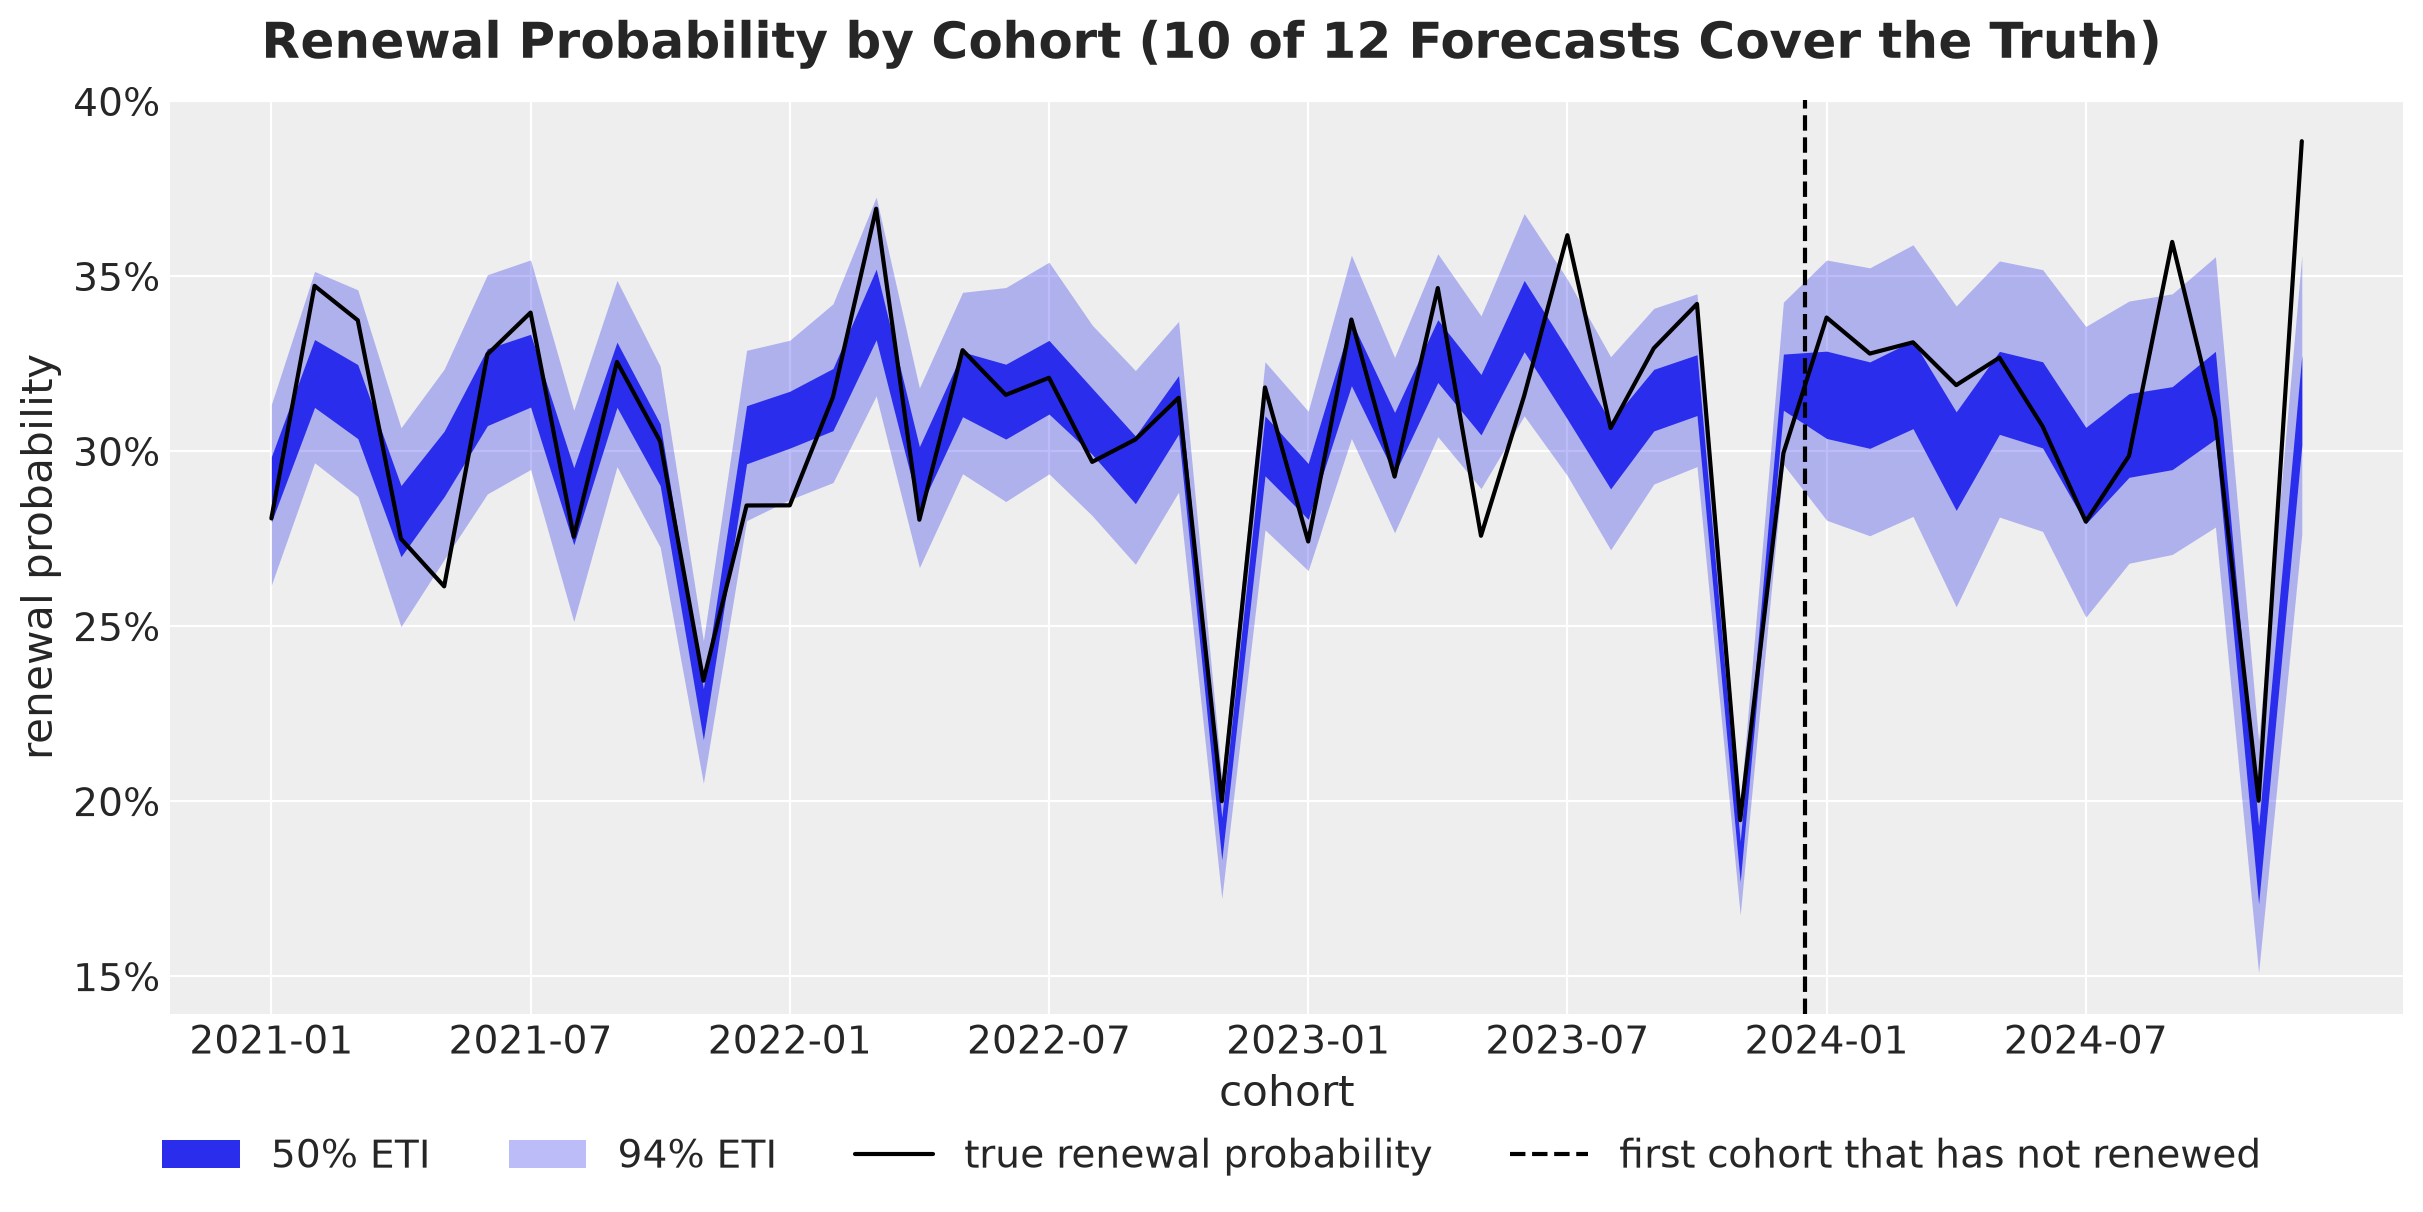

In [30]:
cohort_position = cohort_dates.astype(float)
renewal_draws = idata["posterior"][RENEWAL_PROBABILITY].transpose(
    "chain", "draw", "cohort"
)
true_renewal = simulation.truth["true_renewal_probability"].sel(
    cohort=data.cohort_labels
)
renewal_inside = is_covered(renewal_draws, true_renewal)
not_renewed = data.current_age < calendar.renewal_age
renewal_tree = az.from_dict(
    {
        "posterior_predictive": {"renewal": renewal_draws.values},
        "observed_data": {"renewal": true_renewal.values},
        "constant_data": {"x": cohort_position},
    },
    coords={"cohort": data.cohort_labels},
    dims={"renewal": ["cohort"], "x": ["cohort"]},
)

pc = az.plot_lm(
    renewal_tree,
    x="x",
    y="renewal",
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    visuals={"ci_band": {"color": "C0"}, "observed_scatter": False, "pe_line": False},
    figure_kwargs={"figsize": (12, 6)},
)
ax = pc.viz["plot"]["x"].item()
label_bands(pc.viz["ci_band"]["x"])
ax.plot(
    cohort_position,
    true_renewal.values,
    color="black",
    label="true renewal probability",
)
ax.axvline(
    cohort_position[not_renewed][0] - 0.5,
    color="black",
    linestyle="--",
    label="first cohort that has not renewed",
)
ax.set_xticks(cohort_position[::6], data.cohort_labels[::6])
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="cohort", ylabel="renewal probability", title="")
pc.viz["figure"].item().legend(loc="outside lower center", ncol=4)
pc.viz["figure"].item().suptitle(
    f"Renewal Probability by Cohort ({renewal_inside.values[not_renewed].sum()} of "
    f"{not_renewed.sum()} Forecasts Cover the Truth)",
    fontsize=18,
    fontweight="bold",
);

To the left of the dashed line the cohorts have renewed. The bands follow the large moves of the true renewal probability, such as the dips of the November cohorts, which renew less because of the promotion. Between these moves the bands are smoother than the truth, which is consistent with partial pooling, since each cohort has only a few hundred users of the yearly plan.

To the right of the dashed line no renewal is observed, and the bands are wider. They are forecasts from the conversion and the churn of each cohort, and they cover the true renewal probability for $10$ of the $12$ cohorts. The youngest cohort `2024-12` is one of the two misses, with a true renewal probability above its band.

Now that we have checked the parameters, let's look at the fit to the data.

## Posterior Predictive Checks

Recall that the one-month retention at age $a$ is the share of the users of the monthly plan who paid at age $a - 1$ and pay again at age $a$. We plotted it under the priors in the *Prior Predictive Checks* section. We now draw the observed table again from the posterior with `predict_in_sample` and plot the same quantity.

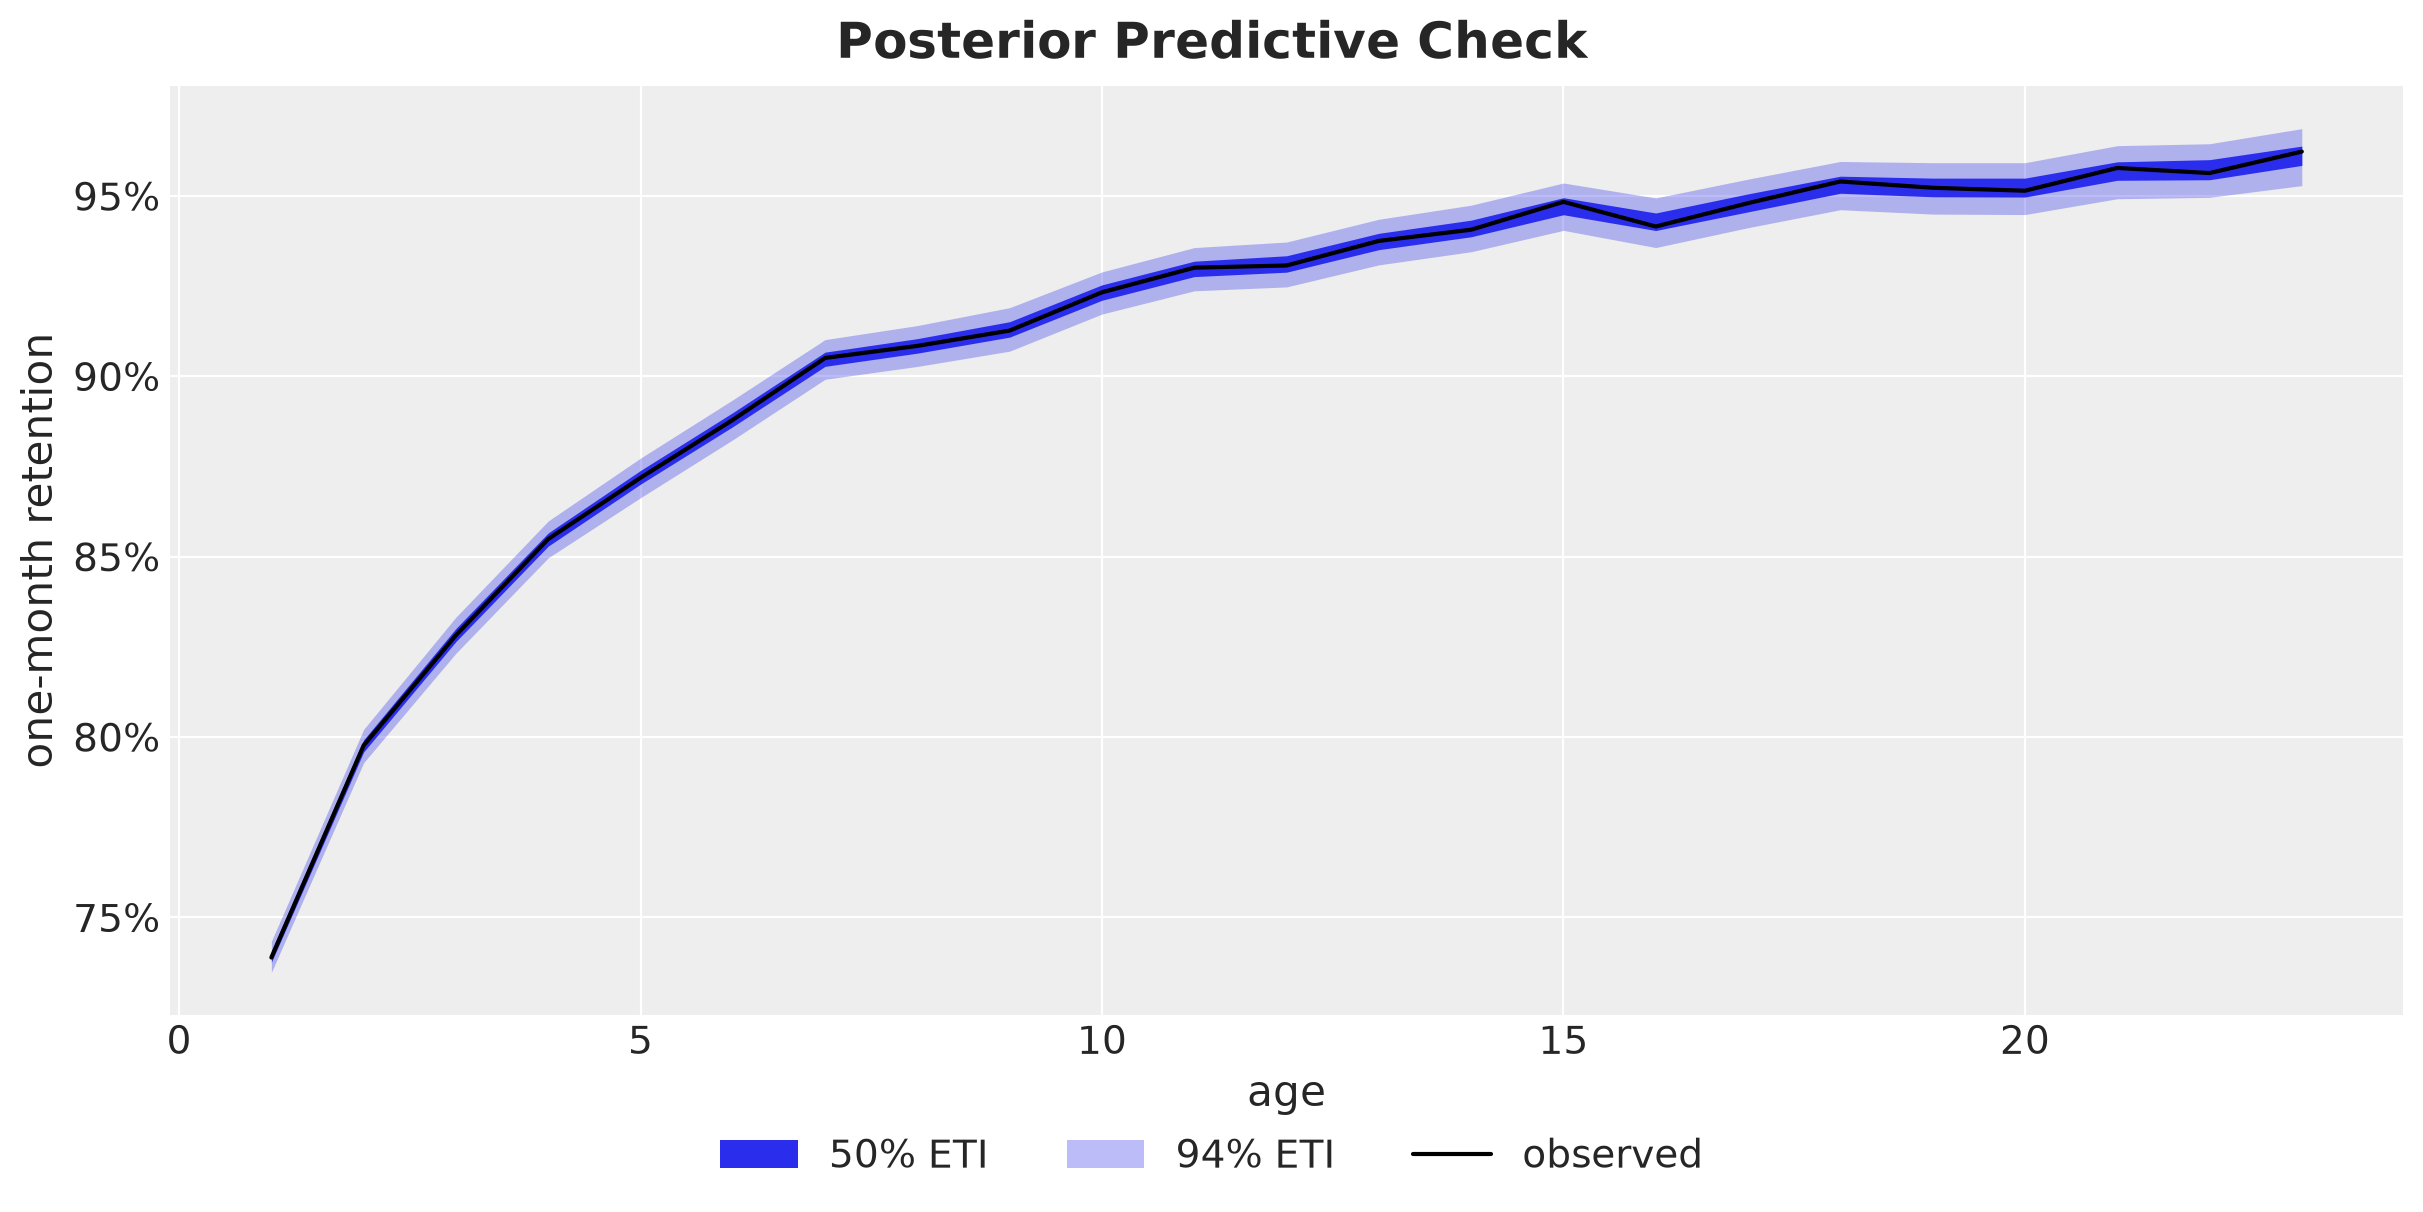

In [31]:
retained_draws = predict_in_sample(
    partial(funnel_model, data), idata, retained, random_seed=rng
)["posterior_predictive"][OBS_VAR]

pc = plot_retention_check(pooled_retention(retained_draws, data), observed_retention)
pc.viz["figure"].item().suptitle(
    "Posterior Predictive Check", fontsize=18, fontweight="bold"
);

The bands are narrow and follow the observed retention at every age. This is a weak check, because the age effect has one free value per age and can fit the pooled retention of any data set.

The pooled retention also hides the differences between cohorts and calendar months, and we look at each cohort and age as well.

We compute the **standardized residual** of the users who pay again: the observed count minus its posterior predictive mean, divided by its posterior predictive standard deviation. The title of the figure gives the share of the residuals that are larger than $2$ in absolute value.

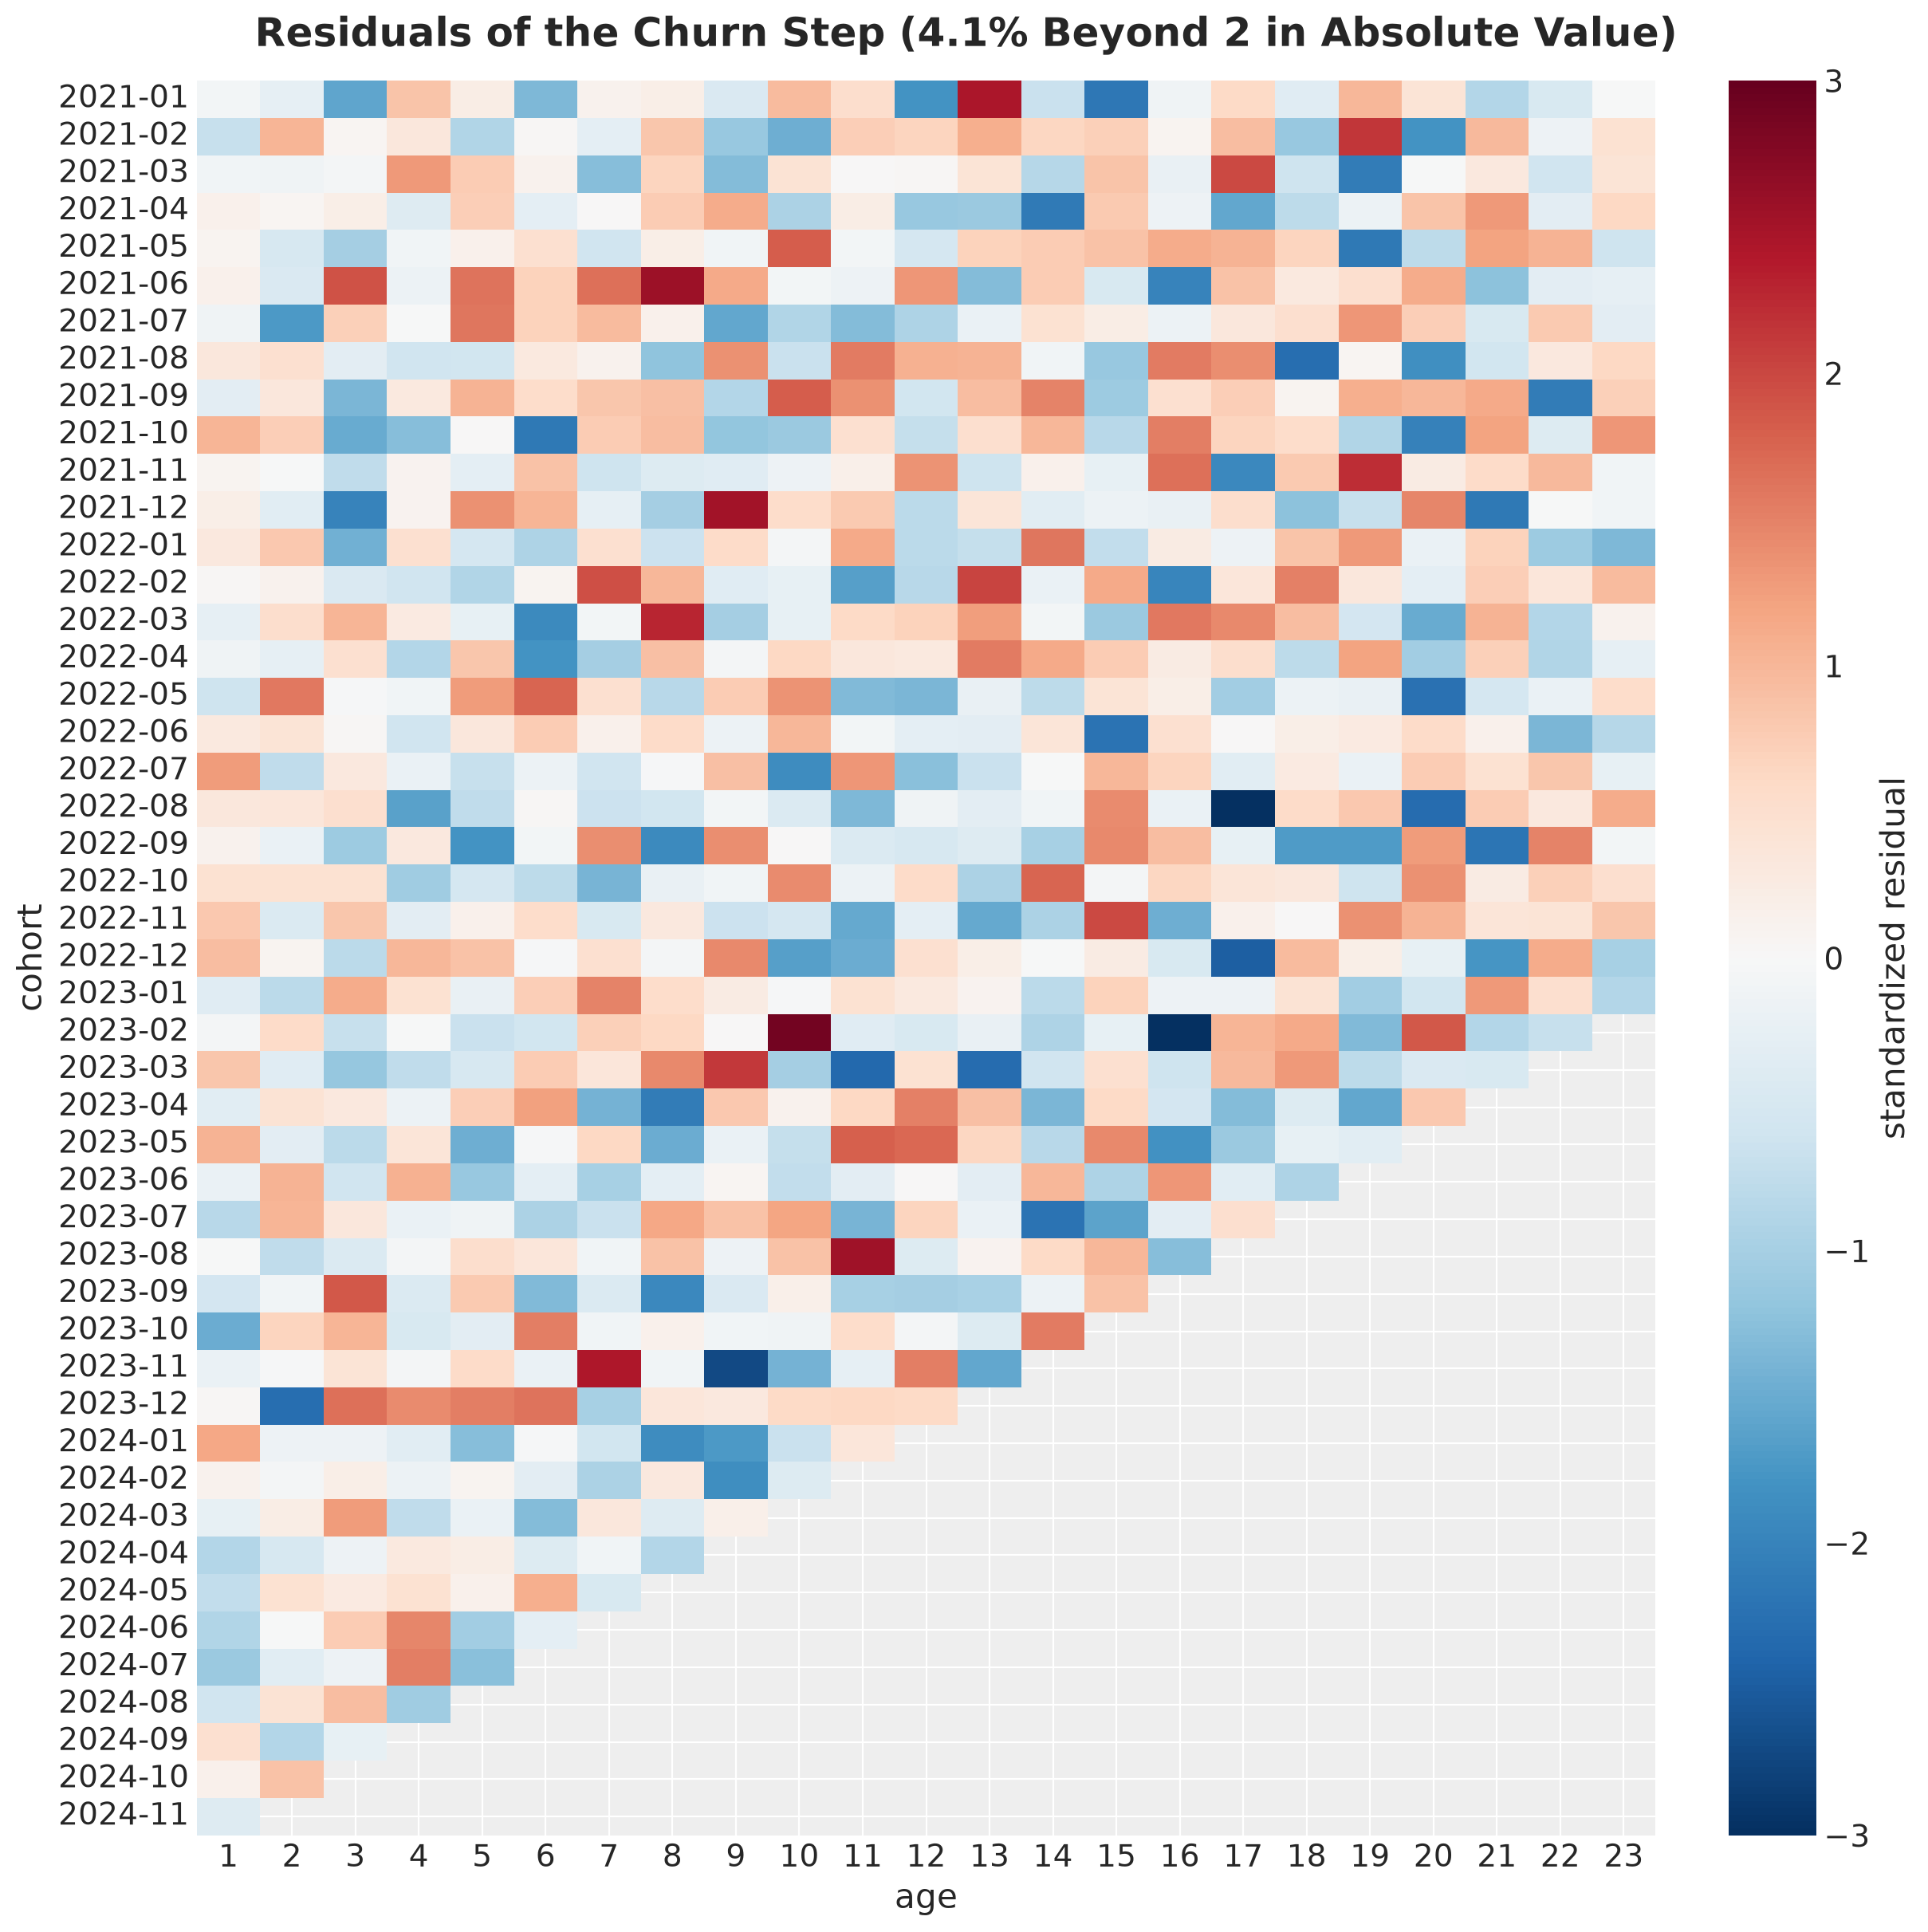

In [32]:
transition_draws = retained_draws.isel(
    time=xr.DataArray(data.transitions["period"].to_numpy(), dims="transition"),
    hazard_age=xr.DataArray(data.transitions["age"].to_numpy() - 1, dims="transition"),
)
residuals = (
    data.transitions.with_columns(
        pl.Series(
            "residual",
            (
                data.transitions["n_payments"].to_numpy()
                - transition_draws.mean(("chain", "draw")).values
            )
            / transition_draws.std(("chain", "draw")).values,
        )
    )
    .pivot(on="age", index="cohort", values="residual")
    .sort("cohort")
)
residual_values = residuals.drop("cohort").to_numpy()
observed_residuals = residual_values[~np.isnan(residual_values)]
large_share = np.mean(np.abs(observed_residuals) > 2)

fig, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(
    residual_values,
    cmap="RdBu_r",
    center=0,
    vmin=-3,
    vmax=3,
    xticklabels=calendar.hazard_ages,
    yticklabels=[calendar.cohort_labels[c] for c in residuals["cohort"]],
    cbar_kws={"label": "standardized residual"},
    ax=ax,
)
ax.set(xlabel="age", ylabel="cohort")
fig.suptitle(
    f"Residuals of the Churn Step ({large_share:.1%} Beyond 2 in Absolute Value)",
    fontsize=18,
    fontweight="bold",
);

We see no pattern by cohort, by age or along the diagonals, which are the calendar months. This is consistent with a model that accounts for the season, the cohort effects and their fading.

For independent standard Normal residuals the share beyond $2$ would be about $4.6\%$. The share in the title is a little smaller. We expect this, because the model has seen these counts and the posterior predictive standard deviation includes the uncertainty of the parameters.

Now we can turn to the two quantities that we want to estimate.

## Value per Trial

Recall from *The Subscription Funnel* section that the value per trial $V_m$ is the expected revenue over $24$ months of one trial that starts in month $m$, averaged over the cohorts that could start in that month. The model computes it for every posterior draw, and the generator computed its true value. Let's compare the two.

As before, the thin line of each row is the $94\%$ ETI and the thick line is the $50\%$ ETI.

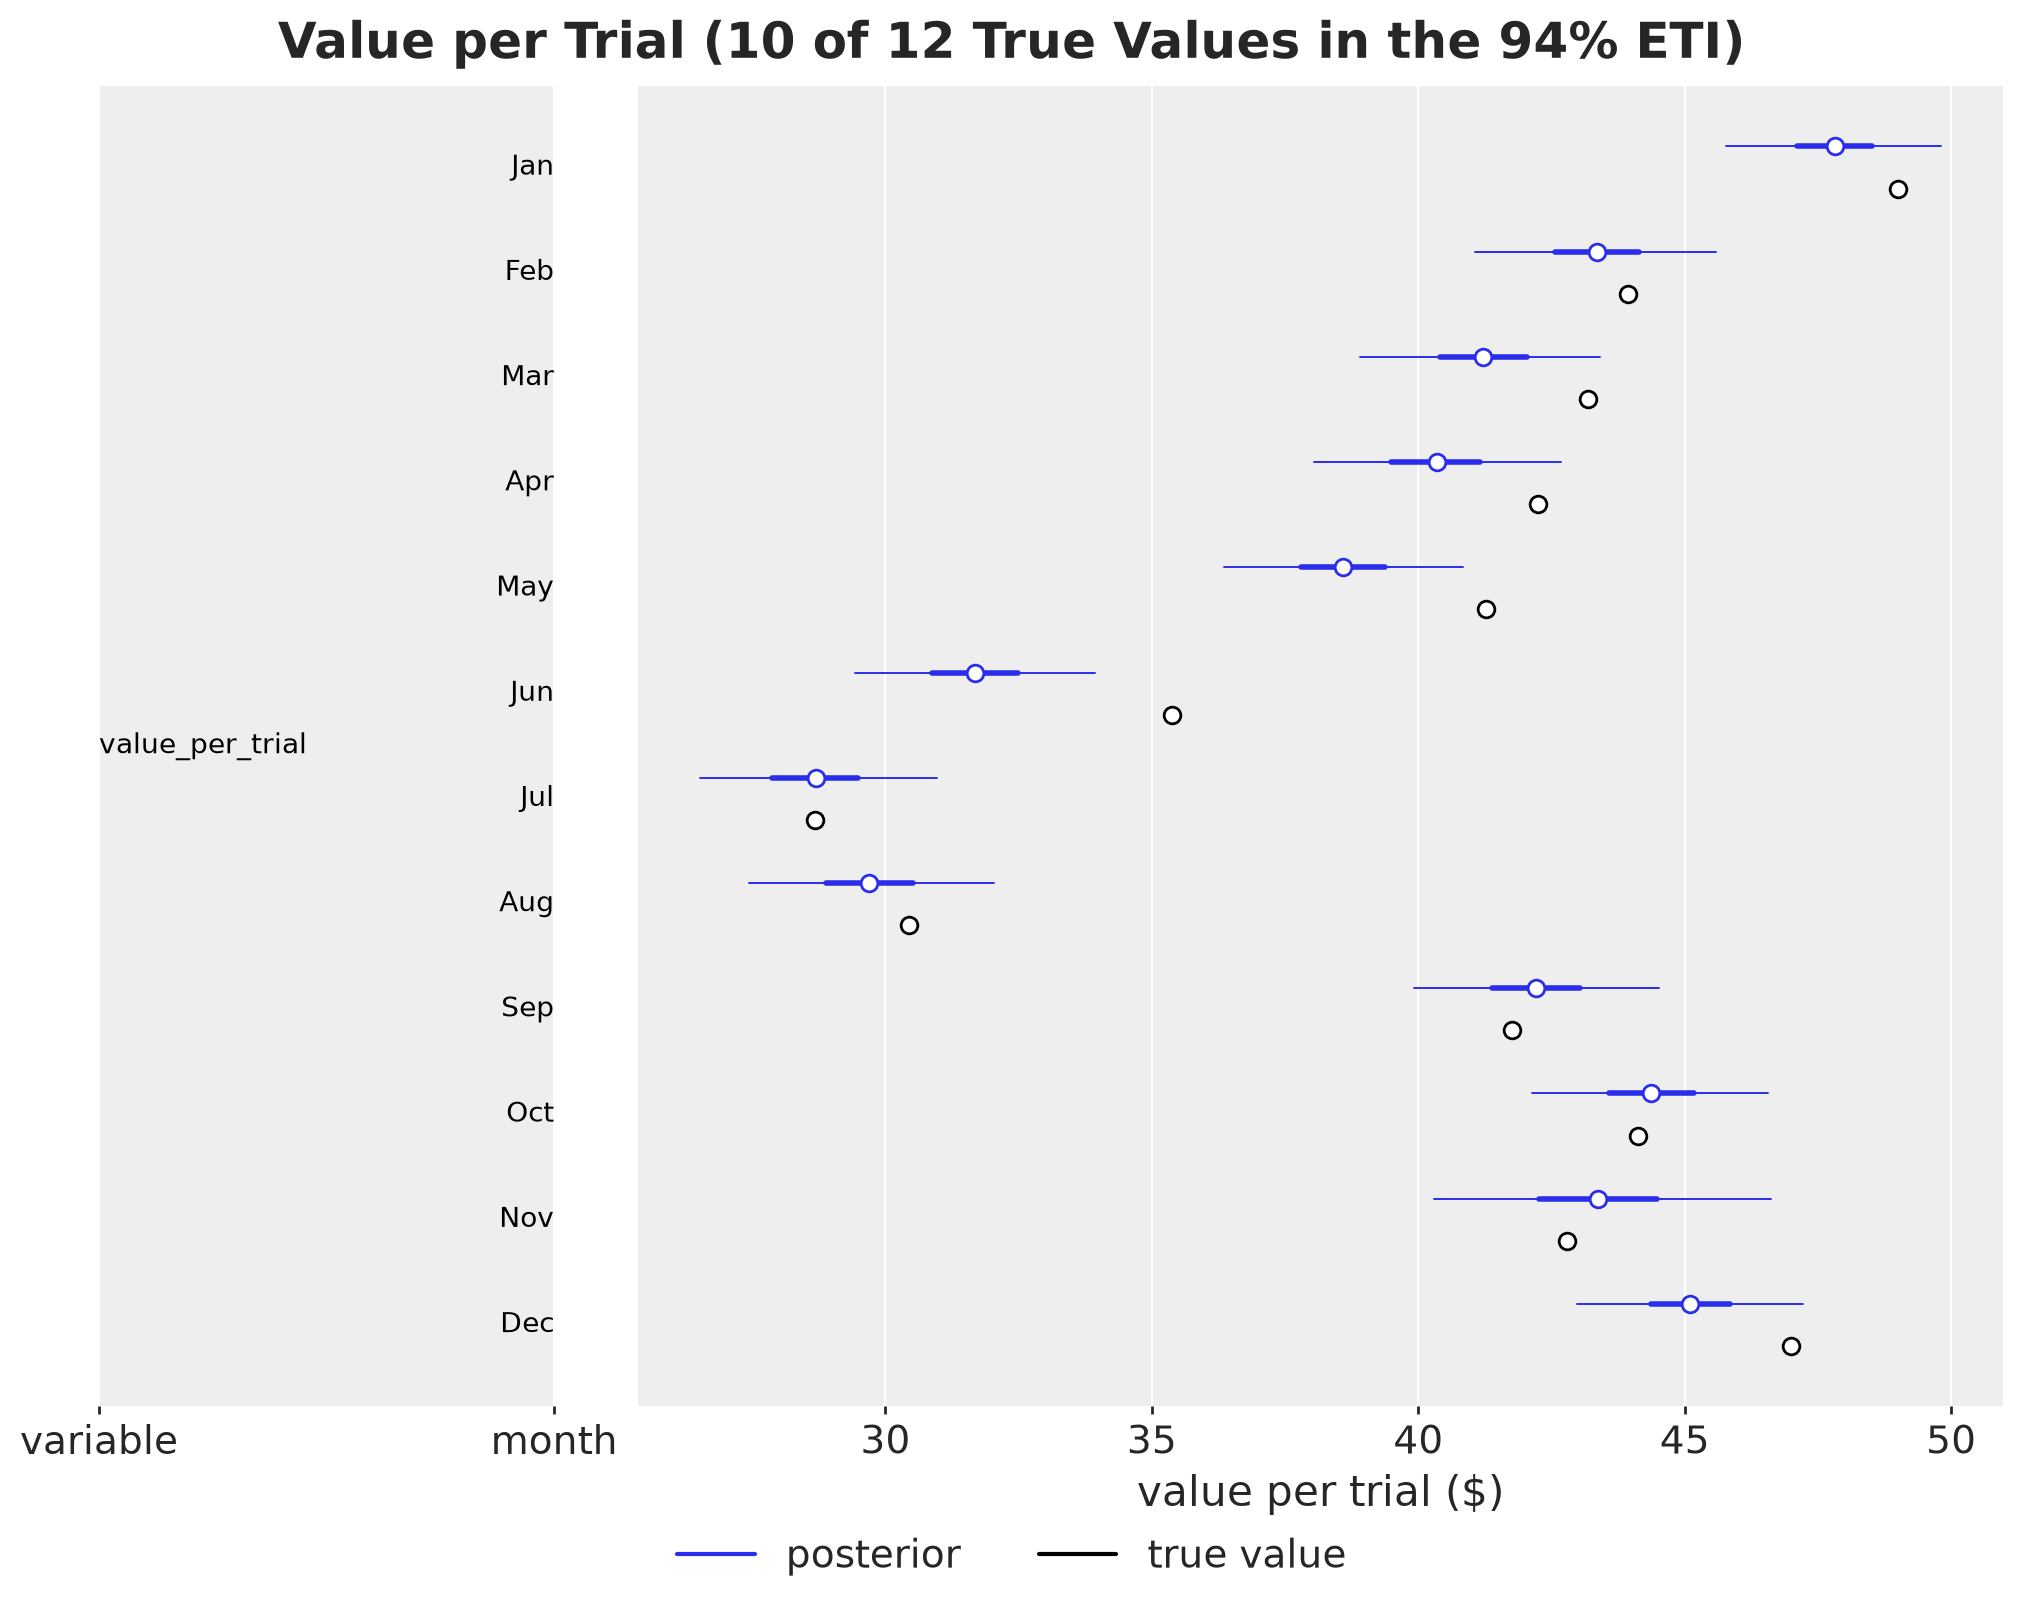

In [33]:
value_truth = truth_tree(
    {
        VALUE_PER_TRIAL: xr.DataArray(
            simulation.truth["value_per_trial"].values,
            dims="month",
            coords={"month": MONTHS},
        )
    },
    posterior=idata["posterior"],
)
value_covered = is_covered(
    idata["posterior"][VALUE_PER_TRIAL], simulation.truth["value_per_trial"].values
)

pc = az.plot_forest(
    {"posterior": idata, "true value": value_truth},
    var_names=[VALUE_PER_TRIAL],
    combined=True,
    color=["C0", "black"],
    figure_kwargs={"figsize": (10, 8)},
)
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["plot"].sel(column="forest").item().set(xlabel="value per trial ($)")
pc.viz["figure"].item().suptitle(
    f"Value per Trial ({value_covered.sum().item()} of {value_covered.size} True "
    f"Values in the {CI_PROB:.0%} ETI)",
    fontsize=18,
    fontweight="bold",
);

We read the figure as follows:

- **Season:** A trial that starts in July is worth about $\$29$, and a trial that starts in January about $\$48$. The summer trials are worth less because fewer of them convert.
- **Uncertainty:** The $94\%$ ETI of a month is about $\$4$ to $\$5$ wide, and about $\$6$ in November. Each calendar month has only four cohorts, and the model has to separate the season of the month from the effects of these cohorts. In November the promotion effects add their own uncertainty.
- **True values:** The true value lies inside the $94\%$ ETI in $10$ of the $12$ months, and the posterior is too low in May and June. The posterior mean is below the true value in $8$ of the $12$ months. One simulation with $12$ months cannot tell us whether these intervals are too narrow in general.

The value per trial describes the cohorts that have not started yet. Next, we turn to the cohorts that have.

## Cohort Forecasts

Let's now turn to the second quantity, the $24$-month revenue $R_c$ of each cohort. At the freeze we know the revenue of cohort $c$ up to its current age $a_c$, and the model draws the rest. We mark the draws of the future quantities with a tilde:

- **Lifetimes:** $\tilde{M}_{c,\ell}$ is the number of users of the monthly plan who are active at the freeze and leave $\ell$ months later. Its last entry counts the users who stay until the end of the horizon.
- **Survival:** $\bar{S}_c(a_c + \ell \mid a_c)$ is the probability that a user who is active at the freeze is still active $\ell$ months later, and $\bar{\pi}_{c,\ell}$ is the probability that the user leaves exactly $\ell$ months later.
- **Active users:** $\tilde{A}_{c,a}$ is the number of active users of the monthly plan at a future age $a$.
- **Renewals:** $\tilde{Q}_c$ is the number of renewals of a cohort that is younger than $12$ months. It is zero for an older cohort, whose renewal we have seen.
- **Payments:** $\tilde{B}_{c,k}$ is the number of future payments of plan $k$, and $\tilde{X}_{c,k}$ is their revenue.

Given the hazards, each active user leaves $\ell$ months later with probability $\bar{\pi}_{c,\ell}$, independently of the others. The counts of the users by $\ell$ are therefore Multinomial, as in the *Data Generating Process* section, and the active users that they imply have the same distribution as a Binomial draw in every month.

Recall that the sum of Gamma payments with the same rate is again a Gamma. The future part of the model is

$$
\begin{align*}
\bar{S}_c(a_c + \ell \mid a_c) & = \prod_{j=1}^{\ell} \left(1 - \bar{h}_c(a_c + j)\right) \\
\bar{\pi}_{c,\ell} & = \bar{S}_c(a_c + \ell - 1 \mid a_c) - \bar{S}_c(a_c + \ell \mid a_c) \\
\tilde{M}_c & \sim \text{Multinomial}\left(A_{c,a_c}, \bar{\pi}_c\right) \\
\tilde{A}_{c,a_c+j} & = A_{c,a_c} - \sum_{\ell \leq j} \tilde{M}_{c,\ell} \\
\tilde{Q}_c & \sim \text{Binomial}\left(N_{c,\text{yearly}}, \text{logit}^{-1}\left(\eta_0 + \eta_1 z_c + \bar{u}_{c,\text{renewal}}\right)\right) \quad \text{for } a_c < 12 \\
\tilde{B}_{c,\text{monthly}} & = \sum_{j} \tilde{A}_{c,a_c+j} \\
\tilde{B}_{c,\text{yearly}} & = \tilde{Q}_c \\
\tilde{X}_{c,k} & \sim \text{Gamma}\left(\tilde{B}_{c,k} \nu_k, \nu_k / \mu_k\right),
\end{align*}
$$

where the sums and the products run over the months that the cohort has left. The last entry of $\bar{\pi}_c$ is the probability $\bar{S}_c(H - 1 \mid a_c)$ to stay until the end of the horizon. The forecast of the revenue of a cohort is its revenue to date plus $\tilde{X}_{c,\text{monthly}} + \tilde{X}_{c,\text{yearly}}$.

These are the variables that `future_payments` and `future_revenue` add to the model. The function `forecast` of PyMC-Forecast draws them once for each posterior draw of the parameters, so each draw carries the uncertainty of the parameters and the randomness of the churn and of the payments.

We wrap it in the function `forecast_future`, and `cohort_revenue` adds the revenue to date. For the freeze of December 2024 we also keep the table `forecast` of the future active users, and we check it against the *Calendar Time* figure.

In [34]:
def forecast_future(
    idata: xr.DataTree,
    data: FunnelData,
    rng: np.random.Generator,
    var_names: list[str],
) -> xr.DataTree:
    """Posterior predictive draws of the future variables of the model."""
    return forecast(
        partial(funnel_model, data),
        idata,
        retained_table(data),
        forecast_months(data),
        var_names=var_names,
        random_seed=rng,
    )["predictions"]


def cohort_revenue(revenue_future: xr.DataArray, data: FunnelData) -> xr.DataArray:
    """Draws of the 24-month revenue of each cohort: to date plus future."""
    revenue_to_date = xr.DataArray(
        data.revenue_to_date, dims="cohort", coords={"cohort": data.cohort_labels}
    )
    return (revenue_to_date + revenue_future.sum("plan")).transpose(
        "chain", "draw", "cohort"
    )


predictions = forecast_future(
    idata, data, rng, var_names=[REVENUE_FUTURE, FORECAST_VAR]
)
cohort_revenue_forecast = cohort_revenue(predictions[REVENUE_FUTURE], data)
future_active = predictions[FORECAST_VAR]

assert np.allclose(
    cohort_revenue_forecast.isel(cohort=~data.is_open),
    data.revenue_to_date[~data.is_open],
)
assert (future_active.values[..., ~is_future[data.freeze + 1 :]] == 0).all()
assert (
    future_active.isel(time_future=0).values
    <= data.current_active[data.freeze + 1 - calendar.hazard_ages]
).all()

The first assertion checks that the forecast of a complete cohort is its revenue to date. The other two check the table of the future active users. It is zero outside the cells to forecast of the *Calendar Time* figure, and in the first future month no cohort has more active users than at the freeze.

Next, we plot the forecast of the open cohorts in two panels. The upper panel shows the revenue in dollars, with the revenue that we have seen so far and the true $24$-month revenue. The lower panel shows the same quantities divided by the true $24$-month revenue, so that we can see the size of the forecast error.

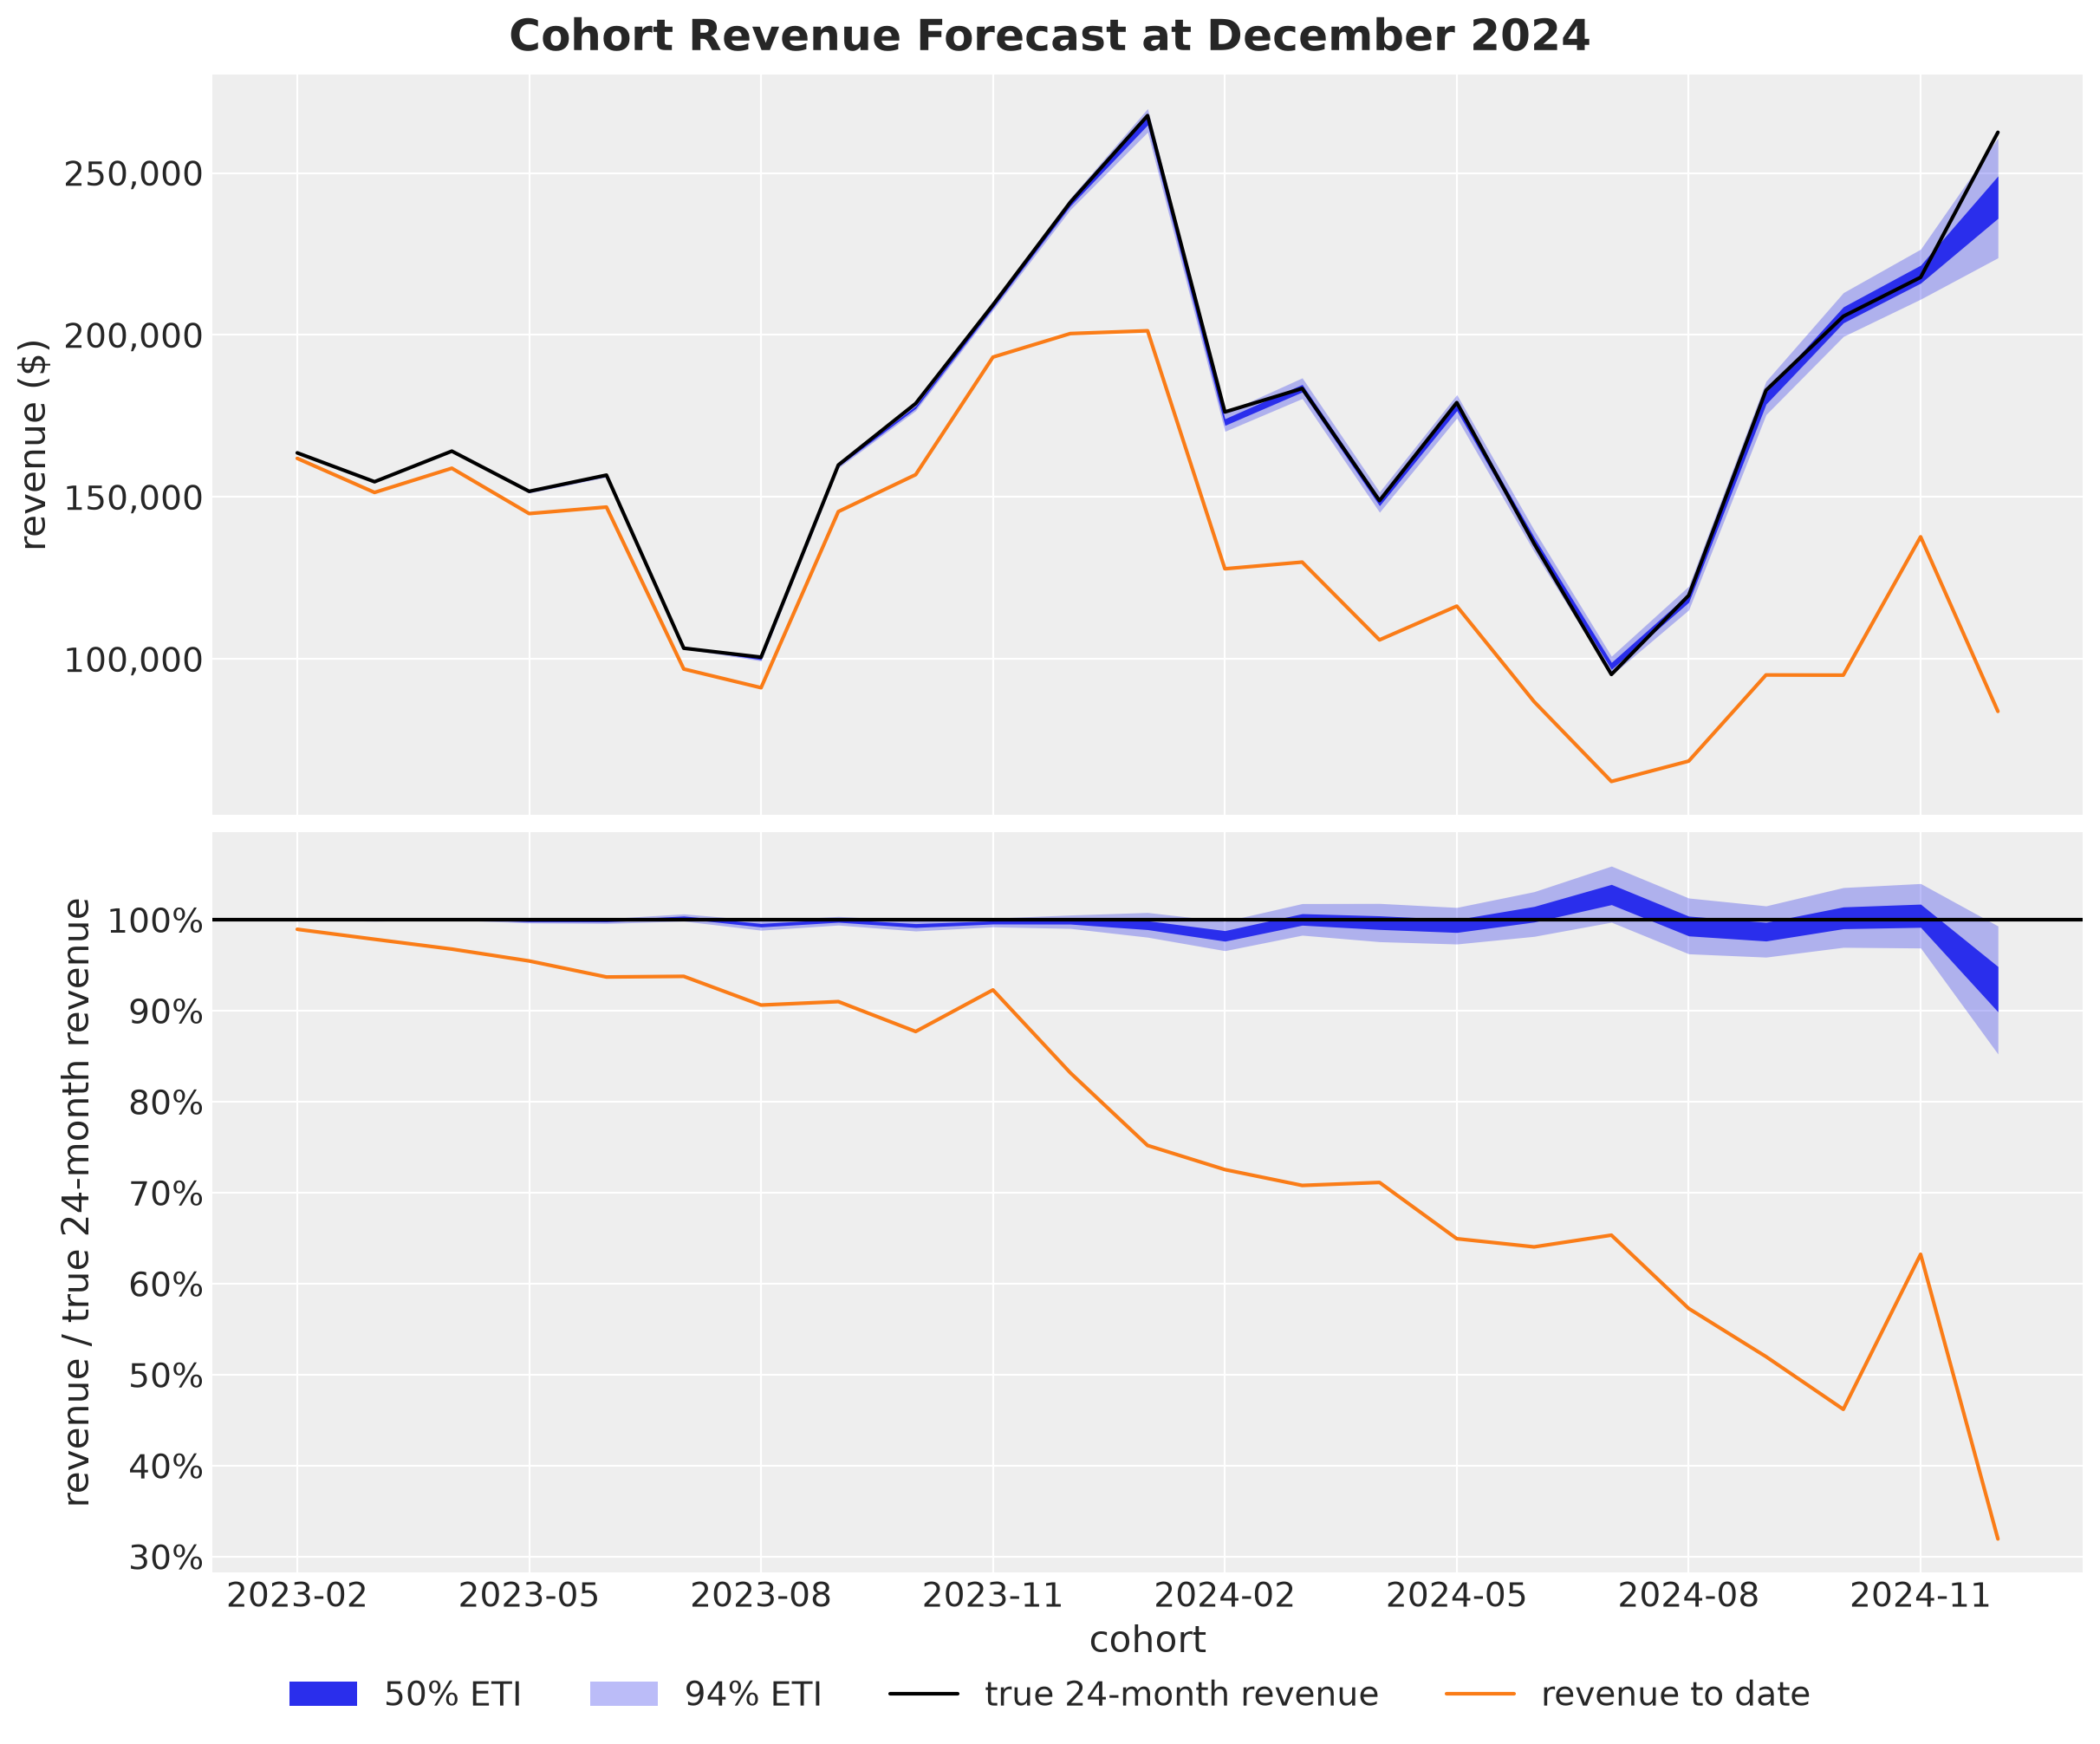

In [35]:
open_labels = np.array(data.cohort_labels)[data.is_open]
open_position = cohort_position[data.is_open]
true_revenue = xr.DataArray(
    simulation.cohort_revenue[: data.freeze + 1][data.is_open],
    dims="cohort",
    coords={"cohort": open_labels},
)
revenue_to_date = data.revenue_to_date[data.is_open]
forecast_open = cohort_revenue_forecast.sel(cohort=open_labels).transpose(
    "chain", "draw", "cohort"
)
forecast_tree = az.from_dict(
    {
        "posterior_predictive": {
            "revenue": forecast_open.values,
            "ratio": (forecast_open / true_revenue).values,
        },
        "observed_data": {
            "revenue": true_revenue.values,
            "ratio": np.ones(len(open_labels)),
        },
        "constant_data": {"x_revenue": open_position, "x_ratio": open_position},
    },
    coords={"cohort": open_labels},
    dims={
        "revenue": ["cohort"],
        "ratio": ["cohort"],
        "x_revenue": ["cohort"],
        "x_ratio": ["cohort"],
    },
)

pc = az.plot_lm(
    forecast_tree,
    x=["x_revenue", "x_ratio"],
    y=["revenue", "ratio"],
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    visuals={"ci_band": {"color": "C0"}, "observed_scatter": False, "pe_line": False},
    col_wrap=1,
    figure_kwargs={"figsize": (12, 10), "sharex": True, "sharey": False},
)
ax_revenue = pc.viz["plot"]["x_revenue"].item()
ax_ratio = pc.viz["plot"]["x_ratio"].item()
label_bands(pc.viz["ci_band"]["x_revenue"])
ax_revenue.plot(
    open_position, true_revenue.values, color="black", label="true 24-month revenue"
)
ax_revenue.plot(open_position, revenue_to_date, color="C1", label="revenue to date")
ax_revenue.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax_revenue.set(xlabel="", ylabel="revenue ($)", title="")
ax_ratio.axhline(1.0, color="black")
ax_ratio.plot(open_position, revenue_to_date / true_revenue.values, color="C1")
ax_ratio.set_xticks(open_position[::3], list(open_labels[::3]))
ax_ratio.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax_ratio.set(xlabel="cohort", ylabel="revenue / true 24-month revenue", title="")
pc.viz["figure"].item().legend(loc="outside lower center", ncol=4)
pc.viz["figure"].item().suptitle(
    "Cohort Revenue Forecast at December 2024", fontsize=18, fontweight="bold"
);

We can read the figure by the age of the cohorts:

- **Old cohorts:** For the cohorts of early 2023 almost all the revenue is in, and the forecast adds the last months.
- **Young cohorts:** For the cohorts of late 2024 between a third and two thirds of the revenue is still to come. The $94\%$ ETI of every cohort that has paid at least twice stays within about $6\%$ of its true revenue.
- **Youngest cohort:** The cohort `2024-12` has paid once. Its band is the widest, and it ends just below the true revenue. Recall from the *Parameter Recovery* section that the model expects more churn and a lower renewal for this cohort than it has.

One freeze cannot tell us how often the bands cover the truth, or whether a simpler method would do as well. We answer both questions in the next section.

## Backtest

We now replay the forecast at the end of every month of 2024. We refit the model on the data of each freeze and compare the forecast of every open cohort with its true $24$-month revenue.

This gives $12$ forecasts at every age between $0$ and $22$ months. Note that the same cohort appears in several freezes, so the forecasts are not independent.

We compare the funnel model with two references.

### Chain Ladder

The **chain ladder** method projects a cohort with the retention of the cohorts that came before it, without a model of the funnel. Actuaries use it to project claims triangles ([Mack 1993](https://doi.org/10.2143/AST.23.2.2005092)). We apply it to the active users of the monthly plan.

Let $\mathcal{O}_{a+1}$ be the set of cohorts that we observe at age $a + 1$. The **development factor** $d_a$ is the one-month retention at age $a + 1$, pooled over these cohorts. The forecast $\hat{A}_{c,a}$ of the active users of cohort $c$ at a future age $a$ multiplies its active users at its current age $a_c$ by the factors in between:

$$
d_a = \frac{\sum_{c' \in \mathcal{O}_{a+1}} A_{c',a+1}}{\sum_{c' \in \mathcal{O}_{a+1}} A_{c',a}}, \qquad \hat{A}_{c,a} = A_{c,a_c} \prod_{j=a_c}^{a-1} d_j.
$$

We complete this projection to a forecast $R^{\text{CL}}_c$ of the cohort revenue:

- **Promotion:** We compute the factors separately for the cohorts with and without the promotion, so the chain ladder accounts for the promotion as the model does. The factors of the promotion come from the few November cohorts.
- **Yearly plan:** The expected renewals of a cohort younger than $12$ months are its net starts of the yearly plan times the pooled renewal ratio of the older cohorts of its group.
- **Revenue:** We multiply the expected payments of each plan by the observed revenue per payment of that plan and add the revenue to date.

The chain ladder uses the retention of the older cohorts at every age. It does not use the conversion of a cohort, and it uses its first months of churn only through its current number of active users. The function `project_revenue` below turns one-month retentions and renewal probabilities into a revenue forecast, and `chain_ladder` calls it with the pooled ones.

In [36]:
def project_revenue(
    data: FunnelData,
    retention: np.ndarray,
    renewal: np.ndarray,
    revenue_per_payment: dict[Plan, float],
) -> np.ndarray:
    """Revenue to date plus the expected revenue of the payments still to come.

    `retention` holds the one-month retention by cohort and hazard age, and
    `renewal` the renewal probability by cohort.
    """
    is_future = calendar.hazard_ages[None, :] > data.current_age[:, None]
    still_active = np.cumprod(np.where(is_future, retention, 1.0), axis=1)
    monthly_payments = data.current_active * (still_active * is_future).sum(axis=1)
    yearly_payments = np.where(
        data.current_age < calendar.renewal_age,
        data.cohorts["n_starts_yearly"].to_numpy() * renewal,
        0.0,
    )
    return (
        data.revenue_to_date
        + revenue_per_payment[Plan.MONTHLY] * monthly_payments
        + revenue_per_payment[Plan.YEARLY] * yearly_payments
    )


def development_factors(active: np.ndarray) -> np.ndarray:
    """Pooled one-month retention by age, over the cohorts observed at that age."""
    observed = ~np.isnan(active[:, 1:])
    return np.where(observed, active[:, 1:], 0).sum(axis=0) / np.where(
        observed, active[:, :-1], 0
    ).sum(axis=0)


def chain_ladder(data: FunnelData) -> np.ndarray:
    """Chain ladder on the active users, with separate factors for the promotion."""
    promo = data.cohorts["promo"].to_numpy()
    n_yearly = data.cohorts["n_starts_yearly"].to_numpy()
    active = (
        data.payments.filter(pl.col("plan") == Plan.MONTHLY)
        .pivot(on="age", index="cohort", values="n_payments")
        .sort("cohort")
        .drop("cohort")
        .to_numpy()
        .astype(float)
    )
    n_renewed = (
        data.cohorts.select("cohort")
        .join(data.renewals.select("cohort", "n_payments"), on="cohort", how="left")
        .sort("cohort")["n_payments"]
        .to_numpy()
        .astype(float)
    )
    retention = np.empty((len(promo), len(calendar.hazard_ages)))
    renewal = np.empty(len(promo))

    for flag in np.unique(promo):
        group = promo == flag
        has_renewed = group & ~np.isnan(n_renewed)
        retention[group] = development_factors(active[group])
        renewal[group] = n_renewed[has_renewed].sum() / n_yearly[has_renewed].sum()

    totals = data.payments.group_by("plan").agg(
        pl.col("revenue").sum() / pl.col("n_payments").sum()
    )
    revenue_per_payment = dict(zip(totals["plan"], totals["revenue"], strict=True))
    return project_revenue(data, retention, renewal, revenue_per_payment)


complete = ~data.is_open

assert np.allclose(chain_ladder(data)[complete], data.revenue_to_date[complete])

The assertion checks that the chain ladder leaves a complete cohort at its revenue to date.

### Forecast with the True Parameters

The second reference is not a method that we could use in practice. It is the forecast that we would make if we knew the true hazard, the true renewal probability and the true revenue per payment of every cohort: the revenue to date plus the expected revenue of the payments that are still to come.

Its error comes from the randomness of the churn and of the payments alone. It therefore shows how much of the error of a method a better estimate of the parameters could remove.

Keep the following in mind:

- **Unobservable effects:** This forecast uses the churn effect and the renewal effect of a cohort that has made only its first payment. Nobody can observe them at that age, so no method can reach this forecast for the youngest cohorts.
- **A reference on average:** No forecast has a smaller expected squared error. At a single age, with $12$ forecasts, the absolute error of a method can still fall below it.

The function `true_parameter_forecast` passes the true hazards, the true renewal probabilities and the true revenue per payment to `project_revenue`, the projection that the chain ladder uses as well.

In [37]:
def true_parameter_forecast(simulation: Simulation, data: FunnelData) -> np.ndarray:
    """Expected revenue under the true hazard and renewal probability of each cohort."""
    truth = simulation.truth.sel(cohort=data.cohort_labels)
    revenue_per_payment = dict(
        zip(Plan, np.exp(TRUE_PARAMS["log_revenue_per_payment"]), strict=True)
    )
    return project_revenue(
        data,
        retention=1 - truth["true_hazard"].transpose("cohort", "hazard_age").values,
        renewal=truth["true_renewal_probability"].values,
        revenue_per_payment=revenue_per_payment,
    )

### Results

We score every forecast with its absolute error. The point forecast of the funnel model is the posterior median of the cohort revenue, which is the point forecast with the smallest expected absolute error.

To compare ages with cohorts of different sizes, we divide the sum of the absolute errors at each age by the sum of the true revenues. For the funnel model we also record whether the $94\%$ ETI covers the true value.

We now run the backtest. It refits the model at every freeze, including December 2024, and the assertions check that every fit clears the diagnostic bars of the *Model Fitting* section and that every age has one forecast per freeze.

In [38]:
class Method(StrEnum):
    FUNNEL_MODEL = "funnel model"
    CHAIN_LADDER = "chain ladder"
    TRUE_PARAMETERS = "true parameters"


class Backtest(NamedTuple):
    """Scores of the open cohorts at several freezes, and the checks of the fits."""

    scores: pl.DataFrame
    checks: list[SamplerCheck]


def score_freeze(
    simulation: Simulation,
    data: FunnelData,
    idata: xr.DataTree,
    rng: np.random.Generator,
) -> pl.DataFrame:
    """Absolute errors and coverage for the open cohorts at one freeze."""
    truth = simulation.cohort_revenue[: data.freeze + 1]
    revenue_draws = cohort_revenue(
        forecast_future(idata, data, rng, var_names=[REVENUE_FUTURE])[REVENUE_FUTURE],
        data,
    )
    return pl.DataFrame(
        {
            "current_age": data.current_age,
            "truth": truth,
            Method.FUNNEL_MODEL: np.abs(
                revenue_draws.median(("chain", "draw")).values - truth
            ),
            Method.CHAIN_LADDER: np.abs(chain_ladder(data) - truth),
            Method.TRUE_PARAMETERS: np.abs(
                true_parameter_forecast(simulation, data) - truth
            ),
            "covered": is_covered(revenue_draws, truth).values,
        }
    ).filter(pl.Series(data.is_open))


def run_backtest(
    simulation: Simulation, freezes: list[int], rng: np.random.Generator
) -> Backtest:
    """Refit the model at every freeze and score the forecasts of the open cohorts."""
    scores, checks = [], []

    for freeze in freezes:
        data = simulation.observe(freeze)
        result = fit(data, rng)
        scores.append(score_freeze(simulation, data, result.idata, rng))
        checks.append(result.check)

    return Backtest(scores=pl.concat(scores), checks=checks)


BACKTEST_FREEZES: Final[list[int]] = [
    calendar.cohort_labels.index(f"2024-{month:02d}") for month in range(1, 13)
]

backtest = run_backtest(simulation, BACKTEST_FREEZES, rng)

assert all(check.passed for check in backtest.checks)
assert (
    backtest.scores.group_by("current_age").len()["len"] == len(BACKTEST_FREEZES)
).all()

Now let's compare the errors and the coverage by the age of the cohort at the freeze.

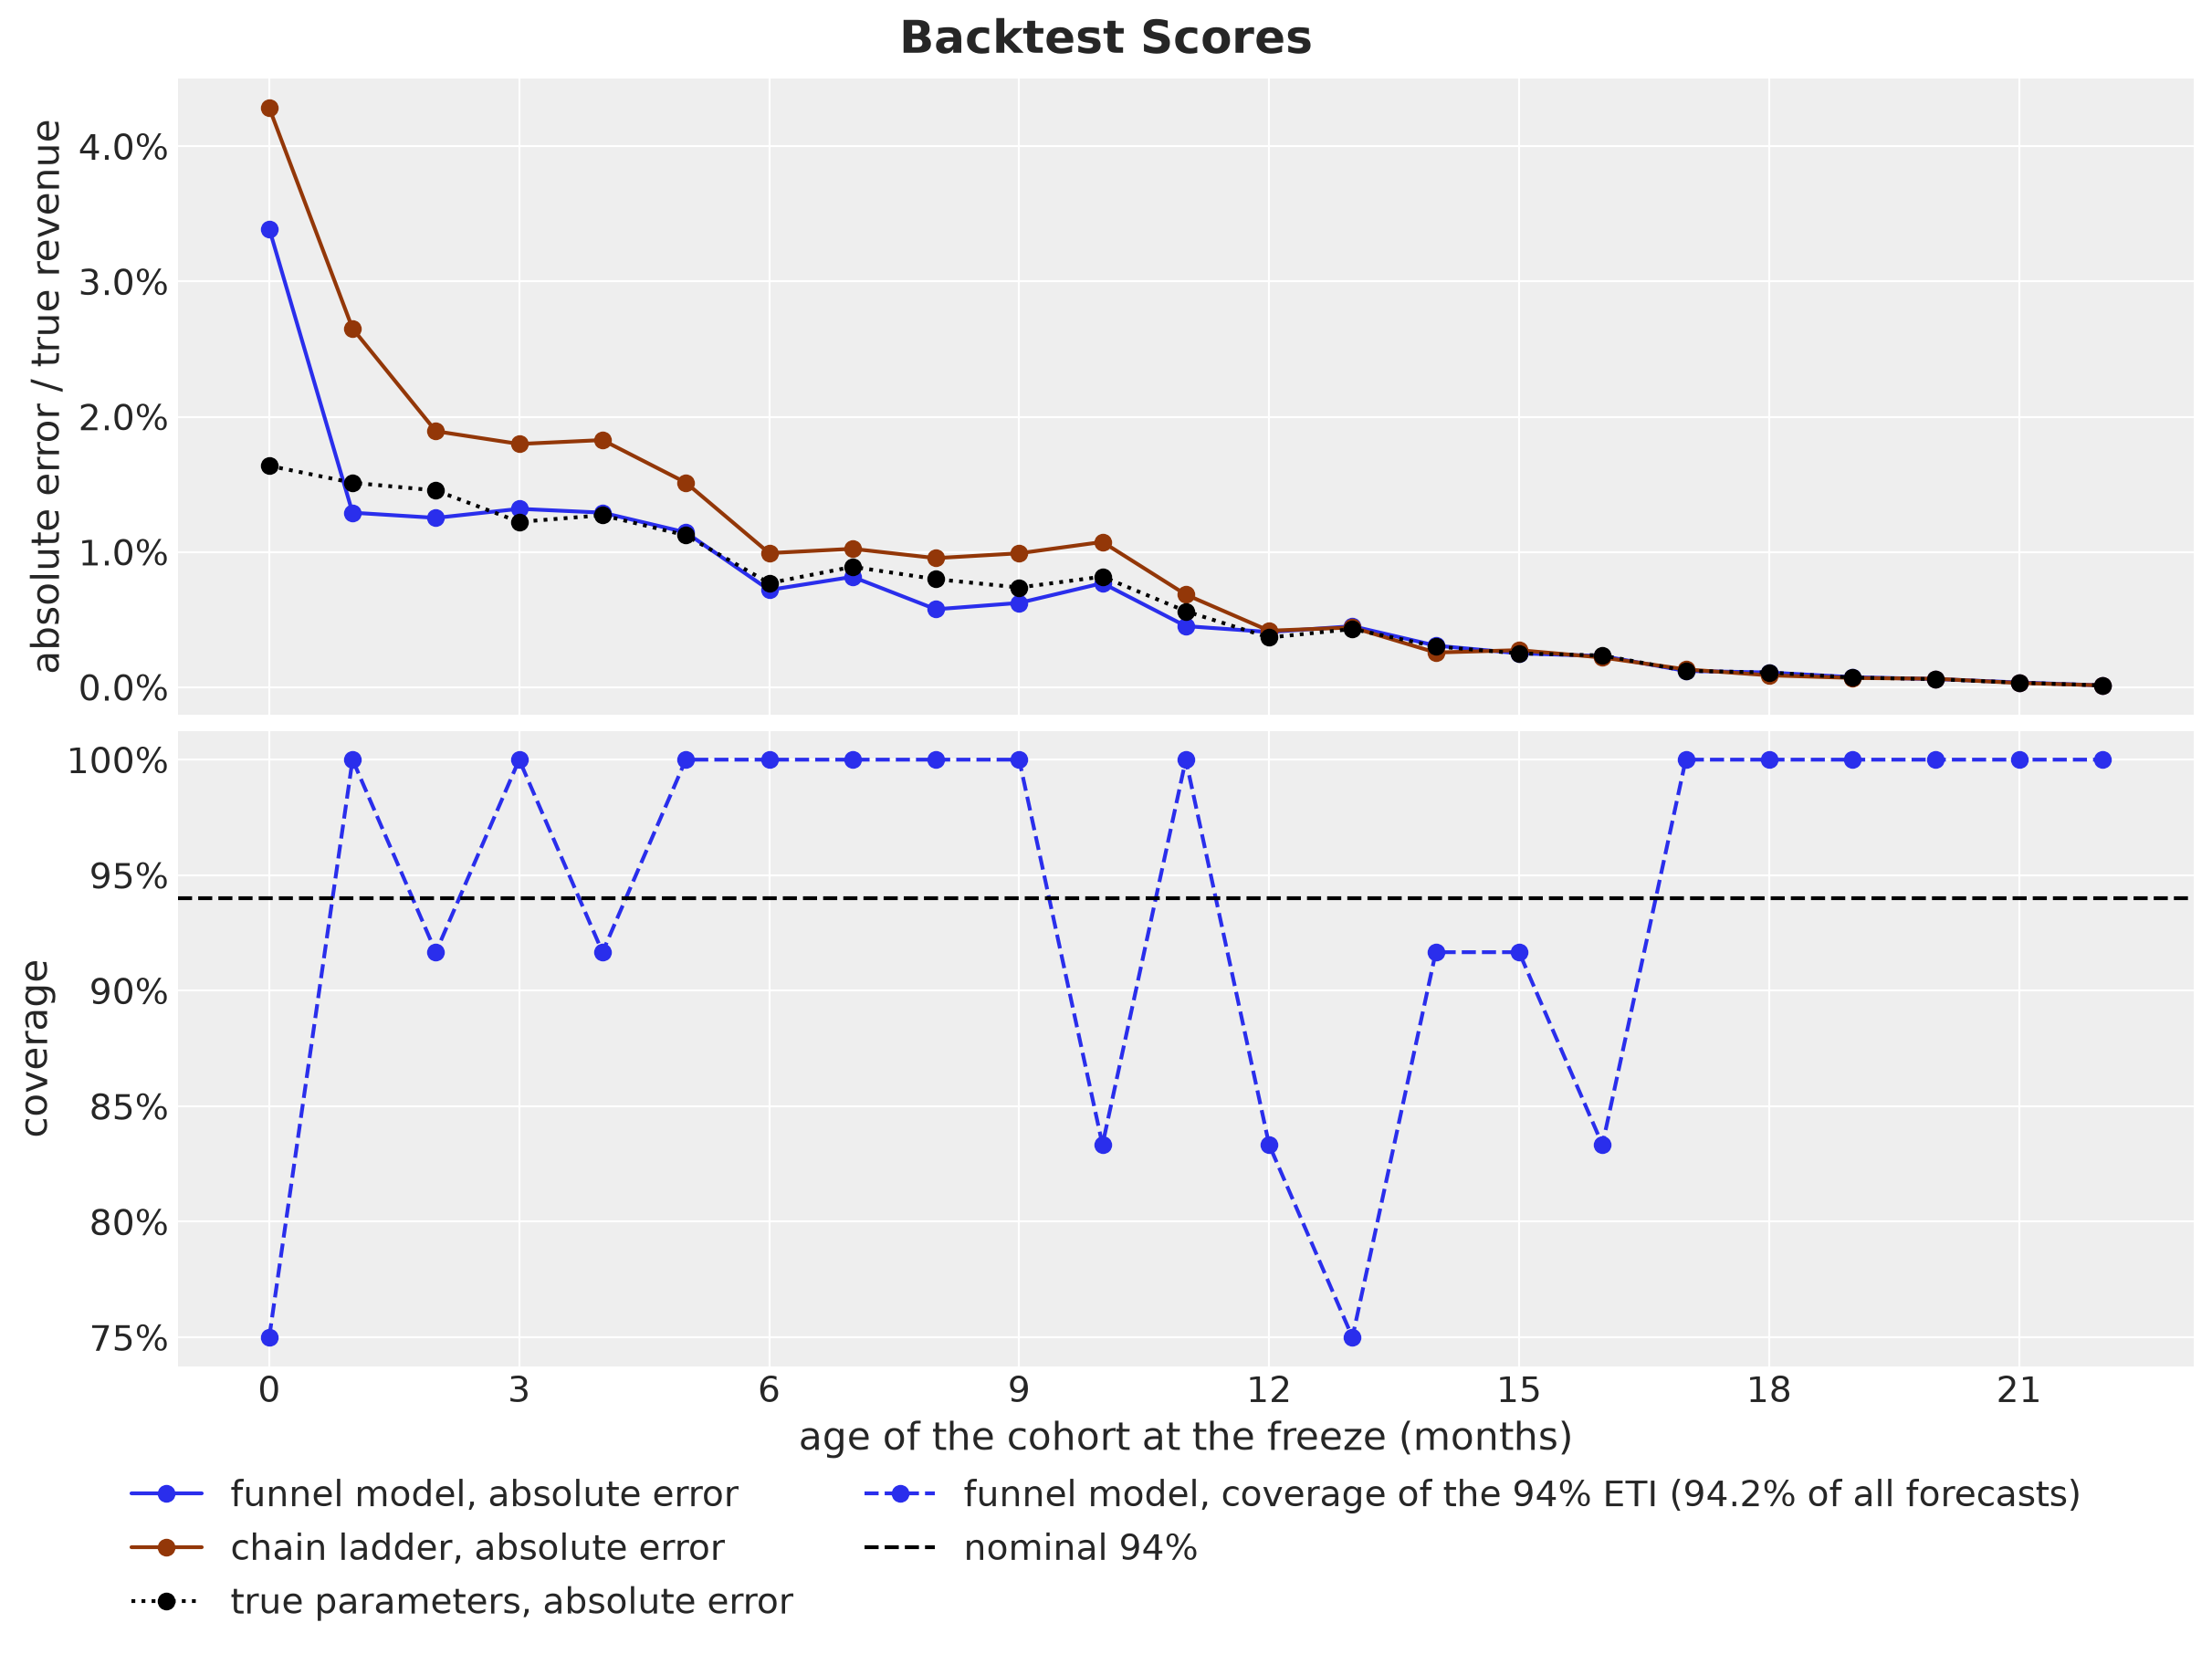

In [39]:
METHOD_STYLES: Final[dict[Method, dict[str, str]]] = {
    Method.FUNNEL_MODEL: {"color": "C0", "linestyle": "-"},
    Method.CHAIN_LADDER: {"color": "C4", "linestyle": "-"},
    Method.TRUE_PARAMETERS: {"color": "black", "linestyle": ":"},
}


def plot_scores(scores: pl.DataFrame) -> plt.Figure:
    """Absolute error over true revenue and coverage, by the age at the freeze."""
    by_age = (
        scores.group_by("current_age")
        .agg(
            pl.col("covered").mean().alias("coverage"),
            *[pl.col(method).sum() / pl.col("truth").sum() for method in Method],
        )
        .sort("current_age")
    )
    fig, axes = plt.subplots(
        nrows=2, ncols=1, figsize=(12, 9), sharex=True, layout="constrained"
    )
    ax = axes[0]

    for method in Method:
        ax.plot(
            by_age["current_age"],
            by_age[method],
            marker="o",
            label=f"{method}, absolute error",
            **METHOD_STYLES[method],
        )

    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
    ax.set(ylabel="absolute error / true revenue")
    ax = axes[1]
    ax.plot(
        by_age["current_age"],
        by_age["coverage"],
        marker="o",
        color="C0",
        linestyle="--",
        label=f"{Method.FUNNEL_MODEL}, coverage of the {CI_PROB:.0%} ETI "
        f"({scores['covered'].mean():.1%} of all forecasts)",
    )
    ax.axhline(CI_PROB, color="black", linestyle="--", label=f"nominal {CI_PROB:.0%}")
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set(xlabel="age of the cohort at the freeze (months)", ylabel="coverage")
    fig.legend(loc="outside lower center", ncol=2)
    return fig


fig = plot_scores(backtest.scores)
fig.suptitle("Backtest Scores", fontsize=18, fontweight="bold");

Let's go through the ages:

- **Age $0$:** A cohort that has paid once is the hardest to forecast. The error of the funnel model is about $3.4\%$ of the revenue, against about $4.3\%$ for the chain ladder. Both are far above the error with the true parameters, which uses the churn effect and the renewal effect that nobody can observe at that age.
- **Ages $1$ to $11$:** The error of the funnel model is below the one of the chain ladder at every age. At most of these ages it is also below the error with the true parameters. This is noise of the $12$ dependent forecasts per age, and it does not repeat on the other draws of the *Appendix*.
- **Ages $12$ and above:** The three errors are almost equal. At these ages the yearly plan has renewed, and only the last payments of the monthly plan remain.
- **Coverage:** The $94\%$ ETI covers the true revenue in $94.2\%$ of all the forecasts. By age the coverage moves between $75\%$ and $100\%$, which is $9$ to $12$ of the $12$ forecasts.
- **Coverage by age:** The coverage is lowest at age $0$ and at age $13$, and it stays below the nominal level from age $12$ to age $16$. A run like this is consistent with one or two cohorts whose interval misses at several freezes in a row.

The funnel model and the chain ladder see the same payments. The funnel model also uses the conversion of a cohort, the level of its first months of churn and the season of the churn, while the chain ladder gives every cohort the retention of the older ones. The lower error of the funnel model at the young ages is consistent with this extra information.

These results come from one simulation, and the $12$ freezes share most of their cohorts. In the *Appendix* we repeat the backtest on other draws of the generator.

There the funnel model stays ahead of the chain ladder at the ages $1$ to $11$. At age $0$ the two methods are close, and the intervals cover every forecast at that age, so neither the gap nor the low coverage at age $0$ repeats.

## Conclusion

In this notebook we built a model of the funnel of a subscription app, with one GLM per step and correlated cohort effects that connect the conversion, the churn and the renewal. We used it to estimate the value of a trial by start month and to forecast the $24$-month revenue of every cohort.

On our synthetic data the model recovers the hazard of the cohorts. In the backtest its forecast of the cohorts between $1$ and $11$ months old has a lower error than the chain ladder on the active users, in the main simulation and in the *Appendix* 🙌. For the cohorts that have paid once the two backtests do not agree, and for the older cohorts the two methods are almost equal.

### Key Findings

- **Survivor selection:** A cohort loses its high-churn users first, so its hazard falls with age even when no user changes. A churn rate from the first months understates the value of a user, and the age effect of a hazard model should be free to follow the shape that the older cohorts show.
- **Fading of persistent effects:** A difference between cohorts that lasts their whole life, such as a promotion or the quality of the users, fades from the hazard of the cohort as its high-churn users leave. A model of the hazard of a cohort should let such effects fade.
- **Population-averaged parameters:** The parameters of a model of cohorts describe the cohort. They are smaller than the parameters of a model of users, so we check them through the quantities that they imply, such as the hazard of a cohort and the value per trial.
- **Shared cohort effects:** When several steps of a funnel share a cohort effect, a joint model can use the steps that a young cohort has reached to forecast the ones that it has not. How much this helps depends on the correlation $\Omega$ between the steps, since the standard deviation of an effect that we have not seen falls by the factor $\sqrt{1 - \Omega^2}$.
- **A reference with the true parameters:** With synthetic data we can compute the forecast with the true parameters. It shows how much of the error of a method is left to remove, and at which ages two methods are almost equal.

### Model Limitations

- **Promotion and November:** The promotion runs every November, so we cannot separate its effect from a November effect without an assumption, and the model cannot tell us what happens if we move or drop the promotion.
- **Correlation by construction:** At age $0$ the funnel model knows the conversion of a cohort and nothing else about it. Its gain there in the main simulation is consistent with the correlation between the conversion and the later steps, which we put into the generator, but the other draws of the *Appendix* do not confirm it. With real data this correlation has to be estimated, and it can be weak.
- **Cohort effects in three steps:** The plan choice and the refunds have no cohort effect, neither in the generator nor in the model. In real data they vary from cohort to cohort as well, and the intervals of the value per trial would be wider. The cohort effects are also independent from one cohort to the next, so the model cannot follow a drift of the quality.
- **Additive season:** The generator shifts the hazard of each user with the season, while the model adds one seasonal effect at every age. The residuals show no pattern here, but a stronger season could leave one.
- **Stable funnel:** Apart from the cohort effects, the rates of the funnel do not change across cohorts. A product change that lowers the churn of all later cohorts needs an effect that changes over time.
- **Simple baseline:** The chain ladder uses neither the conversion of a cohort, nor the level of its first months of churn, nor the season of the churn. A baseline with regression adjustments for them uses the same data as the funnel model, and we do not compare with it here.
- **Average trial and expected value:** The value per trial averages over all the trials of a month, and its interval is the uncertainty of this average. The value of one more trial and the spread of the revenue of a single cohort are different quantities.
- **Gross revenue:** We ignore app store fees, variable costs and the time value of money.
- **Four cohorts per calendar month:** The value per trial of a month rests on the four cohorts that started in it. Here its interval missed the true value in $2$ of the $12$ months, and one simulation cannot tell us whether its intervals are too narrow in general.
- **Simulations from one generator:** The model has the same structure as the generator in most steps. The coverage of its intervals therefore checks the implementation, and it does not tell us how well the model fits real data.

### Recommendations

1. **Backtest on your own data.** Replay the forecast at past freezes and compare it with the chain ladder on the active users before you use the value per trial to set bids.
2. **Look for the quality in the data.** Plot the deviations of the conversion, the churn and the renewal of your cohorts against each other, as in the *Exploratory Data Analysis* section, before you rely on the correlations.
3. **Read the residuals by cohort and age.** A pattern along the ages points to the age effect or the fading, and a pattern along the diagonals points to a missing calendar effect.
4. **Turn the value into a margin.** Subtract the store fees and the variable costs, and discount the revenue of the later months, before you set a maximum cost per trial.
5. **Test the promotion.** If the promotion matters for your planning, run it for a random part of the November traffic, so that its effect no longer depends on the assumption about November.

## Next Steps

1. **Drift of the quality.** Let the cohort effects follow a random walk over the cohorts, so that the model can follow slow changes of the product and of the traffic.
2. **Cohort effects in every step.** Add partially pooled cohort effects to the plan choice and the refunds, and see how much wider the intervals of the value per trial become.
3. **Plan changes.** Model the switches between the monthly and the yearly plan with a multi-state model.
4. **Users instead of cohorts.** When we have data on each user, fit an sBG model with covariates on the churn probability of each user and compare it with the model of cohorts.

## Appendix

### Replication on Other Draws

The backtest of the main text uses one simulation. Here we repeat it on $6$ other draws of the generator, with the same true parameters.

We freeze each draw at $3$ months of 2024, $4$ months apart, and we shift the months from one draw to the next, so that every calendar month occurs as the start month of a youngest cohort. Then we pool the forecasts of the $6$ draws and plot the scores as in the *Backtest* section, now with $18$ forecasts at every age.

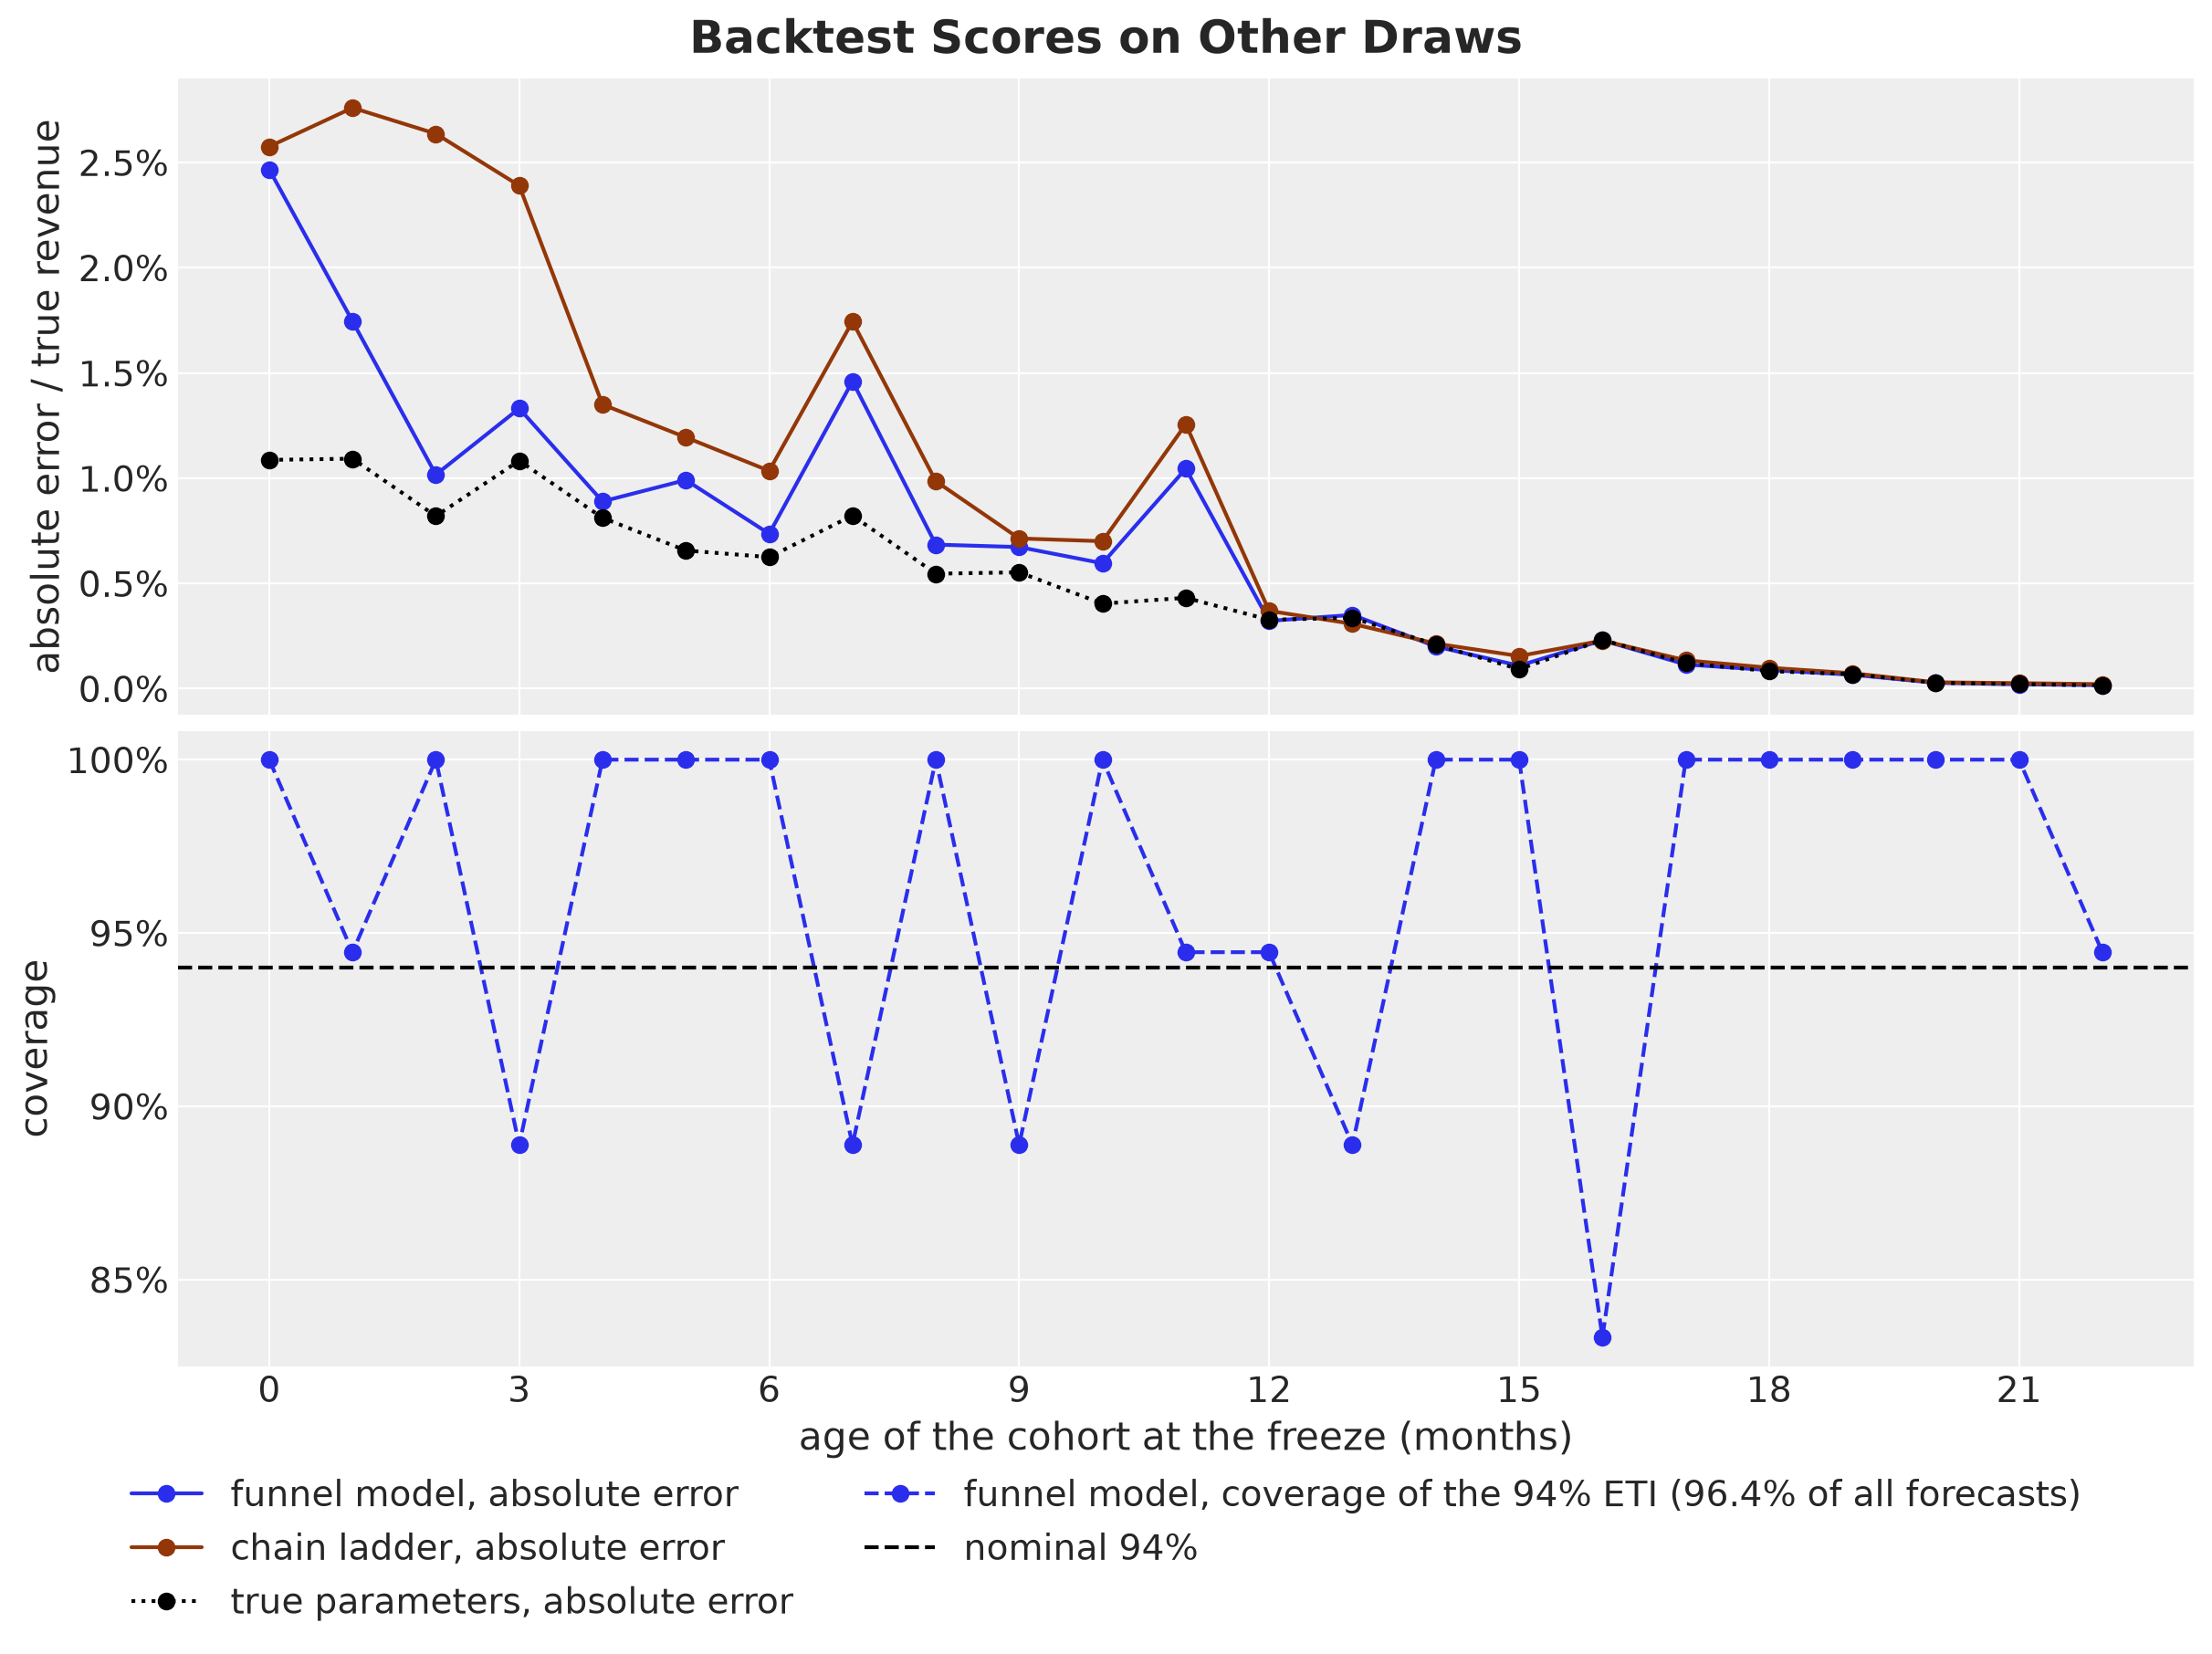

In [40]:
N_OTHER_DRAWS: Final[int] = 6

other_draws = pm.sample_prior_predictive(
    draws=N_OTHER_DRAWS, model=pm.do(generator, TRUE_PARAMS), random_seed=rng
)["prior"].dataset.isel(chain=0)
other_backtests = [
    run_backtest(
        make_simulation(other_draws.isel(draw=i)), BACKTEST_FREEZES[i % 4 :: 4], rng
    )
    for i in range(N_OTHER_DRAWS)
]

assert all(check.passed for result in other_backtests for check in result.checks)

fig = plot_scores(pl.concat([result.scores for result in other_backtests]))
fig.suptitle("Backtest Scores on Other Draws", fontsize=18, fontweight="bold");

On the other draws the funnel model stays ahead of the chain ladder for the cohorts between $1$ and $11$ months old:

- **Age $0$:** The two errors are close, about $2.5\%$ for the funnel model against about $2.6\%$ for the chain ladder. The gap is much smaller than in the main simulation. With $18$ forecasts here and $12$ in the main backtest, the two backtests cannot settle the size of the gain at this age.
- **Ages $1$ to $11$:** The funnel model is below the chain ladder at every age. The error with the true parameters is below the one of the funnel model at each of these ages. The gap between the two is the error that comes from not knowing the parameters and the effects of a cohort.
- **Ages $12$ and above:** The three errors are almost equal.
- **Coverage:** The $94\%$ ETI covers the true revenue in $96.4\%$ of the $414$ forecasts ($18 \times 23$), and in all the $18$ forecasts at age $0$.

All the draws share the true parameters of the main simulation. The replication supports the gain of the funnel model for the cohorts between $1$ and $11$ months old, and it says nothing about other values of the correlations.

## References

- Allison, P. D. (1982). [Discrete-Time Methods for the Analysis of Event Histories](https://doi.org/10.2307/270718). *Sociological Methodology*, 13, 61-98.
- Fader, P. S. and Hardie, B. G. S. (2007). [How to Project Customer Retention](https://doi.org/10.1002/dir.20074). *Journal of Interactive Marketing*, 21(1), 76-90.
- Lewandowski, D., Kurowicka, D. and Joe, H. (2009). [Generating Random Correlation Matrices Based on Vines and Extended Onion Method](https://doi.org/10.1016/j.jmva.2009.04.008). *Journal of Multivariate Analysis*, 100(9), 1989-2001.
- Mack, T. (1993). [Distribution-Free Calculation of the Standard Error of Chain Ladder Reserve Estimates](https://doi.org/10.2143/AST.23.2.2005092). *ASTIN Bulletin*, 23(2), 213-225.
- Vaupel, J. W., Manton, K. G. and Stallard, E. (1979). [The Impact of Heterogeneity in Individual Frailty on the Dynamics of Mortality](https://doi.org/10.2307/2061224). *Demography*, 16(3), 439-454.
- Zeger, S. L., Liang, K.-Y. and Albert, P. S. (1988). [Models for Longitudinal Data: A Generalized Estimating Equation Approach](https://doi.org/10.2307/2531734). *Biometrics*, 44(4), 1049-1060.